<a href="https://colab.research.google.com/github/farrelrassya/Build-a-Large-Language-Model-From-Scratch/blob/main/07.Fine_Tuning_To_Follow_Instructions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Chapter 7 -- Fine-tuning to Follow Instructions

*Companion notebook untuk* Build a Large Language Model (From Scratch) *(Sebastian Raschka, Manning 2024)*
**Technical edition -- kode buku plus beberapa pengukuran tambahan**

Notebook ini berisi semua kode bab 7, dalam urutan buku. Di beberapa titik ada pengukuran tambahan yang tidak ada di buku, untuk menjawab pertanyaan "apa yang sebenarnya terjadi di sini?". Bagian-bagian itu diberi judul **Under the hood** dan boleh dilewati kalau hanya ingin mengikuti materi buku. Sel tambahan lain, yang menjaga notebook tetap bisa dijalankan di berbagai mesin, ditandai komentar "Sel tambahan" di baris pertamanya.

| Under the hood | Yang kita ukur | Hasil |
|---|---|---|
| 1. Collate function | Seberapa hemat padding per batch, dan target apa saja yang ikut dihitung loss | Padding 2.6x lebih sedikit; dua pertiga target ternyata teks prompt |
| 2. Anatomi loss | Bagian teks mana yang benar-benar dipelajari saat fine-tuning | Pembuka template dihafal total; teks instruksi ikut dipelajari |
| 3. Belajar berhenti | Apakah model tahu kapan sebuah jawaban selesai | Peluang memilih token akhir sesudah jawaban acuan naik dari 2% ke 96% |
| 4. Kalibrasi juri | Seberapa bisa dipercaya skor dari LLM juri | Belum ada angka: dimatikan di run ini (`RUN_ALT_JUDGE = False`) dan butuh server Ollama |

Sampai Chapter 6 kita sudah membangun GPT dari nol, melatihnya, memuat bobot OpenAI ke dalamnya, dan mengubahnya menjadi classifier spam. Satu kemampuan masih belum ada: diberi perintah, model belum bisa mengerjakannya. Model pretrained hanya mengenal satu permainan, yaitu menebak token berikutnya. Kalau kita menulis "ubah kalimat ini menjadi pasif", ia tidak melihat sebuah perintah. Ia melihat awal sebuah dokumen, lalu menebak bagaimana dokumen seperti itu biasanya berlanjut. Sebentar lagi kita akan melihatnya sendiri: GPT-2 medium yang belum di-fine-tune menanggapi perintah semacam itu dengan mengulang kalimatnya, lalu menyalin ulang perintahnya.

Bab ini menutup celah itu dengan *instruction fine-tuning*, yaitu melatih ulang model dengan contoh-contoh instruksi beserta jawaban yang diinginkan. Yang menarik, tidak ada mekanisme baru di sini. Fungsi loss-nya sama dengan pretraining, dan loop training-nya sama dengan Chapter 5. Yang berubah hanya teks yang kita sodorkan dan cara kita menyusunnya menjadi batch -- dan ternyata justru di situ sebagian besar keputusan penting bab ini berada.

Pekerjaannya berjalan dalam tiga tahap yang akan terus kita pakai sebagai peta: menyiapkan dataset, melatih model, lalu menilai jawaban yang dihasilkannya. Tahap terakhir menyimpan pelajaran yang paling mudah terlewat: model yang sudah rapi mengikuti format belum tentu menjawab dengan benar.

## Setup

Notebook ini dibuat untuk dijalankan dengan *Run all* di Google Colab memakai GPU T4 (*Runtime > Change runtime type > T4 GPU*). Output yang tersimpan di sini berasal dari satu kali run seperti itu, sekitar 17 menit dari sel pertama sampai terakhir. Dua hal tidak menghasilkan angka di run ini: skor dari LLM juri, karena server Ollama tidak berjalan, dan training ulang untuk latihan.

Sel pertama memasang paket yang belum ada. Sel kedua menyimpan pilihan run, misalnya `RUN_EXERCISES` untuk ikut melatih tiga varian latihan, atau `USE_GOOGLE_DRIVE` supaya checkpoint training tetap ada kalau runtime Colab di-reset.

In [ ]:
# Sel tambahan: bootstrap dependensi sebelum import apa pun (hanya memasang yang belum ada)
import importlib.util, subprocess, sys

required = ["torch", "tiktoken", "requests", "matplotlib", "tqdm", "psutil", "safetensors", "numpy"]
missing = [pkg for pkg in required if importlib.util.find_spec(pkg) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
print("python   :", sys.version.split()[0])
print("dipasang :", ", ".join(missing) if missing else "tidak ada (semua sudah terpasang)")

python   : 3.13.15
dipasang : tidak ada (semua sudah terpasang)


Runtime Colab ternyata sudah membawa semua paket, jadi tidak ada yang dipasang. Sel ini sengaja hanya memeriksa apakah sebuah paket ada, tanpa meng-import-nya. Alasannya akan terlihat di listing 7.1: ada listing yang hasilnya bergantung pada modul apa yang sudah dimuat sebelumnya, dan kita ingin listing itu berjalan sebersih mungkin.

In [ ]:
# Sel tambahan: konfigurasi run dan harness errata (sebelum import torch/requests -- lihat Errata #2)
import linecache, os, sys, traceback

import time

RUN_EXERCISES = False           # True: latih latihan 7.1/7.2/7.4 (estimasi belum diukur: +20-25 menit di T4)
USE_RESUMABLE_TRAINING = True   # checkpoint di setiap boundary epoch (model + AdamW + RNG), resume otomatis
USE_GOOGLE_DRIVE = False        # True (Colab): checkpoint di Google Drive, bertahan bila runtime di-reset
CHECKPOINT_DIR = "ch07_checkpoints"   # atau path pilihan sendiri
RUN_ALT_JUDGE = False           # eksperimen juri alternatif via Ollama lokal (bukan juri buku)
ALT_JUDGE_MODEL = "qwen3.5:9b"  # model juri alternatif; butuh `think: False` bila model punya mode thinking
DOWNLOAD_ARTIFACTS = False      # True (Colab): unduh ringkasan dan respons JSON otomatis di akhir
SUMMARY_FILE = "ch07_colab_summary.json"
RESPONSES_FILE = "ch07_colab_responses.json"
ERRATA_LOG = {}
TIMERS = {"run_start": time.time()}

if USE_GOOGLE_DRIVE and "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")
    CHECKPOINT_DIR = "/content/drive/MyDrive/ch07_checkpoints"


def run_listing(label, src):
    """Jalankan source listing apa adanya di namespace notebook. Bila gagal: traceback riil dicetak, Run all berlanjut."""
    if src.startswith("\n") and src.endswith("\n"):
        src = src[1:-1]                      # baris pembuka/penutup string bukan bagian listing
    fname = f"<{label}>"
    linecache.cache[fname] = (len(src), None, src.splitlines(True), fname)
    try:
        exec(compile(src, fname, "exec"), globals())
    except Exception as e:
        traceback.print_exc()
        ERRATA_LOG[label] = f"{type(e).__name__}: {e}"
        print(f"\n[harness] {label}: {type(e).__name__} -- traceback riil di atas; Run all berlanjut.")
    else:
        ERRATA_LOG[label] = "OK"
        print(f"[harness] {label}: selesai tanpa error di environment ini.")


print("konfigurasi:", {k: globals()[k] for k in ["RUN_EXERCISES", "USE_RESUMABLE_TRAINING", "USE_GOOGLE_DRIVE",
                                                 "CHECKPOINT_DIR", "RUN_ALT_JUDGE", "DOWNLOAD_ARTIFACTS"]})

konfigurasi: {'RUN_EXERCISES': False, 'USE_RESUMABLE_TRAINING': True, 'USE_GOOGLE_DRIVE': False, 'CHECKPOINT_DIR': 'ch07_checkpoints', 'RUN_ALT_JUDGE': False, 'DOWNLOAD_ARTIFACTS': False}


Output-nya mencetak pilihan bawaan yang dipakai run ini. Satu hal perlu diingat sejak sekarang: checkpoint training disimpan di disk runtime Colab (`USE_GOOGLE_DRIVE = False`), jadi ikut hilang kalau runtime di-reset. Pilihan lain akan dibahas saat kita sampai di bagiannya.

Sel yang sama juga mendefinisikan `run_listing`, alat kecil yang dipakai di beberapa tempat. Beberapa listing buku hanya bisa berjalan di lingkungan tertentu -- ada yang butuh TensorFlow, ada yang butuh aplikasi Ollama. `run_listing` menjalankan kode listing apa adanya; kalau kode itu gagal, error aslinya dicetak dan notebook tetap berlanjut. Sel yang dijalankan dengan cara ini ditandai `(harness)` di baris pertamanya. Empat di antaranya juga diberi label `Errata #1` sampai `#4`, yaitu tempat kode buku atau repo bergantung pada lingkungan: tiga karena TensorFlow, dan satu (listing 7.1) karena modul yang kebetulan sudah dimuat. Kita bahas masing-masing saat bertemu.

In [ ]:
# Errata #1 (harness): sel versi repo, verbatim. Gagal bila tensorflow tidak terpasang (mis. venv builder lokal);
# di Colab tensorflow biasanya terpasang dan sel ini lolos.
SEL_VERSI_REPO = r'''
from importlib.metadata import version

pkgs = [
    "numpy",       # PyTorch & TensorFlow dependency
    "matplotlib",  # Plotting library
    "tiktoken",    # Tokenizer
    "torch",       # Deep learning library
    "tqdm",        # Progress bar
    "tensorflow",  # For OpenAI's pretrained weights
]
for p in pkgs:
    print(f"{p} version: {version(p)}")
'''
run_listing('Sel versi (repo)', SEL_VERSI_REPO)

numpy version: 2.1.3
matplotlib version: 3.10.0
tiktoken version: 0.14.0
torch version: 2.11.0+cu130
tqdm version: 4.67.3
tensorflow version: 2.21.0
[harness] Sel versi (repo): selesai tanpa error di environment ini.


Sel versi dari repo resmi ikut memeriksa TensorFlow, entri terakhir di daftar paketnya. Colab membawa TensorFlow, jadi sel ini lolos; di mesin tanpa TensorFlow, sel yang sama berhenti dengan error. Padahal TensorFlow hanya dipakai untuk membaca checkpoint asli OpenAI lewat `gpt_download.py` -- di 7.5, dan secara tidak langsung saat bagian latihan meng-import `exercise_experiments.py`. Sel berikutnya mencetak informasi yang sama tanpa ikut gagal kalau ada paket yang tidak terpasang.

In [ ]:
# Koreksi Errata #1 (sel tambahan): sel versi repo, paket yang tidak ada tidak menghentikan sel
from importlib.metadata import version, PackageNotFoundError
import platform

pkgs = [
    "numpy",       # PyTorch & TensorFlow dependency
    "matplotlib",  # Plotting library
    "tiktoken",    # Tokenizer
    "torch",       # Deep learning library
    "tqdm",        # Progress bar
    "tensorflow",  # For OpenAI's pretrained weights
]
print(f"python version: {platform.python_version()}")
for p in pkgs:
    try:
        print(f"{p} version: {version(p)}")
    except PackageNotFoundError:
        print(f"{p} version: tidak terpasang")

python version: 3.13.15
numpy version: 2.1.3
matplotlib version: 3.10.0
tiktoken version: 0.14.0
torch version: 2.11.0+cu130
tqdm version: 4.67.3
tensorflow version: 2.21.0


Versi torch dan tiktoken di sini lebih baru daripada saat buku ditulis, dan GPU T4 di Colab belum tentu sama dengan mesin yang dipakai penulis. Apakah hasilnya masih sama dengan buku? Di 7.6 kita akan membandingkan loss run ini dengan angka di buku: seberapa kecil perbedaannya di awal, dan bagaimana perbedaan kecil itu tetap terbawa selama training.

## 7.1 Introduction to instruction fine-tuning

Di Chapter 6, model pretrained diubah menjadi classifier dengan mengganti lapisan output-nya: model tidak lagi menebak token, tapi memilih antara "spam" dan "bukan spam". Bab ini menempuh cabang yang lain dari peta buku. Lapisan output tetap dipakai untuk menebak token berikutnya, persis seperti saat pretraining; yang kita ubah adalah contoh-contoh yang dipakai untuk melatihnya.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/07.Chapter07/figure7.1.png" width="700">

**Figure 7.1** Peta pembangunan LLM di buku. Dari foundation model, Chapter 6 bercabang ke classifier, dan bab ini ke asisten yang mengikuti instruksi.

Contoh-contoh itu berupa instruksi beserta jawaban yang diinginkan. Satu contoh dari dataset bab ini: instruksi "Convert the active sentence to passive: 'The chef cooks the meal every day.'" dengan jawaban acuan "The meal is cooked by the chef every day." Setelah melihat cukup banyak contoh seperti ini, urutan "perintah, jawaban, selesai" menjadi pola yang dikenali model. Instruksi koki ini akan kita temui beberapa kali lagi, untuk melihat bagaimana jawaban model berubah sebelum dan sesudah fine-tuning.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/07.Chapter07/figure7.2.png" width="700">

**Figure 7.2** Contoh instruksi dan jawaban yang diharapkan, bahan untuk instruction fine-tuning.

Pekerjaannya dibagi tiga tahap. Kita mulai dari tahap pertama, menyiapkan dataset.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/07.Chapter07/figure7.3.png" width="700">

**Figure 7.3** Tiga tahap dan sembilan langkah instruction fine-tuning. Kita mulai dari langkah 1.

## 7.2 Preparing a dataset for supervised instruction fine-tuning

Dataset bab ini dibuat khusus untuk buku: 1,100 pasangan instruksi dan jawaban dalam satu file JSON. Setiap entri punya tiga bagian -- `instruction` berisi perintahnya, `input` berisi bahan yang dikenai perintah (boleh kosong), dan `output` berisi jawaban yang diharapkan, yang di notebook ini kita sebut *jawaban acuan*.

Kita unduh file itu dengan listing 7.1, persis seperti dicetak di buku (diambil dari snapshot repo saat buku terbit). Listing ini menyimpan jebakan kecil: berhasil atau tidaknya bergantung pada modul apa yang kebetulan sudah dimuat Python sebelumnya. Kita jalankan dulu apa adanya, lalu lihat kenapa di Colab ia lolos, padahal di tempat lain bisa gagal.

In [ ]:
# Errata #2 (harness): listing 7.1 versi cetak, verbatim dari snapshot repo era terbit.
# `import urllib` tidak memuat submodul urllib.request; hasil bergantung pada apa yang sudah di-import kernel.
LISTING_7_1_CETAK = r'''
import json
import os
import urllib


def download_and_load_file(file_path, url):

    if not os.path.exists(file_path):
        with urllib.request.urlopen(url) as response:
            text_data = response.read().decode("utf-8")
        with open(file_path, "w", encoding="utf-8") as file:
            file.write(text_data)
    else:
        with open(file_path, "r", encoding="utf-8") as file:
            text_data = file.read()

    with open(file_path, "r", encoding="utf-8") as file:
        data = json.load(file)

    return data


file_path = "instruction-data.json"
url = (
    "https://raw.githubusercontent.com/rasbt/LLMs-from-scratch"
    "/main/ch07/01_main-chapter-code/instruction-data.json"
)

data = download_and_load_file(file_path, url)
print("Number of entries:", len(data))
'''
run_listing('Listing 7.1 (cetak)', LISTING_7_1_CETAK)

Number of entries: 1100
[harness] Listing 7.1 (cetak): selesai tanpa error di environment ini.


Listing cetak berhasil memuat 1,100 entri. Tapi perhatikan baris import-nya. Listing menulis `import urllib`, lalu memanggil `urllib.request.urlopen`. Di Python, `urllib` adalah sebuah *package*, yaitu wadah yang berisi beberapa modul, dan `import urllib` hanya memuat wadahnya. Modul `request` di dalamnya baru bisa dipakai kalau ada kode yang meng-import-nya secara eksplisit.

Tidak ada sel sebelumnya di notebook ini yang meng-import `urllib.request` secara langsung, jadi kemungkinan besar modul itu sudah dimuat oleh runtime Colab sendiri. Di interpreter Python yang baru dimulai, hal itu tidak terjadi: `import urllib` lalu `urllib.request` langsung gagal dengan `AttributeError: module 'urllib' has no attribute 'request'`. Kita bisa memeriksanya sendiri dengan menjalankan `!python -c "import urllib; urllib.request"` di sel baru. Kode yang berhasil atau gagal tergantung pada apa yang kebetulan sudah dimuat sebelumnya adalah jenis bug yang sulit dilacak, padahal perbaikannya cukup satu baris: `import urllib.request`.

Repo resmi sekarang memakai library `requests` untuk mengunduh, dengan alasan yang berbeda (sebagian pembaca mengalami masalah dengan `urllib` di jaringan VPN), dan perubahan itu sekaligus menghilangkan jebakan ini. Sel berikut adalah versi repo tersebut.

In [ ]:
import json
import os
import requests


def download_and_load_file(file_path, url):
    if not os.path.exists(file_path):
        response = requests.get(url, timeout=30)
        response.raise_for_status()
        text_data = response.text
        with open(file_path, "w", encoding="utf-8") as file:
            file.write(text_data)

    with open(file_path, "r", encoding="utf-8") as file:
        data = json.load(file)

    return data


# The book originally used the following code below
# However, urllib uses older protocol settings that
# can cause problems for some readers using a VPN.
# The `requests` version above is more robust
# in that regard.

"""
import urllib

def download_and_load_file(file_path, url):

    if not os.path.exists(file_path):
        with urllib.request.urlopen(url) as response:
            text_data = response.read().decode("utf-8")
        with open(file_path, "w", encoding="utf-8") as file:
            file.write(text_data)

    else:
        with open(file_path, "r", encoding="utf-8") as file:
            text_data = file.read()

    with open(file_path, "r", encoding="utf-8") as file:
        data = json.load(file)

    return data
"""


file_path = "instruction-data.json"
url = (
    "https://raw.githubusercontent.com/rasbt/LLMs-from-scratch"
    "/main/ch07/01_main-chapter-code/instruction-data.json"
)

data = download_and_load_file(file_path, url)
print("Number of entries:", len(data))

Number of entries: 1100


Hasilnya sama, 1,100 entri. Mari lihat seperti apa satu entri.

In [ ]:
print("Example entry:\n", data[50])

Example entry:
 {'instruction': 'Identify the correct spelling of the following word.', 'input': 'Ocassion', 'output': "The correct spelling is 'Occasion.'"}


Entri ini meminta model memperbaiki ejaan. Bagian `input` berisi kata yang salah eja, "Ocassion". Bagian `output` tidak hanya berisi kata yang benar, tapi sebuah kalimat utuh: "The correct spelling is 'Occasion.'" Gaya jawaban berupa kalimat lengkap seperti ini muncul di banyak entri, dan nanti kita akan melihat model menirunya dengan setia.

In [ ]:
print("Another example entry:\n", data[999])

Another example entry:
 {'instruction': "What is an antonym of 'complicated'?", 'input': '', 'output': "An antonym of 'complicated' is 'simple'."}


Tidak semua entri punya input. Pada entri ini seluruh tugas sudah tertulis di instruksi, dan `input` hanya berisi string kosong. Format yang kita pilih harus bisa menangani kedua bentuk ini.

Model hanya menerima satu deretan teks, jadi instruksi, input, dan jawaban harus dirangkai menurut pola tertentu. Pola ini disebut *prompt template* atau *prompt style*, dan buku membandingkan dua di antaranya.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/07.Chapter07/figure7.4.png" width="700">

**Figure 7.4** Entri yang sama dalam dua prompt style: Alpaca (kiri) dan Phi-3 (kanan).

Gaya Alpaca dinamai dari model Alpaca buatan Stanford, salah satu LLM awal yang proses instruction fine-tuning-nya dipublikasikan terbuka. Gaya ini dibuka dengan kalimat yang selalu sama ("Below is an instruction that describes a task...") dan memberi setiap bagian header sendiri: `### Instruction:`, `### Input:`, dan `### Response:`. Gaya Phi-3 jauh lebih ringkas: ia hanya menandai giliran bicara dengan `<|user|>` dan `<|assistant|>`. Bab ini memakai Alpaca; Phi-3 menjadi bahan latihan 7.1 di akhir notebook.

Fungsi `format_input` di listing 7.2 hanya merangkai bagian prompt: kalimat pembuka, instruksi, dan input kalau ada. Bagian `### Response:` sengaja dipisahkan, karena saat model dipakai, justru bagian itulah yang harus ia tulis sendiri.

In [ ]:
def format_input(entry):
    instruction_text = (
        f"Below is an instruction that describes a task. "
        f"Write a response that appropriately completes the request."
        f"\n\n### Instruction:\n{entry['instruction']}"
    )

    input_text = f"\n\n### Input:\n{entry['input']}" if entry["input"] else ""

    return instruction_text + input_text

In [ ]:
model_input = format_input(data[50])
desired_response = f"\n\n### Response:\n{data[50]['output']}"

print(model_input + desired_response)

Below is an instruction that describes a task. Write a response that appropriately completes the request.

### Instruction:
Identify the correct spelling of the following word.

### Input:
Ocassion

### Response:
The correct spelling is 'Occasion.'


Inilah satu contoh training utuh, persis seperti yang akan dibaca model: kalimat pembuka, instruksi, input, lalu jawaban. Perhatikan kalimat pembukanya. Kalimat itu, bersama header `### Instruction:` sesudahnya, identik di setiap contoh dataset. Setiap kali model dilatih, sebagian usahanya dipakai untuk menebak teks yang tidak pernah berubah ini. Seberapa besar bagian itu akan kita ukur nanti.

In [ ]:
model_input = format_input(data[999])
desired_response = f"\n\n### Response:\n{data[999]['output']}"

print(model_input + desired_response)

Below is an instruction that describes a task. Write a response that appropriately completes the request.

### Instruction:
What is an antonym of 'complicated'?

### Response:
An antonym of 'complicated' is 'simple'.


Untuk entri tanpa input, header `### Input:` tidak muncul sama sekali, sehingga prompt tidak membawa bagian kosong. Panjang contoh pun berbeda-beda -- terutama karena instruksi, input, dan jawabannya memang berbeda panjang -- dan itu akan menjadi urusan utama saat kita menyusun batch.

Sebelum ke sana, dataset dibagi tiga dengan listing 7.3: 85% untuk training, 10% untuk test, dan sisanya untuk validation, mengikuti urutan entri di file.

In [ ]:
train_portion = int(len(data) * 0.85)  # 85% for training
test_portion = int(len(data) * 0.1)    # 10% for testing
val_portion = len(data) - train_portion - test_portion  # Remaining 5% for validation

train_data = data[:train_portion]
test_data = data[train_portion:train_portion + test_portion]
val_data = data[train_portion + test_portion:]

In [ ]:
print("Training set length:", len(train_data))
print("Validation set length:", len(val_data))
print("Test set length:", len(test_data))

Training set length: 935
Validation set length: 55
Test set length: 110


935 contoh untuk training, 55 untuk validation, dan 110 untuk test. Validation set sekecil ini hanya memberi perkiraan kasar, jadi saat membaca kurva training di 7.6, perbedaan kecil pada loss validasi tidak boleh ditafsirkan berlebihan.

## 7.3 Organizing data into training batches

Model dilatih per *batch*: beberapa contoh diproses sekaligus sebagai satu tensor. Tensor harus berbentuk persegi panjang -- setiap baris sama panjang -- padahal contoh-contoh kita panjangnya berbeda. Jalan keluarnya adalah *padding*, yaitu menambahkan token pengisi ke contoh yang lebih pendek sampai semua contoh sama panjang.

Di Chapter 6 semua pesan di-pad ke panjang yang sama sejak awal, di level dataset. Untuk data instruksi, buku memilih cara yang lebih hemat dan lebih teliti, yang dikerjakan oleh sebuah *collate function*: fungsi yang dipanggil `DataLoader` setiap kali ia merangkai beberapa contoh menjadi satu batch.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/07.Chapter07/figure7.5.png" width="700">

**Figure 7.5** Langkah 2 dari tahap pertama: menyusun contoh-contoh menjadi batch training.

Pekerjaan collate function dipecah menjadi lima langkah kecil, dan kita akan membangunnya sedikit demi sedikit.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/07.Chapter07/figure7.6.png" width="700">

**Figure 7.6** Lima langkah menyusun batch: memformat dengan template, tokenisasi, padding, membuat target, dan mengganti sebagian padding dengan -100.

Dua langkah pertama, yaitu memformat dengan template lalu mengubahnya menjadi token ID, cukup dikerjakan sekali saat dataset dibuat. Itulah tugas `InstructionDataset` di listing 7.4, dengan pola yang sama seperti `SpamDataset` di Chapter 6.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/07.Chapter07/figure7.7.png" width="700">

**Figure 7.7** Langkah 2.1 dan 2.2: entri JSON dirangkai dengan template Alpaca, lalu diubah menjadi token ID.

In [ ]:
import torch
from torch.utils.data import Dataset


class InstructionDataset(Dataset):
    def __init__(self, data, tokenizer):
        self.data = data

        # Pre-tokenize texts
        self.encoded_texts = []
        for entry in data:
            instruction_plus_input = format_input(entry)
            response_text = f"\n\n### Response:\n{entry['output']}"
            full_text = instruction_plus_input + response_text
            self.encoded_texts.append(
                tokenizer.encode(full_text)
            )

    def __getitem__(self, index):
        return self.encoded_texts[index]

    def __len__(self):
        return len(self.data)

In [ ]:
import tiktoken
tokenizer = tiktoken.get_encoding("gpt2")

print(tokenizer.encode("<|endoftext|>", allowed_special={"<|endoftext|>"}))

[50256]


Sebagai token pengisi, buku memakai `<|endoftext|>`, token khusus GPT-2 dengan ID 50256 -- ID terakhir di kosakata GPT-2 yang berisi 50,257 token. Argumen `allowed_special` diperlukan karena secara bawaan tiktoken menolak meng-encode teks yang berisi token khusus, kecuali kita izinkan secara eksplisit.

Token ini akan memegang dua peran sekaligus: sebagai pengisi, dan sebagai penanda bahwa sebuah teks sudah selesai. Kedua peran itu baru terpisah dengan jelas di draft ketiga collate function.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/07.Chapter07/figure7.8.png" width="700">

**Figure 7.8** Padding dengan token 50256. Setiap batch di-pad sepanjang contoh terpanjang di batch itu sendiri.

Draft pertama collate function hanya mengerjakan padding. Setiap batch di-pad sepanjang contoh terpanjang di batch itu sendiri, bukan sepanjang contoh terpanjang di seluruh dataset. Dengan begitu, batch yang isinya pendek-pendek tidak ikut membawa padding panjang.

Ada satu langkah yang tampak aneh di kodenya. Setiap contoh diberi satu token 50256 tambahan, panjang maksimum dihitung dengan `+1`, lalu token terakhir dibuang lagi dengan `padded[:-1]`. Kegunaannya baru terlihat di draft kedua. Untuk sekarang, cukup lihat hasilnya pada tiga contoh mini.

In [ ]:
def custom_collate_draft_1(
    batch,
    pad_token_id=50256,
    device="cpu"
):
    # Find the longest sequence in the batch
    # and increase the max length by +1, which will add one extra
    # padding token below
    batch_max_length = max(len(item)+1 for item in batch)

    # Pad and prepare inputs
    inputs_lst = []

    for item in batch:
        new_item = item.copy()
        # Add an <|endoftext|> token
        new_item += [pad_token_id]
        # Pad sequences to batch_max_length
        padded = (
            new_item + [pad_token_id] *
            (batch_max_length - len(new_item))
        )
        # Via padded[:-1], we remove the extra padded token
        # that has been added via the +1 setting in batch_max_length
        # (the extra padding token will be relevant in later codes)
        inputs = torch.tensor(padded[:-1])
        inputs_lst.append(inputs)

    # Convert list of inputs to tensor and transfer to target device
    inputs_tensor = torch.stack(inputs_lst).to(device)
    return inputs_tensor

In [ ]:
inputs_1 = [0, 1, 2, 3, 4]
inputs_2 = [5, 6]
inputs_3 = [7, 8, 9]

batch = (
    inputs_1,
    inputs_2,
    inputs_3
)

print(custom_collate_draft_1(batch))

tensor([[    0,     1,     2,     3,     4],
        [    5,     6, 50256, 50256, 50256],
        [    7,     8,     9, 50256, 50256]])


Tiga contoh dengan panjang 5, 2, dan 3 menjadi satu tensor 3 x 5. Contoh yang pendek ditambahi 50256 sampai lima kolom, sedangkan yang terpanjang tidak mendapat padding sama sekali, karena token tambahannya ikut terbuang oleh `padded[:-1]`.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/07.Chapter07/figure7.9.png" width="700">

**Figure 7.9** Langkah 2.4: membuat token ID target.

Draft kedua menambahkan *target*, yaitu token yang harus ditebak model di setiap posisi. Sama seperti pretraining di Chapter 5, target adalah input yang digeser satu langkah ke kanan. Di posisi pertama model membaca token pertama dan harus menebak token kedua; di posisi kedua ia membaca dua token dan menebak token ketiga; begitu seterusnya.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/07.Chapter07/figure7.10.png" width="700">

**Figure 7.10** Target adalah input yang digeser satu posisi, ditambah satu token end-of-text di ujungnya.

In [ ]:
def custom_collate_draft_2(
    batch,
    pad_token_id=50256,
    device="cpu"
):
    # Find the longest sequence in the batch
    batch_max_length = max(len(item)+1 for item in batch)

    # Pad and prepare inputs
    inputs_lst, targets_lst = [], []

    for item in batch:
        new_item = item.copy()
        # Add an <|endoftext|> token
        new_item += [pad_token_id]
        # Pad sequences to max_length
        padded = (
            new_item + [pad_token_id] *
            (batch_max_length - len(new_item))
        )
        inputs = torch.tensor(padded[:-1])  # Truncate the last token for inputs
        targets = torch.tensor(padded[1:])  # Shift +1 to the right for targets
        inputs_lst.append(inputs)
        targets_lst.append(targets)

    # Convert list of inputs to tensor and transfer to target device
    inputs_tensor = torch.stack(inputs_lst).to(device)
    targets_tensor = torch.stack(targets_lst).to(device)
    return inputs_tensor, targets_tensor

In [ ]:
inputs, targets = custom_collate_draft_2(batch)
print(inputs)
print(targets)

tensor([[    0,     1,     2,     3,     4],
        [    5,     6, 50256, 50256, 50256],
        [    7,     8,     9, 50256, 50256]])
tensor([[    1,     2,     3,     4, 50256],
        [    6, 50256, 50256, 50256, 50256],
        [    8,     9, 50256, 50256, 50256]])


Sekarang token tambahan tadi terlihat gunanya. Baris pertama target berbunyi `[1, 2, 3, 4, 50256]`: setelah membaca token terakhir contoh terpanjang, target-nya adalah 50256, yang berarti "teks selesai di sini". Target itu ada karena setiap contoh diberi satu 50256 tambahan, dan `+1` menyediakan tempat untuknya. Tanpa keduanya, contoh terpanjang di setiap batch tidak pernah diajari kapan harus berhenti.

Baris kedua memperlihatkan masalah baru: `[6, 50256, 50256, 50256, 50256]`. Empat dari lima target adalah 50256. Yang pertama, sesudah token 6, adalah sinyal berhenti, sama seperti di baris pertama; tiga sisanya murni pengisi. Kalau dibiarkan, sebagian loss akan dipakai untuk melatih model menebak padding sesudah padding, pekerjaan yang sama sekali tidak berguna. Di sinilah dua peran token 50256 perlu dipisahkan.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/07.Chapter07/figure7.11.png" width="700">

**Figure 7.11** Langkah 2.5: token padding di target diganti dengan -100.

Solusinya: token 50256 *pertama* di setiap baris target dipertahankan, karena itulah sinyal berhenti, sedangkan semua 50256 sesudahnya diganti dengan angka `-100`.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/07.Chapter07/figure7.12.png" width="700">

**Figure 7.12** Hanya token end-of-text pertama di setiap baris target yang dipertahankan; sisanya diganti -100.

Listing 7.5 juga menambahkan `allowed_max_length` untuk memotong contoh yang terlalu panjang. Di bab ini nilainya nanti diisi 1,024, sama dengan jendela konteks GPT-2, dan tidak ada contoh yang mendekati batas itu. Untuk dataset lain pemotongan ini benar-benar bekerja: di latihan 7.3, solusi resmi memakai batas 512 untuk dataset Alpaca, dan 54 contohnya terpotong.

In [ ]:
def custom_collate_fn(
    batch,
    pad_token_id=50256,
    ignore_index=-100,
    allowed_max_length=None,
    device="cpu"
):
    # Find the longest sequence in the batch
    batch_max_length = max(len(item)+1 for item in batch)

    # Pad and prepare inputs and targets
    inputs_lst, targets_lst = [], []

    for item in batch:
        new_item = item.copy()
        # Add an <|endoftext|> token
        new_item += [pad_token_id]
        # Pad sequences to max_length
        padded = (
            new_item + [pad_token_id] *
            (batch_max_length - len(new_item))
        )
        inputs = torch.tensor(padded[:-1])  # Truncate the last token for inputs
        targets = torch.tensor(padded[1:])  # Shift +1 to the right for targets

        # New: Replace all but the first padding tokens in targets by ignore_index
        mask = targets == pad_token_id
        indices = torch.nonzero(mask).squeeze()
        if indices.numel() > 1:
            targets[indices[1:]] = ignore_index

        # New: Optionally truncate to maximum sequence length
        if allowed_max_length is not None:
            inputs = inputs[:allowed_max_length]
            targets = targets[:allowed_max_length]

        inputs_lst.append(inputs)
        targets_lst.append(targets)

    # Convert list of inputs and targets to tensors and transfer to target device
    inputs_tensor = torch.stack(inputs_lst).to(device)
    targets_tensor = torch.stack(targets_lst).to(device)

    return inputs_tensor, targets_tensor

In [ ]:
inputs, targets = custom_collate_fn(batch)
print(inputs)
print(targets)

tensor([[    0,     1,     2,     3,     4],
        [    5,     6, 50256, 50256, 50256],
        [    7,     8,     9, 50256, 50256]])
tensor([[    1,     2,     3,     4, 50256],
        [    6, 50256,  -100,  -100,  -100],
        [    8,     9, 50256,  -100,  -100]])


Input tidak berubah, sedangkan target kini berbunyi `[6, 50256, -100, -100, -100]` dan `[8, 9, 50256, -100, -100]`. Setiap baris menyimpan tepat satu sinyal berhenti, dan sisanya ditandai `-100`.

Kenapa harus `-100`, bukan angka lain? Jawabannya ada di fungsi loss. *Cross-entropy* mengukur seberapa kecil peluang yang diberikan model kepada target, yaitu kelas atau token yang seharusnya ditebak di setiap posisi: makin kecil peluangnya, makin besar loss-nya. Contoh berikut memakai dua kelas saja, supaya angkanya bisa diikuti dengan tangan.

In [ ]:
logits_1 = torch.tensor(
    [[-1.0, 1.0],  # 1st training example
     [-0.5, 1.5]]  # 2nd training example
)
targets_1 = torch.tensor([0, 1])


loss_1 = torch.nn.functional.cross_entropy(logits_1, targets_1)
print(loss_1)

tensor(1.1269)


Loss rata-ratanya 1.1269, dan angka itu bisa diurai dengan tangan. Logit diubah menjadi peluang dengan softmax. Untuk contoh pertama, logit `[-1.0, 1.0]` memberi kelas 0 -- kelas yang benar -- peluang hanya 0.1192, sehingga loss-nya `-ln(0.1192)`, yaitu 2.1269: model yakin, tapi pada kelas yang salah. Untuk contoh kedua, logit `[-0.5, 1.5]` memberi kelas 1 yang benar peluang 0.8808, dan loss-nya hanya 0.1269. Rata-rata keduanya adalah 1.1269.

Sekarang tambahkan satu contoh lagi.

In [ ]:
logits_2 = torch.tensor(
    [[-1.0, 1.0],
     [-0.5, 1.5],
     [-0.5, 1.5]]  # New 3rd training example
)
targets_2 = torch.tensor([0, 1, 1])

loss_2 = torch.nn.functional.cross_entropy(logits_2, targets_2)
print(loss_2)

tensor(0.7936)


Contoh ketiga identik dengan contoh kedua, jadi ia juga menyumbang 0.1269, dan rata-ratanya turun menjadi `(2.1269 + 0.1269 + 0.1269) / 3 = 0.7936`. Setiap posisi target ikut menentukan rata-rata -- termasuk posisi padding, kalau kita tidak berhati-hati. Sekarang target contoh ketiga kita ganti dengan `-100`.

In [ ]:
targets_3 = torch.tensor([0, 1, -100])

loss_3 = torch.nn.functional.cross_entropy(logits_2, targets_3)
print(loss_3)
print("loss_1 == loss_3:", loss_1 == loss_3)

tensor(1.1269)
loss_1 == loss_3: tensor(True)


Loss kembali tepat ke 1.1269, dan perbandingan `loss_1 == loss_3` bernilai `True`: sama persis, bukan sekadar mirip. **Posisi dengan target `-100` lenyap dari perhitungan, baik dari jumlah loss maupun dari pembagi rata-ratanya.** Ini terjadi karena `cross_entropy` di PyTorch punya argumen `ignore_index`, yang nilai bawaannya `-100`; posisi dengan target sebesar itu dilewati begitu saja.

Apa yang terjadi kalau target berisi angka lain di luar rentang kelas, misalnya 5? Kita uji langsung.

In [ ]:
# Sel tambahan (harness): klaim buku -- ID target selain 0/1 (dan selain -100) menghasilkan error
KLAIM_TARGET_DI_LUAR_RENTANG = r'''
targets_4 = torch.tensor([0, 1, 5])
loss_4 = torch.nn.functional.cross_entropy(logits_2, targets_4)
'''
run_listing('Klaim buku: target di luar rentang kelas', KLAIM_TARGET_DI_LUAR_RENTANG)


[harness] Klaim buku: target di luar rentang kelas: IndexError -- traceback riil di atas; Run all berlanjut.


Traceback (most recent call last):
  File "/tmp/ipykernel_2355/3280993272.py", line 31, in run_listing
    exec(compile(src, fname, "exec"), globals())
    ~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "<Klaim buku: target di luar rentang kelas>", line 2, in <module>
    loss_4 = torch.nn.functional.cross_entropy(logits_2, targets_4)
  File "/usr/local/lib/python3.13/dist-packages/torch/nn/functional.py", line 3504, in cross_entropy
    return torch._C._nn.cross_entropy_loss(
           ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~^
        input,
        ^^^^^^
    ...<5 lines>...
        label_smoothing,
        ^^^^^^^^^^^^^^^^
    )
    ^
IndexError: Target 5 is out of bounds.


PyTorch menolak dengan `IndexError: Target 5 is out of bounds`, karena dengan dua kelas hanya 0 dan 1 yang sah. Padahal `-100` pun berada di luar rentang itu. Ia lolos hanya karena nilainya sama dengan `ignore_index`, satu-satunya nilai yang dikecualikan oleh `cross_entropy`; tanda negatifnya tidak berperan. Kalau ingin memastikan, ganti 5 dengan -1 di sel di atas dan lihat apakah PyTorch juga menolaknya.

Untuk model bahasa, akibatnya jelas. Token pengisi di target harus ditandai tepat dengan `-100`. Kalau dibiarkan sebagai 50256, ia dihitung sebagai target sungguhan, dan model akan belajar menebak padding.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/07.Chapter07/figure7.13.png" width="700">

**Figure 7.13** Pilihan tambahan: token instruksi di target juga diganti -100, sehingga loss hanya dihitung pada bagian jawaban.

Ada satu keputusan lain di sini: apakah token instruksi juga perlu disembunyikan dari loss, sehingga model hanya dinilai pada bagian jawaban? Praktik ini cukup umum, tapi tidak selalu lebih baik. Penelitian Shi dkk. (2024, [arXiv:2405.14394](https://arxiv.org/abs/2405.14394)) melaporkan bahwa menghitung loss juga pada instruksi bisa memberi hasil lebih baik, terutama ketika jawaban pendek dibanding instruksinya atau data training-nya sedikit. Bab ini tidak me-mask instruksi. Di Under the hood nanti kita akan mengukur seberapa besar bagian loss yang sebenarnya berasal dari teks instruksi, dan latihan 7.2 mencoba versi dengan masking.

## 7.4 Creating data loaders for an instruction dataset

Dengan dataset dan collate function siap, membuat data loader tinggal merangkai keduanya ke `DataLoader` PyTorch.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/07.Chapter07/figure7.14.png" width="700">

**Figure 7.14** Langkah 3 dari tahap pertama: data loader untuk training, validation, dan test.

Ada satu perubahan kecil dibanding Chapter 5 dan 6: collate function langsung memindahkan tensor ke *device*, yaitu CPU atau GPU tempat model berjalan. Menurut buku, dengan cara ini pemindahan data bisa dikerjakan data loader di latar belakang sehingga tidak menahan GPU. Di notebook ini, seperti di buku, `num_workers = 0`, jadi collate function berjalan di proses utama tepat sebelum setiap langkah training, dan pemindahan itu tidak benar-benar terjadi di latar belakang. Menaikkan `num_workers` juga bukan jalan pintas untuk collate function ini: dokumentasi PyTorch tidak menyarankan proses pekerja data loader mengembalikan tensor yang sudah berada di GPU, dan menganjurkan `pin_memory=True` sebagai gantinya.

Karena collate function butuh device, device harus ditentukan lebih dulu. Sel berikut adalah versi repo resmi: CUDA kalau ada GPU NVIDIA, lalu GPU Apple (MPS) untuk torch 2.9 ke atas, dan selain itu CPU.

In [ ]:
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    # Use PyTorch 2.9 or newer for stable mps results
    major, minor = map(int, torch.__version__.split(".")[:2])
    if (major, minor) >= (2, 9):
        device = torch.device("mps")
    else:
        device = torch.device("cpu")
else:
    device = torch.device("cpu")

print("Device:", device)

Device: cuda


Runtime Colab punya GPU NVIDIA, jadi pilihannya `cuda`. Sel tambahan berikut menyederhanakan aturannya menjadi CUDA atau CPU saja. Di Colab hasilnya sama. Di Mac, sel ini mengabaikan MPS dan memilih CPU; notebook ini tidak membahas jalur MPS, jadi kalau ingin mencoba GPU Apple, lewati sel ini dan pakai pilihan dari sel repo di atas.

In [ ]:
# Knob device (sel tambahan): CUDA bila ada (Colab GPU), selain itu CPU; MPS dari sel repo tidak dipakai
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0),
          f"| VRAM {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

Device: cuda
GPU: Tesla T4 | VRAM 15.6 GB


GPU-nya Tesla T4 dengan memori 15.6 GB. Angka ini akan penting di 7.5, saat kita menghitung berapa memori yang dibutuhkan untuk melatih seluruh GPT-2 medium.

Fungsi `partial` mengunci dua argumen collate function, yaitu device dan `allowed_max_length=1024`, sehingga `DataLoader` cukup memanggilnya dengan satu argumen: daftar contoh yang akan dijadikan batch.

In [ ]:
from functools import partial

customized_collate_fn = partial(
    custom_collate_fn,
    device=device,
    allowed_max_length=1024
)

In [ ]:
from torch.utils.data import DataLoader


num_workers = 0
batch_size = 8

torch.manual_seed(123)

train_dataset = InstructionDataset(train_data, tokenizer)
train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    collate_fn=customized_collate_fn,
    shuffle=True,
    drop_last=True,
    num_workers=num_workers
)

In [ ]:
val_dataset = InstructionDataset(val_data, tokenizer)
val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    collate_fn=customized_collate_fn,
    shuffle=False,
    drop_last=False,
    num_workers=num_workers
)

test_dataset = InstructionDataset(test_data, tokenizer)
test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    collate_fn=customized_collate_fn,
    shuffle=False,
    drop_last=False,
    num_workers=num_workers
)

In [ ]:
print("Train loader:")
for inputs, targets in train_loader:
    print(inputs.shape, targets.shape)

Train loader:
torch.Size([8, 61]) torch.Size([8, 61])
torch.Size([8, 76]) torch.Size([8, 76])
torch.Size([8, 73]) torch.Size([8, 73])
torch.Size([8, 68]) torch.Size([8, 68])
torch.Size([8, 65]) torch.Size([8, 65])
torch.Size([8, 72]) torch.Size([8, 72])
torch.Size([8, 80]) torch.Size([8, 80])
torch.Size([8, 67]) torch.Size([8, 67])
torch.Size([8, 62]) torch.Size([8, 62])
torch.Size([8, 75]) torch.Size([8, 75])
torch.Size([8, 62]) torch.Size([8, 62])
torch.Size([8, 68]) torch.Size([8, 68])
torch.Size([8, 67]) torch.Size([8, 67])
torch.Size([8, 77]) torch.Size([8, 77])
torch.Size([8, 69]) torch.Size([8, 69])
torch.Size([8, 79]) torch.Size([8, 79])
torch.Size([8, 71]) torch.Size([8, 71])
torch.Size([8, 66]) torch.Size([8, 66])
torch.Size([8, 83]) torch.Size([8, 83])
torch.Size([8, 68]) torch.Size([8, 68])
torch.Size([8, 80]) torch.Size([8, 80])
torch.Size([8, 71]) torch.Size([8, 71])
torch.Size([8, 69]) torch.Size([8, 69])
torch.Size([8, 65]) torch.Size([8, 65])
torch.Size([8, 68]) torch.

Train loader menghasilkan 116 batch berisi 8 contoh; tujuh contoh sisa dibuang oleh `drop_last=True`. Lebarnya berubah dari batch ke batch -- 61, 76, 73, dan seterusnya -- karena setiap batch di-pad hanya sepanjang contoh terpanjangnya sendiri.

Deretan lebar ini sama persis dengan output yang tersimpan di repo penulis, baik di snapshot saat buku terbit maupun di versi terbarunya. Urutan acak batch ditentukan oleh generator bilangan acak di CPU yang diberi seed 123, dan di ketiga run itu -- run ini dan dua run penulis -- generator tersebut menghasilkan urutan yang sama. Jadi model kita melihat contoh-contoh dalam urutan yang sama dengan model penulis. Kalau nanti angka loss kita sedikit berbeda dari buku, penyebabnya bukan data.

In [ ]:
print(inputs[0])

tensor([21106,   318,   281, 12064,   326,  8477,   257,  4876,    13, 19430,
          257,  2882,   326, 20431, 32543,   262,  2581,    13,   198,   198,
        21017, 46486,    25,   198, 30003,  6525,   262,  6827,  1262,   257,
          985,   576,    13,   198,   198, 21017, 23412,    25,   198,   464,
         5156,   318,   845, 13779,    13,   198,   198, 21017, 18261,    25,
          198,   464,  5156,   318,   355, 13779,   355,   257,  4936,    13,
        50256, 50256, 50256, 50256, 50256, 50256, 50256, 50256, 50256],
       device='cuda:0')


Ini contoh pertama di batch terakhir, dalam bentuk yang benar-benar dilihat model: deretan token ID. Deretan ini bisa dibaca kembali. Pola `198, 198, 21017` muncul tiga kali; token 198 adalah baris baru dan 21017 adalah `###`, jadi di situlah ketiga header template berada. Kalau seluruhnya di-decode, contoh ini meminta model menulis ulang "The baby is very cute." dengan sebuah perumpamaan, dan jawaban acuannya "The baby is as cute as a button."

Enam puluh token pertama adalah teks itu, dan sembilan token terakhir (50256) adalah padding. Keterangan `device='cuda:0'` menunjukkan collate function sudah memindahkan tensor ini ke GPU.

In [ ]:
print(targets[0])

tensor([  318,   281, 12064,   326,  8477,   257,  4876,    13, 19430,   257,
         2882,   326, 20431, 32543,   262,  2581,    13,   198,   198, 21017,
        46486,    25,   198, 30003,  6525,   262,  6827,  1262,   257,   985,
          576,    13,   198,   198, 21017, 23412,    25,   198,   464,  5156,
          318,   845, 13779,    13,   198,   198, 21017, 18261,    25,   198,
          464,  5156,   318,   355, 13779,   355,   257,  4936,    13, 50256,
         -100,  -100,  -100,  -100,  -100,  -100,  -100,  -100,  -100],
       device='cuda:0')


Target untuk contoh yang sama sudah digeser satu posisi. Satu token 50256 tersisa sebagai penanda akhir jawaban, dan sembilan `-100` menggantikan sisa padding, sehingga dari 69 posisi hanya 60 yang dihitung dalam loss.

Sekarang lihat isi ke-60 posisi itu. Jawaban yang sebenarnya ingin kita ajarkan, "The baby is as cute as a button.", hanya menempati 9 posisi, ditambah satu 50256 di ujung. Enam posisi lain adalah header `### Response:`, dan 44 sisanya adalah tebakan atas teks prompt: kalimat pembuka, header `### Instruction:`, instruksi, dan input. Karena instruksi tidak di-mask, model dilatih menebak semuanya. Apakah contoh ini kebetulan, atau memang begitu di seluruh data training? Itu salah satu hal yang diukur di bagian berikut.

### Under the hood 1: apa yang sebenarnya dikerjakan collate function

Collate function tadi membuat tiga keputusan yang efeknya bisa diukur di seluruh data training. Padding per batch seharusnya lebih hemat daripada padding ke contoh terpanjang di dataset. Setiap baris target seharusnya menyimpan tepat satu sinyal berhenti. Dan karena instruksi tidak di-mask, sebagian target loss adalah teks prompt, bukan jawaban -- tapi berapa besar?

Sel berikut menghitung ketiganya. Ia memakai loader terpisah dengan generator acaknya sendiri, sehingga urutan batch training yang asli tidak ikut terganggu; angka padding-nya berasal dari satu pengacakan yang setara, bukan dari urutan training yang persis sama.

In [ ]:
# UTH 1 (sel tambahan): ekonomi collate -- padding per batch vs global, masking target, porsi prompt
import statistics

pad_id = 50256
enc = train_dataset.encoded_texts
assert all(pad_id not in t for t in enc)      # 50256 hanya pernah muncul sebagai padding
lens = [len(t) for t in enc]
L_max = max(lens)

audit_loader = DataLoader(
    train_dataset, batch_size=8, collate_fn=custom_collate_fn, shuffle=True, drop_last=True,
    generator=torch.Generator().manual_seed(123)   # RNG terpisah, RNG global tidak bergeser
)
n_pos = pad_batch = n_ignored = n_loss = rows = rows_one_eos = 0
widths = []
for x, y in audit_loader:
    n_pos += x.numel()
    pad_batch += (x == pad_id).sum().item()
    n_ignored += (y == -100).sum().item()
    n_loss += (y != -100).sum().item()
    rows += y.shape[0]
    rows_one_eos += ((y == pad_id).sum(dim=1) == 1).sum().item()
    widths.append(x.shape[1])
real = n_pos - pad_batch
pad_global = rows * L_max - real

# porsi target loss yang jatuh ke prompt (tanpa masking instruksi), dihitung per contoh
pre_ids = tokenizer.encode(format_input({"instruction": "", "input": ""}))
P = len(pre_ids)
prompt_pos = pre_pos = all_pos = boundary_ok = 0
for entry, ids in zip(train_data, enc):
    prompt_ids = tokenizer.encode(format_input(entry))
    boundary_ok += ids[:len(prompt_ids)] == prompt_ids and ids[:P] == pre_ids
    prompt_pos += len(prompt_ids) - 1             # target t = 1..I-1 adalah token prompt
    pre_pos += P - 1
    all_pos += len(ids)                           # target = token 1..n-1 plus satu EOS
uth1 = dict(pad_batch=pad_batch, pad_global=pad_global, rows=rows, rows_one_eos=rows_one_eos,
            prompt_share=prompt_pos / all_pos, pre_share=pre_pos / all_pos, P=P,
            w_min=min(widths), w_max=max(widths))

print(f"contoh dipakai (drop_last)    : {rows} dari {len(enc)}")
print(f"panjang token min/median/max  : {min(lens)} / {statistics.median(lens)} / {L_max}")
print(f"lebar batch min/median/max    : {min(widths)} / {statistics.median(widths)} / {max(widths)}")
print(f"posisi input per batch        : {n_pos:,}, padding {pad_batch:,} ({pad_batch / n_pos:.1%})")
print(f"{'bila dipad global ke ' + str(L_max):30s}: {rows * L_max:,}, padding {pad_global:,} ({pad_global / (rows * L_max):.1%})")
print(f"target -100 / dihitung loss   : {n_ignored:,} / {n_loss:,}")
print(f"baris dengan tepat satu 50256 : {rows_one_eos}/{rows}")
print(f"terpotong allowed_max_length  : {sum(l + 1 > 1024 for l in lens)} (maksimum {L_max + 1} <= 1024)")
print(f"batas token prompt stabil     : {boundary_ok}/{len(enc)} contoh")
print(f"token preamble Alpaca         : {P} per contoh")
print(f"target loss = token prompt    : {prompt_pos / all_pos:.1%} (preamble tetap saja {pre_pos / all_pos:.1%})")

contoh dipakai (drop_last)    : 928 dari 935
panjang token min/median/max  : 40 / 56 / 91
lebar batch min/median/max    : 56 / 68.0 / 91
posisi input per batch        : 64,752, padding 12,375 (19.1%)
bila dipad global ke 91       : 84,448, padding 32,071 (38.0%)
target -100 / dihitung loss   : 12,375 / 52,377
baris dengan tepat satu 50256 : 928/928
terpotong allowed_max_length  : 0 (maksimum 92 <= 1024)
batas token prompt stabil     : 935/935 contoh
token preamble Alpaca         : 24 per contoh
target loss = token prompt    : 66.1% (preamble tetap saja 40.8%)


Padding per batch menghasilkan 12,375 token pengisi dalam satu epoch. Kalau semua contoh di-pad ke contoh terpanjang di dataset (91 token), jumlahnya menjadi 32,071, sekitar 2.6 kali lebih banyak. Bagi GPU, yang menentukan adalah total posisi yang harus diproses: untuk pengacakan ini 64,752 dengan padding per batch, dibanding 84,448 dengan padding global. (Urutan training yang sebenarnya memberi angka yang hampir sama: log training mencatat 65,080 token di akhir epoch pertama.) Penghematannya nyata tapi tidak dramatis, karena dataset ini tidak punya ekor panjang: contoh terpendek 40 token, mediannya 56, dan yang terpanjang hanya 91. Di dataset yang ekornya panjang, selisihnya jauh lebih besar, seperti yang akan terlihat di latihan 7.3.

Ke-928 baris target menyimpan tepat satu token 50256, termasuk contoh terpanjang di setiap batch -- hasil langsung dari token tambahan yang tampak aneh di draft pertama.

Baris terakhir memperlihatkan bahwa contoh bayi tadi bukan kebetulan. Dua pertiga posisi target (66.1%) adalah teks prompt, dan 40.8% berasal dari *pembuka template* saja: kalimat "Below is an instruction..." ditambah header `### Instruction:`, 24 token yang identik di setiap contoh. Jadi sedikit lebih dari dua dari lima tebakan yang dilatih adalah tebakan atas teks yang tidak pernah berubah. Tapi banyak posisi belum tentu berarti banyak loss, karena teks yang mudah ditebak hanya menyumbang loss kecil. Kita akan mengukur porsi loss itu secara langsung di 7.6, sebelum dan sesudah training.

## 7.5 Loading a pretrained LLM

Dataset sudah siap. Tahap kedua dimulai dengan memuat model pretrained yang akan kita ajari mengikuti instruksi.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/07.Chapter07/figure7.15.png" width="700">

**Figure 7.15** Langkah 4: memuat LLM pretrained sebagai titik awal fine-tuning.

Buku memakai GPT-2 medium (355 juta parameter), bukan GPT-2 small (124 juta) seperti di bab-bab sebelumnya. Menurut penulis, model 124 juta parameter terlalu kecil untuk mencapai hasil yang memuaskan lewat instruction fine-tuning. Harganya adalah file bobot yang hampir tiga kali lebih besar (1.42 GB) dan training yang lebih lama.

Listing 7.7 butuh dua file pendamping dari repo resmi: `previous_chapters.py`, yang berisi kode dari bab-bab sebelumnya yang dipakai lagi di sini (model GPT, fungsi generasi, loop training, dan pemuatan bobot), dan `gpt_download.py`. Sel berikut mengunduh keduanya -- ditambah `exercise_experiments.py` untuk bagian latihan -- dari satu commit tertentu, lalu memastikan isinya cocok.

In [ ]:
# Sel tambahan: modul pendamping bab dari repo resmi (commit dipin) bila belum ada, dengan cek sha256
import hashlib
import requests

PIN = "cdbd33e6d57a71e20ea31434841095fac50cecd8"
EXPECTED_SHA256 = {
    "previous_chapters.py": "d3bad5928d4f68191974b20df4410c40c9904b36896ab0a965e9b1656cf6e3be",
    "gpt_download.py": "3e9150f2bb78b155c3c5f5efefd77d87dba82cce9f0db8fbd090c6e2830f266a",
    "exercise_experiments.py": "286c2e6b7246f0541aa14b798940ad35d0faaee4a944c60647cdcec4c426077e",
}
base = f"https://raw.githubusercontent.com/rasbt/LLMs-from-scratch/{PIN}/ch07/01_main-chapter-code"
for fname, expected in EXPECTED_SHA256.items():
    if not os.path.exists(fname):
        r = requests.get(f"{base}/{fname}", timeout=30)
        r.raise_for_status()
        with open(fname, "wb") as f:
            f.write(r.content)
    digest = hashlib.sha256(open(fname, "rb").read()).hexdigest()
    COMPANION_SHA256 = {**globals().get("COMPANION_SHA256", {}), fname: digest}
    print(f"{fname:26s} sha256 {digest[:16]}  cocok pin: {digest == expected}")

previous_chapters.py       sha256 d3bad5928d4f6819  cocok pin: True
gpt_download.py            sha256 3e9150f2bb78b155  cocok pin: True
exercise_experiments.py    sha256 286c2e6b7246f054  cocok pin: True


Ketiga file cocok, jadi kode yang kita pakai tidak akan berubah walaupun repo diperbarui. Berikutnya listing 7.7, yang mengunduh bobot asli OpenAI dan memasangnya ke `GPTModel`.

In [ ]:
# Errata #3 (harness): listing 7.7 verbatim. gpt_download.py meng-import tensorflow di level modul;
# tanpa TensorFlow sel ini gagal di baris pertama. Dengan TensorFlow (Colab), jalur buku berjalan penuh:
# mengunduh checkpoint TF OpenAI 1.42 GB dan memuat model -- dibandingkan dengan jalur HF di bawah.
LISTING_7_7 = r'''
from gpt_download import download_and_load_gpt2
from previous_chapters import GPTModel, load_weights_into_gpt
# If the `previous_chapters.py` file is not available locally,
# you can import it from the `llms-from-scratch` PyPI package.
# For details, see: https://github.com/rasbt/LLMs-from-scratch/tree/main/pkg
# E.g.,
# from llms_from_scratch.ch04 import GPTModel
# from llms_from_scratch.ch05 import download_and_load_gpt2, load_weights_into_gpt


BASE_CONFIG = {
    "vocab_size": 50257,     # Vocabulary size
    "context_length": 1024,  # Context length
    "drop_rate": 0.0,        # Dropout rate
    "qkv_bias": True         # Query-key-value bias
}

model_configs = {
    "gpt2-small (124M)": {"emb_dim": 768, "n_layers": 12, "n_heads": 12},
    "gpt2-medium (355M)": {"emb_dim": 1024, "n_layers": 24, "n_heads": 16},
    "gpt2-large (774M)": {"emb_dim": 1280, "n_layers": 36, "n_heads": 20},
    "gpt2-xl (1558M)": {"emb_dim": 1600, "n_layers": 48, "n_heads": 25},
}

CHOOSE_MODEL = "gpt2-medium (355M)"

BASE_CONFIG.update(model_configs[CHOOSE_MODEL])

model_size = CHOOSE_MODEL.split(" ")[-1].lstrip("(").rstrip(")")
settings, params = download_and_load_gpt2(
    model_size=model_size,
    models_dir="gpt2"
)

model = GPTModel(BASE_CONFIG)
load_weights_into_gpt(model, params)
model.eval();
'''
run_listing('Listing 7.7', LISTING_7_7)

checkpoint: 100%|██████████| 77.0/77.0 [00:00<00:00, 171kiB/s]
encoder.json: 100%|██████████| 1.04M/1.04M [00:00<00:00, 2.95MiB/s]
hparams.json: 100%|██████████| 91.0/91.0 [00:00<00:00, 252kiB/s]
model.ckpt.data-00000-of-00001: 100%|██████████| 1.42G/1.42G [04:36<00:00, 5.13MiB/s]
model.ckpt.index: 100%|██████████| 10.4k/10.4k [00:00<00:00, 16.3MiB/s]
model.ckpt.meta: 100%|██████████| 927k/927k [00:00<00:00, 2.28MiB/s]
vocab.bpe: 100%|██████████| 456k/456k [00:00<00:00, 1.60MiB/s]


[harness] Listing 7.7: selesai tanpa error di environment ini.


Listing 7.7 berjalan penuh di Colab. Checkpoint TensorFlow OpenAI sebesar 1.42 GB diunduh dalam sekitar empat setengah menit, lalu dipasang ke `GPTModel` persis seperti di buku. Jalur ini punya satu syarat: `gpt_download.py` membutuhkan TensorFlow, sehingga di mesin tanpa TensorFlow sel yang sama gagal di baris pertamanya.

Karena itu notebook ini juga menyiapkan jalur kedua yang tidak membutuhkan TensorFlow, lalu membandingkan hasil keduanya. Sel berikut menyimpan model dari jalur buku untuk perbandingan itu.

In [ ]:
# Sel tambahan: bila listing 7.7 berhasil di runtime ini, simpan model jalur TensorFlow buku untuk dibandingkan
model_book_tf = model if ERRATA_LOG.get("Listing 7.7") == "OK" else None
print("model jalur TensorFlow buku:", "tersedia" if model_book_tf is not None else "tidak ada (Errata #3)")

model jalur TensorFlow buku: tersedia


Jalur kedua adalah alternatif resmi dari repo yang sama (`ch05/02_alternative_weight_loading`). Bobot GPT-2 medium dimuat dari Hugging Face dalam format *safetensors*, format penyimpanan tensor yang tidak butuh TensorFlow, lalu dipetakan ke `GPTModel` kita. Enam sel kode berikut menjalankan jalur ini: lima bagian yang mengikuti notebook resmi, ditambah satu sel tambahan yang mengunduh file bobot dari revisi Hugging Face yang tetap. Yang pertama mengulang konfigurasi listing 7.7, tanpa dua baris yang membutuhkan TensorFlow.

In [ ]:
# Jalur bobot portabel (sel tambahan), bagian 1: konfigurasi listing 7.7 tanpa gpt_download (TensorFlow)
from previous_chapters import GPTModel


BASE_CONFIG = {
    "vocab_size": 50257,     # Vocabulary size
    "context_length": 1024,  # Context length
    "drop_rate": 0.0,        # Dropout rate
    "qkv_bias": True         # Query-key-value bias
}

model_configs = {
    "gpt2-small (124M)": {"emb_dim": 768, "n_layers": 12, "n_heads": 12},
    "gpt2-medium (355M)": {"emb_dim": 1024, "n_layers": 24, "n_heads": 16},
    "gpt2-large (774M)": {"emb_dim": 1280, "n_layers": 36, "n_heads": 20},
    "gpt2-xl (1558M)": {"emb_dim": 1600, "n_layers": 48, "n_heads": 25},
}

CHOOSE_MODEL = "gpt2-medium (355M)"

BASE_CONFIG.update(model_configs[CHOOSE_MODEL])

In [ ]:
# Sel tambahan: model.safetensors resmi dari revisi Hugging Face yang dipin, unduhan segar + verifikasi sha256
HF_PIN = {
    "gpt2-medium (355M)": {
        "repo": "openai-community/gpt2-medium",
        "revision": "6dcaa7a952f72f9298047fd5137cd6e4f05f41da",
        "sha256": "fc5a354a19255ad494f3d71549390baca1ccf61d1d822b9408971705c687c9cd",   # X-Linked-ETag LFS
        "bytes": 1519984962,
        "file": "model-gpt2-medium.safetensors",                                       # = output_file sel resmi
    },
}


def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 24), b""):
            h.update(chunk)
    return h.hexdigest()


pin = HF_PIN.get(CHOOSE_MODEL)
if pin is None:
    print(f"Tidak ada pin untuk {CHOOSE_MODEL}: sel loader resmi di bawah mengunduh dari cabang main tanpa cek sha256.")
else:
    if os.path.exists(pin["file"]) and sha256_file(pin["file"]) != pin["sha256"]:
        print("file ada tetapi sha256 berbeda -> diunduh ulang")
        os.remove(pin["file"])
    if not os.path.exists(pin["file"]):
        url = f"https://huggingface.co/{pin['repo']}/resolve/{pin['revision']}/model.safetensors"
        with requests.get(url, stream=True, timeout=60) as r:
            r.raise_for_status()
            with open(pin["file"] + ".part", "wb") as f:
                for chunk in r.iter_content(chunk_size=1 << 22):
                    f.write(chunk)
        os.replace(pin["file"] + ".part", pin["file"])
    digest = sha256_file(pin["file"])
    print(f"{pin['file']}: {os.path.getsize(pin['file']):,} byte, sha256 {digest[:16]}...")
    assert digest == pin["sha256"], "sha256 tidak cocok dengan LFS resmi -- jangan lanjut"
    WEIGHTS_SHA256 = digest
    print("cocok dengan LFS resmi revisi", pin["revision"][:7])

model-gpt2-medium.safetensors: 1,519,984,962 byte, sha256 fc5a354a19255ad4...
cocok dengan LFS resmi revisi 6dcaa7a


File bobotnya (sekitar 1.5 GB) diunduh dari satu revisi Hugging Face yang tetap, lalu sidik jarinya dicocokkan dengan catatan resmi. Sel loader dari repo di bawah melihat file sudah ada, jadi tidak mengunduhnya lagi.

Di sel loader itu ada komentar bahwa file gpt2-medium "seems to have issues via `generate`". Kita tidak perlu menebak apakah peringatan itu berlaku di sini. Sebentar lagi bobot dari jalur ini akan dibandingkan tensor demi tensor dengan bobot jalur buku, lalu dipakai untuk menghasilkan teks. Kalau bobotnya sama persis, `generate` tidak punya alasan untuk berperilaku berbeda.

In [ ]:
import os
import requests
from safetensors.torch import load_file

URL_DIR = {
  "gpt2-small (124M)": "gpt2",         # works ok
  "gpt2-medium (355M)": "gpt2-medium", # this file seems to have issues via `generate`
  "gpt2-large (774M)": "gpt2-large",   # works ok
  "gpt2-xl (1558M)": "gpt2-xl"         # works ok
}

url = f"https://huggingface.co/openai-community/{URL_DIR[CHOOSE_MODEL]}/resolve/main/model.safetensors"
output_file = f"model-{URL_DIR[CHOOSE_MODEL]}.safetensors"

# Download file
if not os.path.exists(output_file):
    response = requests.get(url, timeout=30)
    response.raise_for_status()
    with open(output_file, "wb") as f:
        f.write(response.content)

# Load file
state_dict = load_file(output_file)

In [ ]:
def assign(left, right):
    if left.shape != right.shape:
        raise ValueError(f"Shape mismatch. Left: {left.shape}, Right: {right.shape}")
    return torch.nn.Parameter(right.detach())

In [ ]:
def load_weights_into_gpt(gpt, params):
    gpt.pos_emb.weight = assign(gpt.pos_emb.weight, params["wpe.weight"])
    gpt.tok_emb.weight = assign(gpt.tok_emb.weight, params["wte.weight"])

    for b in range(len(gpt.trf_blocks)):
        q_w, k_w, v_w = torch.chunk(
            params[f"h.{b}.attn.c_attn.weight"], 3, axis=-1)
        gpt.trf_blocks[b].att.W_query.weight = assign(
            gpt.trf_blocks[b].att.W_query.weight, q_w.T)
        gpt.trf_blocks[b].att.W_key.weight = assign(
            gpt.trf_blocks[b].att.W_key.weight, k_w.T)
        gpt.trf_blocks[b].att.W_value.weight = assign(
            gpt.trf_blocks[b].att.W_value.weight, v_w.T)

        q_b, k_b, v_b = torch.chunk(
            params[f"h.{b}.attn.c_attn.bias"], 3, axis=-1)
        gpt.trf_blocks[b].att.W_query.bias = assign(
            gpt.trf_blocks[b].att.W_query.bias, q_b)
        gpt.trf_blocks[b].att.W_key.bias = assign(
            gpt.trf_blocks[b].att.W_key.bias, k_b)
        gpt.trf_blocks[b].att.W_value.bias = assign(
            gpt.trf_blocks[b].att.W_value.bias, v_b)

        gpt.trf_blocks[b].att.out_proj.weight = assign(
            gpt.trf_blocks[b].att.out_proj.weight,
            params[f"h.{b}.attn.c_proj.weight"].T)
        gpt.trf_blocks[b].att.out_proj.bias = assign(
            gpt.trf_blocks[b].att.out_proj.bias,
            params[f"h.{b}.attn.c_proj.bias"])

        gpt.trf_blocks[b].ff.layers[0].weight = assign(
            gpt.trf_blocks[b].ff.layers[0].weight,
            params[f"h.{b}.mlp.c_fc.weight"].T)
        gpt.trf_blocks[b].ff.layers[0].bias = assign(
            gpt.trf_blocks[b].ff.layers[0].bias,
            params[f"h.{b}.mlp.c_fc.bias"])
        gpt.trf_blocks[b].ff.layers[2].weight = assign(
            gpt.trf_blocks[b].ff.layers[2].weight,
            params[f"h.{b}.mlp.c_proj.weight"].T)
        gpt.trf_blocks[b].ff.layers[2].bias = assign(
            gpt.trf_blocks[b].ff.layers[2].bias,
            params[f"h.{b}.mlp.c_proj.bias"])

        gpt.trf_blocks[b].norm1.scale = assign(
            gpt.trf_blocks[b].norm1.scale,
            params[f"h.{b}.ln_1.weight"])
        gpt.trf_blocks[b].norm1.shift = assign(
            gpt.trf_blocks[b].norm1.shift,
            params[f"h.{b}.ln_1.bias"])
        gpt.trf_blocks[b].norm2.scale = assign(
            gpt.trf_blocks[b].norm2.scale,
            params[f"h.{b}.ln_2.weight"])
        gpt.trf_blocks[b].norm2.shift = assign(
            gpt.trf_blocks[b].norm2.shift,
            params[f"h.{b}.ln_2.bias"])

    gpt.final_norm.scale = assign(gpt.final_norm.scale, params["ln_f.weight"])
    gpt.final_norm.shift = assign(gpt.final_norm.shift, params["ln_f.bias"])
    gpt.out_head.weight = assign(gpt.out_head.weight, params["wte.weight"])

In [ ]:
# Jalur bobot portabel (sel tambahan), bagian 5: ekor listing 7.7 dengan mapping Hugging Face
model = GPTModel(BASE_CONFIG)
load_weights_into_gpt(model, state_dict)
model.eval();

Model kedua sudah terbentuk. Sekilas kedua jalur mengerjakan hal yang sama, tapi ada satu perbedaan kecil di fungsi `assign`. Versi buku membuat parameter dengan `torch.tensor(right)`, yang *menyalin* array bobot. Versi Hugging Face memakai `torch.nn.Parameter(right.detach())`, yang tidak menyalin: parameter barunya memakai memori yang sama dengan tensor asalnya.

Biasanya itu tidak masalah. Tapi GPT-2 menyimpan matriks embedding token hanya sekali, `wte.weight`, dan matriks itu dipakai untuk dua peran: embedding input (`tok_emb`) dan lapisan output (`out_head`). Kalau keduanya dibuat dari tensor yang sama tanpa disalin, apakah masing-masing masih punya memori sendiri? Sel berikut memeriksanya.

In [ ]:
# Sel tambahan: integritas file dan aliasing parameter hasil mapping HF resmi
import collections

LFS_SHA256 = {"gpt2-medium": "fc5a354a19255ad494f3d71549390baca1ccf61d1d822b9408971705c687c9cd"}  # X-Linked-ETag HF
h = hashlib.sha256()
with open(output_file, "rb") as f:
    for chunk in iter(lambda: f.read(1 << 24), b""):
        h.update(chunk)
ref = LFS_SHA256.get(URL_DIR[CHOOSE_MODEL])
print(f"sha256 {output_file}: {h.hexdigest()[:16]}...  cocok LFS resmi: {h.hexdigest() == ref}")
print(f"tensor di safetensors: {len(state_dict)}, dtype {sorted({str(v.dtype) for v in state_dict.values()})}")

params = dict(model.named_parameters())
groups = collections.defaultdict(list)
for name, p in params.items():
    groups[p.untyped_storage().data_ptr()].append(name)
shared = [g for g in groups.values() if len(g) > 1]
print(f"parameter: {len(params)} tensor, storage berbeda: {len(groups)}, grup berbagi storage: {len(shared)}")
print("contoh grup:", shared[0], "|", shared[1])
print("parameter non-contiguous:", sum(not p.is_contiguous() for p in params.values()))
print("tok_emb berbagi buffer dengan state_dict['wte.weight']:",
      model.tok_emb.weight.untyped_storage().data_ptr() == state_dict["wte.weight"].untyped_storage().data_ptr())

with torch.no_grad():                        # ubah satu elemen tok_emb, lalu lihat out_head
    orig = model.tok_emb.weight[0, 0].clone()
    before = model.out_head.weight[0, 0].item()
    model.tok_emb.weight[0, 0] += 1.0
    print(f"out_head[0, 0] ikut bergeser {model.out_head.weight[0, 0].item() - before:+.6f} setelah tok_emb[0, 0] += 1")
    model.tok_emb.weight[0, 0] = orig        # restore eksak; x + 1 - 1 tidak selalu x di float32
    print("restore eksak:", bool(model.tok_emb.weight[0, 0] == orig))

sha256 model-gpt2-medium.safetensors: fc5a354a19255ad4...  cocok LFS resmi: True
tensor di safetensors: 316, dtype ['torch.float32']
parameter: 389 tensor, storage berbeda: 292, grup berbagi storage: 49
contoh grup: ['tok_emb.weight', 'out_head.weight'] | ['trf_blocks.0.att.W_query.weight', 'trf_blocks.0.att.W_key.weight', 'trf_blocks.0.att.W_value.weight']
parameter non-contiguous: 144
tok_emb berbagi buffer dengan state_dict['wte.weight']: True
out_head[0, 0] ikut bergeser +1.000000 setelah tok_emb[0, 0] += 1
restore eksak: True


**Tidak: `tok_emb.weight` dan `out_head.weight` memang dua parameter, tapi keduanya berdiri di atas memori yang persis sama**, yaitu tensor `wte.weight` yang dibaca dari file. Bukti langsungnya ada di baris kedua dari bawah pada output. Menambah 1 ke satu elemen `tok_emb` ikut menambah 1 ke elemen yang sama di `out_head`, padahal yang kedua tidak kita sentuh. (Nilai aslinya lalu dikembalikan dengan menyalin nilai lama, bukan dengan mengurangi 1, karena di float32 `x + 1 - 1` tidak selalu kembali tepat ke `x`.)

Pasangan ini bukan satu-satunya yang berbagi memori: dari 389 tensor parameter, hanya ada 292 blok memori yang berbeda. Tapi kelompok lainnya aman. `W_query`, `W_key`, dan `W_value` di setiap blok, misalnya, adalah potongan dari satu matriks GPT-2 bernama `c_attn`, yang tinggal berdampingan tanpa saling tumpang tindih.

Untuk menghasilkan teks, pembagian memori ini tidak berpengaruh, karena nilai kedua matriks memang sama. Untuk training, ia bisa mengubah apa yang sebenarnya dilatih. Di buku, embedding input dan lapisan output adalah dua matriks yang dilatih sendiri-sendiri. Kalau model dilatih dalam keadaan ini di perangkat tempat bobotnya dimuat, optimizer akan menganggapnya dua parameter, menghitung dua update dengan statistiknya masing-masing, lalu menulis keduanya ke memori yang sama. Apakah pembagian ini masih ada sesudah `model.to(device)` di 7.6 juga tidak pasti: PyTorch memindahkan parameter ke GPU satu per satu, sehingga pasangan ini bisa terpisah dengan sendirinya. Perilaku seperti itu bergantung pada perangkat, dan kita tidak mengukurnya di run ini; percobaan tadi hanya menunjukkan bahwa yang ditulis ke satu nama langsung muncul di nama lain. Daripada bergantung pada pembagian memori yang tidak kelihatan seperti ini, sel berikut menyalin semua bobot ke parameter yang berdiri sendiri, sama seperti `torch.tensor(right)` di versi buku.

In [ ]:
# Sel tambahan: materialisasi ulang ke parameter independen (semantik assign buku: torch.tensor = salinan)
model_hf = model
model = GPTModel(BASE_CONFIG)
model.load_state_dict(model_hf.state_dict())
model.eval()
del model_hf, state_dict, params, groups, shared

params = dict(model.named_parameters())
print("storage berbeda    :", len({p.untyped_storage().data_ptr() for p in params.values()}), "dari", len(params))
print("non-contiguous     :", sum(not p.is_contiguous() for p in params.values()))
print(f"total parameter    : {sum(p.numel() for p in params.values()):,}")
print(f"tanpa out_head     : {sum(p.numel() for p in params.values()) - model.out_head.weight.numel():,}")
print("tok_emb == out_head:", torch.equal(model.tok_emb.weight, model.out_head.weight), "(nilai sama, memori terpisah)")

storage berbeda    : 389 dari 389
non-contiguous     : 0
total parameter    : 406,286,336
tanpa out_head     : 354,823,168
tok_emb == out_head: True (nilai sama, memori terpisah)


Sekarang 389 parameter menempati 389 blok memori yang terpisah. Nilai `tok_emb` dan `out_head` tetap sama, hanya tidak lagi berbagi tempat. Totalnya 406,286,336 parameter.

Ini juga menjelaskan nama "355M". GPT-2 asli memakai *weight tying*: satu matriks yang sama dipakai sebagai embedding input dan sebagai lapisan output, seperti yang dibahas di Chapter 4. Tanpa `out_head`, jumlah parameter kita 354,823,168, dan itulah angka 355 juta. Implementasi buku memisahkan kedua matriks, sehingga totalnya lebih besar. Perhatikan bedanya dengan pembagian memori yang baru kita hapus: weight tying adalah *satu* parameter dengan satu gradien dan satu state optimizer, sedangkan yang tadi adalah dua parameter yang kebetulan menulis ke memori yang sama.

Tinggal satu pertanyaan: apakah jalur Hugging Face benar-benar memuat bobot yang sama dengan jalur TensorFlow buku?

In [ ]:
# Sel tambahan: bila jalur TensorFlow buku tersedia di runtime ini, bandingkan bobotnya tensor demi tensor
import gc

if model_book_tf is not None:
    sd_tf, sd_hf = model_book_tf.state_dict(), model.state_dict()
    same = sum(torch.equal(sd_tf[k], sd_hf[k]) for k in sd_hf)
    maxdiff = max((sd_tf[k].float() - sd_hf[k].float()).abs().max().item() for k in sd_hf)
    print(f"tensor identik bit-per-bit: {same}/{len(sd_hf)} | selisih absolut maksimum: {maxdiff:.3e}")
    del sd_tf, sd_hf, model_book_tf
    for name in ["settings", "params"]:
        globals().pop(name, None)
else:
    print("dilewati: listing 7.7 (jalur TensorFlow) tidak berhasil di runtime ini; lihat Errata #3")
model_book_tf = None
gc.collect()

tensor identik bit-per-bit: 413/413 | selisih absolut maksimum: 0.000e+00


0

Ya, sampai bit terakhir: semua 413 tensor identik, dengan selisih maksimum nol. Selain 389 parameter, angka 413 itu mencakup 24 *causal mask* -- satu per blok transformer -- yaitu matriks yang mencegah setiap token melihat token sesudahnya. Kedua jalur menghasilkan model yang sama persis; bedanya hanya jalur kedua tidak membutuhkan TensorFlow. (Angka `0` di bawah output hanyalah nilai kembali `gc.collect()`.)

Sebelum training, satu hitungan kecil: berapa memori yang dibutuhkan untuk melatih semua parameter model ini?

In [ ]:
# Sel tambahan: ledger kapasitas full fine-tuning (fp32 + AdamW) untuk model ini
n_params = sum(p.numel() for p in model.parameters())
gb = lambda nbytes: nbytes / 1e9
ledger = {
    "bobot (fp32)": 4 * n_params,
    "gradien (fp32)": 4 * n_params,
    "AdamW exp_avg + exp_avg_sq": 8 * n_params,
}
for k, v in ledger.items():
    print(f"{k:28s} {gb(v):6.2f} GB")
print(f"{'total sebelum aktivasi':28s} {gb(sum(ledger.values())):6.2f} GB")
print(f"{'checkpoint resume (disk)':28s} {gb(12 * n_params):6.2f} GB  (model + 2 momen AdamW; RNG < 1 MB)")
print(f"{'model .pth hasil SFT (disk)':28s} {gb(4 * n_params):6.2f} GB")

bobot (fp32)                   1.63 GB
gradien (fp32)                 1.63 GB
AdamW exp_avg + exp_avg_sq     3.25 GB
total sebelum aktivasi         6.50 GB
checkpoint resume (disk)       4.88 GB  (model + 2 momen AdamW; RNG < 1 MB)
model .pth hasil SFT (disk)    1.63 GB


*Full fine-tuning* berarti setiap parameter ikut dilatih. Dengan optimizer AdamW, setiap parameter membawa empat angka float32: bobotnya sendiri, gradiennya, dan dua rata-rata berjalan yang disimpan AdamW (disebut *momen*). Itu 16 byte per parameter, atau 6.50 GB untuk 406 juta parameter. Di atas itu masih ada *aktivasi*, yaitu hasil antara dari setiap lapisan yang harus disimpan selama forward pass supaya gradien bisa dihitung, dan ukurannya bergantung pada besar batch. Di sinilah angka 15.6 GB yang kita catat di 7.4 berguna: 6.50 GB itu sudah terpakai sebelum satu aktivasi pun disimpan, jadi hanya sedikit lebih dari separuh memori T4 yang tersisa untuk aktivasi dan kebutuhan GPU lainnya. Notebook ini tidak mencetak pemakaian memori puncak, tapi training di 7.6 berjalan sampai selesai dengan batch berisi 8 contoh, jadi sisa itu cukup.

Hitungan yang sama juga memberi ukuran checkpoint yang akan kita tulis selama training, yaitu bobot ditambah kedua momen: sekitar 4.88 GB. File yang benar-benar ditulis nanti sedikit lebih besar, 4.98 GB, karena ikut menyimpan 24 causal mask tadi.

Angka 16 byte per parameter inilah yang nanti dipangkas LoRA di latihan 7.4: bobot model tetap disimpan, tapi gradien dan momen AdamW hanya dibutuhkan untuk matriks LoRA kecil yang dilatih.

Sekarang kita lihat dulu bagaimana model pretrained menanggapi sebuah instruksi.

In [ ]:
torch.manual_seed(123)

input_text = format_input(val_data[0])
print(input_text)

Below is an instruction that describes a task. Write a response that appropriately completes the request.

### Instruction:
Convert the active sentence to passive: 'The chef cooks the meal every day.'


Instruksi pertama di validation set adalah instruksi koki yang kita lihat di 7.1. Kita minta model pretrained melanjutkan prompt ini, paling banyak 35 token, dengan fungsi `generate` dari Chapter 5. Fungsi ini memilih token dengan peluang tertinggi di setiap langkah (*greedy decoding*), dan berhenti lebih awal kalau model memilih token 50256.

In [ ]:
from previous_chapters import (
    generate,
    text_to_token_ids,
    token_ids_to_text
)
# Alternatively:
# from llms_from_scratch.ch05 import (
#    generate,
#    text_to_token_ids,
#    token_ids_to_text
# )


token_ids = generate(
    model=model,
    idx=text_to_token_ids(input_text, tokenizer),
    max_new_tokens=35,
    context_size=BASE_CONFIG["context_length"],
    eos_id=50256,
)
generated_text = token_ids_to_text(token_ids, tokenizer)

In [ ]:
response_text = (
    generated_text[len(input_text):]
    .replace("### Response:", "")
    .strip()
)
print(response_text)

The chef cooks the meal every day.

### Instruction:

Convert the active sentence to passive: 'The chef cooks the


Model tidak mengerjakan perintahnya. Ia mengulang kalimat aslinya, membuka bagian `### Instruction:` yang baru, lalu mulai menyalin instruksi yang sama sampai jatah 35 token habis. Bagi model pretrained, format Alpaca hanyalah pola teks yang cenderung berulang; ia tidak tahu bahwa prompt ini sedang menunggu sebuah jawaban. (Teks yang tercetak sudah dibersihkan: sel di atas membuang prompt dan setiap `### Response:` dari hasil generasi.)

Inilah titik awal yang ingin diubah oleh fine-tuning.

## 7.6 Fine-tuning the LLM on instruction data

Bagian ini justru yang paling sederhana. Semua kerja keras sudah dilakukan saat menyiapkan data; training-nya memakai ulang fungsi loss dan loop dari Chapter 5 tanpa perubahan.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/07.Chapter07/figure7.16.png" width="700">

**Figure 7.16** Langkah 5: melatih model pretrained dengan dataset instruksi.

Sebelum mulai, kita hitung loss model pada 5 batch training dan 5 batch validation. Angka ini menjadi titik awal yang bisa dibandingkan secara adil sesudah training, karena batch yang sama bisa diukur ulang.

In [ ]:
from previous_chapters import (
    calc_loss_loader,
    train_model_simple
)
# Alternatively:
# from llms_from_scratch.ch05 import (
#    calc_loss_loader,
#    train_model_simple,
# )


In [ ]:
model.to(device)

torch.manual_seed(123)

with torch.no_grad():
    train_loss = calc_loss_loader(train_loader, model, device, num_batches=5)
    val_loss = calc_loss_loader(val_loader, model, device, num_batches=5)

print("Training loss:", train_loss)
print("Validation loss:", val_loss)

Training loss: 3.82590913772583
Validation loss: 3.7619335651397705


Loss validasi awalnya 3.76. Apa artinya? Loss ini adalah cross-entropy rata-rata per token, jadi `e^-3.76`, sekitar 0.023, adalah peluang rata-rata (geometrik) yang diberikan model kepada token target, yaitu token yang benar-benar muncul berikutnya di teks contoh. Model yang menebak acak di antara 50,257 token akan mendapat loss sebesar logaritma natural dari 50,257, sekitar 10.8. GPT-2 medium jauh lebih baik dari itu karena pretraining sudah mengajarinya pola bahasa Inggris. Tapi angka rata-rata ini belum memberi tahu bagian teks mana yang masih sulit baginya: template Alpaca yang belum pernah ia lihat, isi instruksinya, atau jawabannya.

Angka ini sama dengan angka di buku sampai digit terakhir yang dicetak, dan loss training-nya hanya berbeda di desimal keenam. Selisih sekecil itu wajar: float32 hanya menyimpan sekitar tujuh digit penting, dan hardware serta versi PyTorch yang berbeda menjumlahkan triliunan operasi dalam urutan yang sedikit berbeda, sehingga hasil pembulatannya juga sedikit berbeda. Di loss awal selisih ini tidak berarti apa-apa. Tapi pembulatan semacam ini terjadi lagi di setiap langkah training, dan kemungkinan besar ikut terbawa dari update ke update; jejaknya akan terlihat di log. Sebelum training dimulai, kita bedah dulu angka 3.76 itu.

### Under the hood 2 dan 3: bagian mana yang dipelajari, dan apakah model tahu kapan berhenti

Di Under the hood 1 kita melihat bahwa dua pertiga posisi target adalah teks prompt. Tapi posisi tidak sama dengan loss. Teks yang sudah mudah ditebak hampir tidak menyumbang loss, sedangkan teks yang sulit menyumbang banyak. Untuk tahu bagian mana yang sebenarnya dikerjakan oleh training, sel berikut membagi loss model pretrained di 55 contoh validation menjadi lima segmen: pembuka template, instruksi beserta input, header `### Response:`, isi jawaban acuan, dan satu token 50256 di ujung. Untuk setiap segmen, sel ini mencetak cross-entropy rata-rata per token -- besaran yang sama dengan loss training, hanya dipisah per segmen -- beserta porsinya dari total loss.

Sel yang sama juga mengukur apakah model tahu kapan harus berhenti, dengan dua cara. Cara pertama: jawaban acuan disodorkan sampai kata terakhirnya, lalu kita lihat peluang yang diberikan model kepada token 50256 di posisi berikutnya. Ini mengukur berhenti sesudah jawaban acuan, bukan sesudah jawaban yang ditulis model sendiri, dan tidak mengatakan apa pun tentang benar-tidaknya jawaban model. Cara kedua: model dibiarkan menulis sendiri untuk 3 instruksi test, dan kita catat apakah ia berhenti sebelum 40 token. Pengukuran yang sama akan kita ulangi sesudah training.

In [ ]:
# UTH 2 + 3 (sel tambahan): anatomi loss per segmen dan sinyal berhenti, model pretrained
import math
import statistics

SEGMENTS = ["preamble", "instruction+input", "header", "response", "eos"]


def loss_anatomy(model, entries, device, n_gen=3, max_new=40):
    was_training = model.training
    model.eval()
    pre_ids = tokenizer.encode(format_input({"instruction": "", "input": ""}))
    seg = {s: [0.0, 0] for s in SEGMENTS}
    p_eos = []
    for e in entries:
        prompt = tokenizer.encode(format_input(e))
        head = tokenizer.encode(format_input(e) + "\n\n### Response:\n")
        ids = tokenizer.encode(format_input(e) + f"\n\n### Response:\n{e['output']}")
        assert ids[:len(head)] == head and head[:len(prompt)] == prompt and prompt[:len(pre_ids)] == pre_ids
        targets = torch.tensor(ids[1:] + [50256])
        with torch.no_grad():
            logits = model(torch.tensor([ids], device=device))[0]
        ce = torch.nn.functional.cross_entropy(logits.float().cpu(), targets, reduction="none")
        bounds = [(1, len(pre_ids)), (len(pre_ids), len(prompt)), (len(prompt), len(head)),
                  (len(head), len(ids)), (len(ids), len(ids) + 1)]
        for name, (a, b) in zip(SEGMENTS, bounds):          # posisi target t memprediksi token ke-t
            seg[name][0] += ce[a - 1:b - 1].sum().item()
            seg[name][1] += b - a
        p_eos.append(math.exp(-ce[-1].item()))
    total = sum(v[0] for v in seg.values())
    out = {"seg": {s: {"n": n, "mean": t / n, "share": t / total} for s, (t, n) in seg.items()},
           "p_eos_mean": statistics.mean(p_eos), "p_eos_median": statistics.median(p_eos), "gen": []}
    for e in test_data[:n_gen]:                             # sinyal berhenti saat generasi greedy
        idx = text_to_token_ids(format_input(e), tokenizer).to(device)
        ids = generate(model=model, idx=idx, max_new_tokens=max_new,
                       context_size=BASE_CONFIG["context_length"], eos_id=50256)
        n_new = ids.shape[1] - idx.shape[1]
        out["gen"].append(n_new)
    model.train(was_training)
    return out


def show_anatomy(a, label):
    print(f"[{label}]  segmen             token   CE rata2   porsi loss")
    for s in SEGMENTS:
        r = a["seg"][s]
        print(f"   {s:20s} {r['n']:6d}   {r['mean']:7.3f}   {r['share']:8.1%}")
    print(f"   P(<|endoftext|> | jawaban gold): rata-rata {a['p_eos_mean']:.4f}, median {a['p_eos_median']:.4f}")
    stops = sum(n < 40 for n in a["gen"])
    print(f"   generasi greedy 3 prompt test: berhenti sendiri {stops}/3, token baru {a['gen']}")


uth2_base = loss_anatomy(model, val_data, device)
show_anatomy(uth2_base, "pretrained")

[pretrained]  segmen             token   CE rata2   porsi loss
   preamble               1265     4.255      45.4%
   instruction+input       802     5.076      34.3%
   header                  330     0.989       2.8%
   response                664     2.780      15.6%
   eos                      55     4.269       2.0%
   P(<|endoftext|> | jawaban gold): rata-rata 0.0169, median 0.0156
   generasi greedy 3 prompt test: berhenti sendiri 0/3, token baru [40, 40, 40]


Sebelum fine-tuning, porsi loss terbesar (45.4%) justru datang dari pembuka template, bukan dari jawaban. Per token, segmen itu tidak lebih sulit daripada teks instruksi -- cross-entropy rata-ratanya 4.3 dibanding 5.1 -- tapi jumlah posisinya paling banyak: 23 per contoh. (Pembuka template panjangnya 24 token, tapi token pertamanya tidak pernah menjadi target, karena tidak ada token sebelumnya yang bisa dipakai untuk menebaknya.) Isi jawaban, yang sebenarnya ingin kita ajarkan, hanya menyumbang 15.6%.

Sinyal berhenti hampir tidak ada. Sesudah jawaban acuan selesai, model memberi token 50256 peluang rata-rata 0.0169, kurang dari 2%, dan ketiga generasi test berjalan terus sampai batas 40 token.

Dari sini kita bisa menebak apa yang akan terjadi sesudah training. Pembuka template dan header yang selalu sama seharusnya turun hampir ke nol. Isi jawaban seharusnya turun, tapi tidak sampai nol, karena setiap jawaban berbeda. Dan peluang berhenti seharusnya naik tajam, karena setiap target training diakhiri satu token 50256.

### Melatih model (listing 7.8)

Sebelum training dimulai, ada satu sel tambahan untuk keperluan praktis. Training ini memakan beberapa menit, dan sesi Colab bisa terputus di tengah jalan. Sel berikut mengganti `train_model_simple` dengan versi yang bernama sama dan menerima argumen yang sama -- sehingga listing 7.8 di bawah tetap persis seperti di buku -- tapi menyimpan *checkpoint* di setiap akhir epoch: file berisi bobot model, state AdamW, state generator acak, dan kurva loss sejauh itu, sekitar 5 GB seperti yang baru kita hitung.

Kalau kernel di-restart, atau sesi tersambung lagi ke runtime yang sama, menjalankan ulang notebook akan melanjutkan training dari akhir epoch terakhir yang tersimpan. Kalau runtime Colab di-reset, folder `ch07_checkpoints` ikut hilang; untuk itulah pilihan `USE_GOOGLE_DRIVE` di sel konfigurasi. Di run ini training berjalan tanpa terputus, jadi checkpoint hanya ditulis dan tidak pernah dibaca kembali.

In [ ]:
# Sel tambahan: training resumable portable (fungsi verbatim dari train/ch07_trainer.py builder, via AST)
import contextlib
import io
import random
import shutil
import time

import numpy as np


def log(msg):
    print(f"[checkpoint] {msg}", file=sys.stderr)


def rng_snapshot():
    snap = {"torch_cpu": torch.get_rng_state(), "python": random.getstate(), "numpy": np.random.get_state()}
    if torch.cuda.is_available():                     # semua GPU CUDA yang terlihat
        snap["torch_cuda"] = torch.cuda.get_rng_state_all()
    return snap


def rng_restore(snap):
    torch.set_rng_state(snap["torch_cpu"])
    random.setstate(snap["python"])
    np.random.set_state(snap["numpy"])
    if "torch_cuda" in snap:
        if torch.cuda.is_available() and torch.cuda.device_count() == len(snap["torch_cuda"]):
            torch.cuda.set_rng_state_all(snap["torch_cuda"])
        else:
            log("PERINGATAN: checkpoint membawa RNG CUDA tetapi runtime ini tidak cocok (tanpa CUDA atau jumlah GPU "
                "beda); RNG CUDA tidak dipulihkan -- lanjutan run tidak dijamin identik")


def save_boundary(ckpt_path, model, optimizer, extra):
    """Checkpoint atomik model + optimizer + RNG + metadata. Tanpa clone: tensor CPU diserialisasi langsung."""
    for p in model.parameters():                 # gradien step terakhir tidak dibaca lagi sebelum zero_grad berikutnya
        p.grad = None
    need = 12 * sum(p.numel() for p in model.parameters()) + (1 << 28)
    free = shutil.disk_usage(os.path.dirname(os.path.abspath(ckpt_path))).free
    if free < 2 * need:
        raise RuntimeError(f"disk kurang untuk checkpoint atomik: bebas {free / 1e9:.1f} GB, butuh {2 * need / 1e9:.1f} GB")
    ck = dict(extra)
    ck["model"] = {k: v.detach().cpu() for k, v in model.state_dict().items()}   # .cpu() di CPU = tensor yang sama
    ck["optimizer"] = optimizer.state_dict()
    tmp = ckpt_path + ".tmp"
    torch.save(ck, tmp)
    os.replace(tmp, ckpt_path)
    return os.path.getsize(ckpt_path)


def make_resumable(ns, ckpt_path, resume, keep_state):
    """Fungsi bersignature train_model_simple yang menulis/membaca checkpoint boundary epoch."""

    def train_model_simple(model, train_loader, val_loader, optimizer, device, num_epochs,
                           eval_freq, eval_iter, start_context, tokenizer):
        calc_loss_batch = ns["calc_loss_batch"]
        evaluate_model = ns["evaluate_model"]
        generate_and_print_sample = ns["generate_and_print_sample"]
        out_buf = io.StringIO()

        class Tee:                         # stdout kumulatif untuk checkpoint, tetap tercetak normal
            def write(self, s):
                out_buf.write(s)
                return real.write(s)

            def flush(self):
                real.flush()

        real = sys.stdout
        train_losses, val_losses, track_tokens_seen = [], [], []
        tokens_seen, global_step = 0, -1
        start_epoch, train_seconds = 0, 0.0
        if resume and os.path.exists(ckpt_path):
            ck = torch.load(ckpt_path, map_location="cpu", weights_only=False, mmap=True)
            model.load_state_dict(ck["model"])
            optimizer.load_state_dict(ck["optimizer"])     # PyTorch memindahkan state ke device parameternya
            wrong = [i for g in optimizer.param_groups for i, p in enumerate(g["params"])
                     for k, v in optimizer.state.get(p, {}).items()
                     if torch.is_tensor(v) and k != "step" and v.device != p.device]
            if wrong:
                raise RuntimeError(f"state optimizer tidak berada di device parameternya ({len(wrong)} tensor)")
            train_losses, val_losses = list(ck["train_losses"]), list(ck["val_losses"])
            track_tokens_seen = list(ck["track_tokens_seen"])
            tokens_seen, global_step = ck["tokens_seen"], ck["global_step"]
            start_epoch, train_seconds = ck["epoch_completed"], ck["train_seconds"]
            real.write(ck["stdout"])
            out_buf.write(ck["stdout"])
            rng_restore(ck["rng"])
            keep_state["resumed_from_epoch"] = start_epoch
            log(f"RESUME dari boundary epoch {start_epoch} (global_step {global_step})")
        seg_t0 = time.time()
        with contextlib.redirect_stdout(Tee()):
            # Main training loop -- badan train_model_simple, verbatim
            for epoch in range(start_epoch, num_epochs):
                model.train()  # Set model to training mode

                for input_batch, target_batch in train_loader:
                    optimizer.zero_grad()  # Reset loss gradients from previous batch iteration
                    loss = calc_loss_batch(input_batch, target_batch, model, device)
                    loss.backward()  # Calculate loss gradients
                    optimizer.step()  # Update model weights using loss gradients
                    tokens_seen += input_batch.numel()
                    global_step += 1

                    # Optional evaluation step
                    if global_step % eval_freq == 0:
                        train_loss, val_loss = evaluate_model(
                            model, train_loader, val_loader, device, eval_iter)
                        train_losses.append(train_loss)
                        val_losses.append(val_loss)
                        track_tokens_seen.append(tokens_seen)
                        print(f"Ep {epoch+1} (Step {global_step:06d}): "
                              f"Train loss {train_loss:.3f}, Val loss {val_loss:.3f}")

                # Print a sample text after each epoch
                generate_and_print_sample(
                    model, tokenizer, device, start_context
                )

                # boundary: sampel epoch ini sudah tercetak -> state lengkap untuk continuation
                sys.stdout.flush()
                extra = {"epoch_completed": epoch + 1, "num_epochs": num_epochs, "global_step": global_step,
                         "tokens_seen": tokens_seen, "train_losses": train_losses, "val_losses": val_losses,
                         "track_tokens_seen": track_tokens_seen, "stdout": out_buf.getvalue(), "rng": rng_snapshot(),
                         "train_seconds": train_seconds + (time.time() - seg_t0)}
                keep_state["ckpt_bytes"] = save_boundary(ckpt_path, model, optimizer, extra)
                log(f"BOUNDARY epoch {epoch + 1} tersimpan (global_step {global_step}, "
                    f"{os.path.getsize(ckpt_path) / 1e9:.2f} GB)")
                if keep_state.get("stop_after_epoch") == epoch + 1:
                    raise SystemExit(f"STOP buatan setelah epoch {epoch + 1} (resume_test)")
        keep_state["train_seconds"] = train_seconds + (time.time() - seg_t0)
        keep_state["global_step"] = global_step
        return train_losses, val_losses, track_tokens_seen

    return train_model_simple


from previous_chapters import calc_loss_batch, evaluate_model, generate_and_print_sample

RESUME_INFO = {}
if USE_RESUMABLE_TRAINING:
    os.makedirs(CHECKPOINT_DIR, exist_ok=True)
    MAIN_CKPT = os.path.join(CHECKPOINT_DIR, "main_ckpt.pt")
    train_model_simple = make_resumable(globals(), MAIN_CKPT, resume=True, keep_state=RESUME_INFO)
    print("train_model_simple -> loop resumable; checkpoint:", MAIN_CKPT,
          "(ada, akan dilanjutkan)" if os.path.exists(MAIN_CKPT) else "(belum ada, training dari awal)")
else:
    print("train_model_simple = fungsi buku verbatim, tanpa checkpoint")

train_model_simple -> loop resumable; checkpoint: ch07_checkpoints/main_ckpt.pt (belum ada, training dari awal)


Belum ada checkpoint, jadi training dimulai dari bobot pretrained. Listing 7.8 melatih model selama dua *epoch*, yaitu dua putaran atas data training; setiap putaran berisi 116 batch, atau 928 contoh, karena 7 contoh sisa dibuang. Optimizer-nya AdamW dengan learning rate 0.00005 dan weight decay 0.1.

Cara membaca log-nya perlu diperhatikan. Setiap 5 langkah, loss dihitung pada 5 batch training dan 5 batch validasi pertama. Batch validasinya selalu sama -- 40 contoh yang sama dengan pengukuran loss awal tadi -- sedangkan batch training-nya berganti mengikuti urutan acak. Langkah 0 dicatat sesudah update pertama. Di akhir setiap epoch, model juga diminta menjawab instruksi koki tadi.

In [ ]:
import time

start_time = time.time()

torch.manual_seed(123)

optimizer = torch.optim.AdamW(model.parameters(), lr=0.00005, weight_decay=0.1)

num_epochs = 2

train_losses, val_losses, tokens_seen = train_model_simple(
    model, train_loader, val_loader, optimizer, device,
    num_epochs=num_epochs, eval_freq=5, eval_iter=5,
    start_context=format_input(val_data[0]), tokenizer=tokenizer
)

end_time = time.time()
execution_time_minutes = (end_time - start_time) / 60
print(f"Training completed in {execution_time_minutes:.2f} minutes.")

Ep 1 (Step 000000): Train loss 2.637, Val loss 2.626
Ep 1 (Step 000005): Train loss 1.174, Val loss 1.103
Ep 1 (Step 000010): Train loss 0.872, Val loss 0.944
Ep 1 (Step 000015): Train loss 0.857, Val loss 0.906
Ep 1 (Step 000020): Train loss 0.776, Val loss 0.881
Ep 1 (Step 000025): Train loss 0.754, Val loss 0.859
Ep 1 (Step 000030): Train loss 0.799, Val loss 0.836
Ep 1 (Step 000035): Train loss 0.714, Val loss 0.808
Ep 1 (Step 000040): Train loss 0.672, Val loss 0.806
Ep 1 (Step 000045): Train loss 0.633, Val loss 0.789
Ep 1 (Step 000050): Train loss 0.663, Val loss 0.783
Ep 1 (Step 000055): Train loss 0.760, Val loss 0.763
Ep 1 (Step 000060): Train loss 0.719, Val loss 0.743
Ep 1 (Step 000065): Train loss 0.653, Val loss 0.735
Ep 1 (Step 000070): Train loss 0.533, Val loss 0.729
Ep 1 (Step 000075): Train loss 0.568, Val loss 0.729
Ep 1 (Step 000080): Train loss 0.604, Val loss 0.725
Ep 1 (Step 000085): Train loss 0.509, Val loss 0.710
Ep 1 (Step 000090): Train loss 0.563, Val loss

[checkpoint] BOUNDARY epoch 1 tersimpan (global_step 115, 4.98 GB)


Ep 2 (Step 000120): Train loss 0.435, Val loss 0.671
Ep 2 (Step 000125): Train loss 0.451, Val loss 0.686
Ep 2 (Step 000130): Train loss 0.447, Val loss 0.682
Ep 2 (Step 000135): Train loss 0.405, Val loss 0.681
Ep 2 (Step 000140): Train loss 0.410, Val loss 0.681
Ep 2 (Step 000145): Train loss 0.369, Val loss 0.681
Ep 2 (Step 000150): Train loss 0.382, Val loss 0.675
Ep 2 (Step 000155): Train loss 0.414, Val loss 0.675
Ep 2 (Step 000160): Train loss 0.412, Val loss 0.684
Ep 2 (Step 000165): Train loss 0.379, Val loss 0.686
Ep 2 (Step 000170): Train loss 0.322, Val loss 0.680
Ep 2 (Step 000175): Train loss 0.337, Val loss 0.667
Ep 2 (Step 000180): Train loss 0.392, Val loss 0.656
Ep 2 (Step 000185): Train loss 0.414, Val loss 0.657
Ep 2 (Step 000190): Train loss 0.340, Val loss 0.648
Ep 2 (Step 000195): Train loss 0.328, Val loss 0.634
Ep 2 (Step 000200): Train loss 0.309, Val loss 0.634
Ep 2 (Step 000205): Train loss 0.353, Val loss 0.631
Ep 2 (Step 000210): Train loss 0.362, Val loss

[checkpoint] BOUNDARY epoch 2 tersimpan (global_step 231, 4.98 GB)


Lihat dulu jawaban untuk instruksi koki, karena di situlah perubahan paling jelas. Di akhir epoch pertama, model menulis "The meal is prepared every day by the chef." Kalimatnya sudah pasif dan diakhiri `<|endoftext|>`, tapi kata kerjanya berubah dari *cooks* menjadi *prepared*: bentuknya datang lebih dulu daripada isinya. Di akhir epoch kedua, model menulis "The meal is cooked every day by the chef." Ini konversi pasif yang benar, walaupun urutan katanya berbeda dari jawaban acuan "The meal is cooked by the chef every day." Kalau kita menilai dengan pencocokan teks persis, jawaban yang benar ini akan dianggap salah; masalah itu akan muncul lagi di 7.7. (Teks sesudah `<|endoftext|>` muncul karena fungsi pencetak contoh di loop training tidak berhenti di token itu.)

Angka loss-nya menyimpan satu kejutan. Loss validasi di langkah 0 adalah 2.626, padahal sebelum training, pada 40 contoh validasi yang sama, loss-nya 3.762. Satu update AdamW saja sudah menurunkan loss lebih dari satu poin. Pengukuran anatomi loss tadi memberi petunjuk dari mana penurunan itu kemungkinan besar datang: hampir setengah loss awal berasal dari pembuka template yang selalu sama, dan teks yang selalu sama paling mudah dipelajari. Sesudah itu penurunannya melambat: 0.944 di langkah 10, dan 0.663 di akhir epoch pertama.

Empat evaluasi pertama di log ini (langkah 0 sampai 15) identik dengan log yang dicetak di buku. Buku tidak mencetak langkah 20 sampai 110, dan di langkah-langkah yang dicetak sesudahnya angkanya sudah bergeser sedikit; di langkah 230, misalnya, loss validasi 0.656 di sini dan 0.657 di buku, sedangkan loss training berbeda paling jauh 0.011. Penjelasan yang paling mungkin adalah selisih pembulatan tadi, yang terbawa dari update ke update sampai bobot kedua run sedikit menyimpang.

Di T4, kedua epoch ini selesai dalam 9.03 menit, termasuk waktu menulis dua checkpoint masing-masing 4.98 GB. Waktu ini sangat bergantung pada hardware: tabel di repo penulis, yang diukur tanpa checkpoint, mencatat 0.86 menit di GPU A100 dan 15.78 menit di CPU MacBook Air M3. Di CPU laptop seperti itu, sel training ini saja memakan waktu sekitar seperempat jam. Log sepanjang ini lebih mudah dibaca sebagai grafik, jadi kita gambar kurvanya.

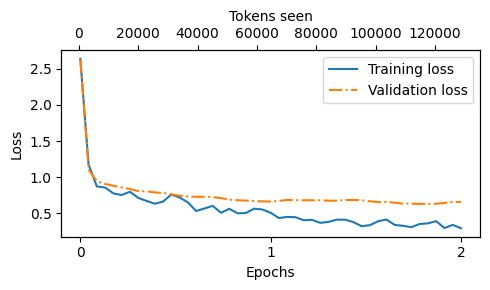

In [ ]:
from previous_chapters import plot_losses
# Alternatively:
# from llms_from_scratch.ch05 import plot_losses

epochs_tensor = torch.linspace(0, num_epochs, len(train_losses))
plot_losses(epochs_tensor, tokens_seen, train_losses, val_losses)

Kurvanya memperlihatkan dua fase. Loss turun tajam di beberapa langkah pertama, lalu melandai sepanjang epoch pertama. Di epoch kedua, kedua kurva mulai menjauh. Loss training terus turun sampai sekitar 0.3, sedangkan loss validasi hampir tidak bergerak: naik dulu ke 0.686, turun ke titik terendah 0.631 di langkah 205 dan 210, lalu kembali ke 0.656. Sepanjang epoch kedua loss training turun sekitar 0.2, sementara loss validasi hanya membaik sekitar 0.03 di titik terbaiknya.

Celah yang melebar seperti ini adalah tanda awal *overfitting*: model mulai menghafal contoh training lebih cepat daripada mempelajari hal yang berlaku juga untuk contoh baru. Notebook penulis di repo mencatat hal yang sama: overfitting ringan mulai terlihat sesudah sekitar satu epoch training. Satu catatan supaya kita tidak berlebihan menafsirkan: setiap titik validasi dihitung dari 40 contoh yang sama. Naik-turunnya memang perubahan nyata pada 40 contoh itu, tapi selisih sekitar 0.03 terlalu kecil untuk dibaca sebagai tren umum. (Figure 7.17 di buku tidak ditampilkan, karena grafik di atas menggantikannya.)

Angka terakhir di log -- training 0.294, validasi 0.656 di langkah 230 -- mudah dianggap sebagai nilai akhir model, padahal tidak tepat. Evaluasi itu terjadi sesudah 231 update, sedangkan training berhenti sesudah 232 update (2 epoch x 116 batch). Batch training yang diukur di log juga berbeda dari batch yang kita pakai untuk loss awal. Sel berikut mengukur model akhir pada batch yang sama seperti sebelum training, ditambah seluruh validation set dan test set.

In [ ]:
# Sel tambahan: pengukuran model akhir sesudah training (terpisah dari evaluasi terakhir di log)
n_logged = len(train_losses)
last_logged_evaluation = {
    "step": 5 * (n_logged - 1), "after_optimizer_updates": 5 * (n_logged - 1) + 1,
    "train_loss": train_losses[-1], "val_loss": val_losses[-1], "tokens_seen": tokens_seen[-1],
    "scope": "evaluate_model(eval_iter=5): 5 batch train (urutan shuffle saat itu) + 5 batch validation pertama"}
optimizer_updates_total = len(train_loader) * num_epochs

torch.manual_seed(123)                 # urutan batch train sama dengan pengukuran loss awal di atas
with torch.no_grad():
    final_model_eval = {
        "after_optimizer_updates": optimizer_updates_total,
        "train_loss_5_batches_seed123": calc_loss_loader(train_loader, model, device, num_batches=5),
        "val_loss_5_batches": calc_loss_loader(val_loader, model, device, num_batches=5),
        "val_loss_full": calc_loss_loader(val_loader, model, device),
        "test_loss_full": calc_loss_loader(test_loader, model, device),
        "scope": {"train_loss_5_batches_seed123": "5 batch train pertama sesudah torch.manual_seed(123), sama dengan loss awal",
                  "val_loss_5_batches": "5 batch validation pertama (40 contoh), sama dengan loss awal",
                  "val_loss_full": f"semua {len(val_loader)} batch validation ({len(val_data)} contoh)",
                  "test_loss_full": f"semua {len(test_loader)} batch test ({len(test_data)} contoh)"}}
print("evaluasi terakhir di log :", json.dumps(last_logged_evaluation, indent=1))
print("total optimizer update   :", optimizer_updates_total)
print("model akhir (terpisah)   :", json.dumps(final_model_eval, indent=1))
print("loss awal (5 batch, seed 123): train", train_loss, "| val", val_loss)

evaluasi terakhir di log : {
 "step": 230,
 "after_optimizer_updates": 231,
 "train_loss": 0.2943525493144989,
 "val_loss": 0.6560537695884705,
 "tokens_seen": 128776,
 "scope": "evaluate_model(eval_iter=5): 5 batch train (urutan shuffle saat itu) + 5 batch validation pertama"
}
total optimizer update   : 232
model akhir (terpisah)   : {
 "after_optimizer_updates": 232,
 "train_loss_5_batches_seed123": 0.3142522692680359,
 "val_loss_5_batches": 0.6550617218017578,
 "val_loss_full": 0.6324559705598014,
 "test_loss_full": 0.683131530880928,
 "scope": {
  "train_loss_5_batches_seed123": "5 batch train pertama sesudah torch.manual_seed(123), sama dengan loss awal",
  "val_loss_5_batches": "5 batch validation pertama (40 contoh), sama dengan loss awal",
  "val_loss_full": "semua 7 batch validation (55 contoh)",
  "test_loss_full": "semua 14 batch test (110 contoh)"
 }
}
loss awal (5 batch, seed 123): train 3.82590913772583 | val 3.7619335651397705


Pada batch yang sama persis dengan sebelum training, loss training turun dari 3.83 ke 0.31, dan loss validasi dari 3.76 ke 0.66. Inilah perbandingan sebelum-sesudah yang paling adil di notebook ini, karena satu-satunya yang berubah adalah bobot model. Dengan cara membaca yang sama seperti tadi, loss validasi 0.66 berarti token target kini rata-rata mendapat peluang sekitar 0.52, naik dari 0.023 sebelum training. Tapi ini rata-rata atas semua posisi target, termasuk pembuka template yang sama di setiap contoh dan kini mudah sekali ditebak. Angka 0.52 belum mengatakan seberapa yakin model pada isi jawaban, apalagi apakah jawaban yang ia tulis sendiri benar.

Pada seluruh validation set, loss model akhir 0.632, sedikit di bawah 0.655 pada 40 contoh yang dipakai di log; jadi 40 contoh itu wakil yang cukup baik, walaupun tidak sempurna. Pada test set, 110 instruksi yang tidak dipakai selama training, loss-nya 0.683, hanya sedikit lebih tinggi. Dalam ukuran loss, model bekerja hampir sama baiknya pada instruksi yang belum pernah ia lihat.

Angka training 0.314 di sini juga berbeda dari 0.294 di log, terutama karena batch yang diukur berbeda. Di sepuluh evaluasi terakhir, loss training di log naik-turun antara 0.294 dan 0.414, sedangkan loss validasi, yang selalu dihitung pada batch yang sama, bergerak jauh lebih tenang. Pada 5 batch validasi yang sama, update terakhir hanya menggeser loss dari 0.656 ke 0.655.

### Under the hood 2 dan 3, sesudah training

Loss yang turun berarti model kini memberi peluang lebih besar kepada seluruh teks target -- termasuk pembuka template dan teks instruksi, bukan hanya jawaban. Pengukuran berikut mengulang pembedahan loss per segmen pada model akhir, supaya kita tahu dari mana penurunan itu datang. Dan peluang yang lebih besar untuk jawaban acuan pun belum berarti jawaban yang ditulis model sendiri benar; untuk itu kita perlu membaca jawabannya di 7.7.

In [ ]:
# UTH 2 + 3 (sel tambahan): pengukuran yang sama pada model sesudah fine-tuning
uth2_ft = loss_anatomy(model, val_data, device)
show_anatomy(uth2_ft, "fine-tuned")
print()
print("   segmen               CE pretrained -> fine-tuned")
for s in SEGMENTS:
    print(f"   {s:20s} {uth2_base['seg'][s]['mean']:7.3f} -> {uth2_ft['seg'][s]['mean']:7.3f}")

[fine-tuned]  segmen             token   CE rata2   porsi loss
   preamble               1265     0.000       0.0%
   instruction+input       802     1.534      62.0%
   header                  330     0.018       0.3%
   response                664     1.118      37.4%
   eos                      55     0.114       0.3%
   P(<|endoftext|> | jawaban gold): rata-rata 0.9558, median 0.9998
   generasi greedy 3 prompt test: berhenti sendiri 3/3, token baru [15, 20, 22]

   segmen               CE pretrained -> fine-tuned
   preamble               4.255 ->   0.000
   instruction+input      5.076 ->   1.534
   header                 0.989 ->   0.018
   response               2.780 ->   1.118
   eos                    4.269 ->   0.114


Tebakan kita tadi terbukti, dengan satu kejutan. Lihat tabel kedua di output, yang menjajarkan cross-entropy setiap segmen sebelum dan sesudah training.

Bagian yang selalu sama dihafal sepenuhnya: cross-entropy pembuka template turun ke 0.000, dan header `### Response:` hampir nol. Isi jawaban acuan turun dari 2.78 ke 1.12, tapi tidak mendekati nol, karena setiap jawaban memang berbeda.

Kalau cross-entropy setiap segmen dikalikan dengan jumlah tokennya (kolom `token`, sama sebelum dan sesudah training), lalu hasilnya dibandingkan, terlihat dari mana penurunan loss datang: sekitar 55% dari pembuka template, dan hanya sekitar 11% dari isi jawaban. Inilah alasan konkret kenapa penurunan loss tidak bisa dibaca sebagai "jawabannya jadi jauh lebih baik".

Kejutannya ada di teks instruksi. Isinya berbeda di setiap contoh, tapi cross-entropy-nya juga turun banyak, dari 5.08 ke 1.53. Ada dua penjelasan yang masuk akal, dan pengukuran ini tidak memisahkan keduanya. Pertama, segmen ini juga memuat bagian tetap, yaitu header `### Input:` pada contoh yang punya input. Kedua, instruksi di dataset ini cukup seragam: kalau dihitung dari file dataset, 300 dari 1,100 instruksi diawali kata "What" dan 96 diawali "Rewrite". Meski turun, teks instruksi kini menyumbang bagian terbesar dari sisa loss, 62%.

Perubahan yang paling penting ada di sinyal berhenti. Sesudah jawaban acuan disodorkan, peluang model memilih 50256 naik dari 0.017 ke 0.956, dan ketiga generasi test kini berhenti sendiri, sesudah 15, 20, dan 22 token. **Satu token 50256 per baris target, yang sengaja dipertahankan collate function, ternyata cukup untuk mengajari model kapan berhenti.** Tiga generasi tentu masih sampel kecil; di 7.7 kita akan memeriksa apakah ke-110 jawaban test juga berhenti sendiri. Dan yang diukur di sini adalah kapan berhenti, bukan apakah yang ditulis sebelum berhenti itu benar.

Hasil ini juga relevan untuk dua latihan. Kalau instruksi di-mask, seperti di latihan 7.2, segmen yang kini menyumbang 62% loss dibuang dari perhitungan, sehingga angka loss dengan dan tanpa masking mengukur hal yang berbeda dan tidak bisa dibandingkan langsung. Latihan 7.3 mengulang fine-tuning ini dengan dataset Alpaca yang berisi 52 ribu entri; di bagian latihan kita mengukur seberapa besar pekerjaan itu.

## 7.7 Extracting and saving responses

Loss mengukur seberapa besar peluang yang diberikan model kepada jawaban acuan, tapi tidak memberi tahu jawaban seperti apa yang akan ia tulis sendiri. Tahap ketiga dimulai dengan membiarkan model menjawab instruksi test yang belum pernah dilihatnya.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/07.Chapter07/figure7.18.png" width="700">

**Figure 7.18** Langkah 7 dan 8: mengambil jawaban model untuk test set dan membandingkannya dengan jawaban acuan.

Kita mulai dari tiga contoh pertama. Sel berikut mencetak setiap jawaban model berdampingan dengan jawaban acuan dari dataset (di output diberi label "Correct response"). Generasinya sama seperti sebelumnya -- greedy, berhenti di token 50256 -- tapi kini dengan batas 256 token baru, dan jawaban model diambil dengan membuang prompt dan header `### Response:` dari teks yang dihasilkan.

In [ ]:
torch.manual_seed(123)


for entry in test_data[:3]:

    input_text = format_input(entry)

    token_ids = generate(
        model=model,
        idx=text_to_token_ids(input_text, tokenizer).to(device),
        max_new_tokens=256,
        context_size=BASE_CONFIG["context_length"],
        eos_id=50256
    )
    generated_text = token_ids_to_text(token_ids, tokenizer)
    response_text = (
        generated_text[len(input_text):]
        .replace("### Response:", "")
        .strip()
)

    print(input_text)
    print(f"\nCorrect response:\n>> {entry['output']}")
    print(f"\nModel response:\n>> {response_text.strip()}")
    print("-------------------------------------")

Below is an instruction that describes a task. Write a response that appropriately completes the request.

### Instruction:
Rewrite the sentence using a simile.

### Input:
The car is very fast.

Correct response:
>> The car is as fast as lightning.

Model response:
>> The car is as fast as a bullet.
-------------------------------------
Below is an instruction that describes a task. Write a response that appropriately completes the request.

### Instruction:
What type of cloud is typically associated with thunderstorms?

Correct response:
>> The type of cloud typically associated with thunderstorms is cumulonimbus.

Model response:
>> The type of cloud associated with thunderstorms is a cumulus cloud.
-------------------------------------
Below is an instruction that describes a task. Write a response that appropriately completes the request.

### Instruction:
Name the author of 'Pride and Prejudice'.

Correct response:
>> Jane Austen.

Model response:
>> The author of 'Pride and Prej

Ketiga jawaban ini masing-masing mengajarkan hal yang berbeda. Yang pertama benar dengan pilihan kata sendiri: "as fast as a bullet" alih-alih "as fast as lightning". Yang ketiga juga benar, hanya lebih panjang dari acuannya, dalam gaya kalimat lengkap yang kita lihat di dataset. Yang kedua salah. Model menjawab "cumulus cloud", padahal awan yang biasanya membawa badai petir adalah cumulonimbus. Kalimatnya rapi, formatnya tepat, dan model berhenti di tempat yang wajar -- tapi isinya keliru.

Jadi menilai model instruksi lebih sulit daripada menilai classifier di Chapter 6. Jawaban yang benar bisa ditulis dengan kata-kata berbeda, dan jawaban yang salah bisa terdengar sangat meyakinkan.

Ada tiga cara umum untuk menilai model instruksi, dan ketiga contoh tadi membantu melihat kekuatan masing-masing. Benchmark soal jawaban singkat dan pilihan ganda, seperti MMLU ([arXiv:2009.03300](https://arxiv.org/abs/2009.03300)), menguji pengetahuan model dengan jawaban yang bisa dicocokkan otomatis; tapi jawaban bebas seperti "as fast as a bullet" tidak punya satu jawaban benar untuk dicocokkan. Perbandingan preferensi oleh manusia, seperti LMSYS Chatbot Arena, bisa menilai jawaban seperti itu, tapi menilai 110 jawaban dengan tangan terlalu lambat untuk dipakai setiap kali kita mengubah sesuatu. Cara ketiga memakai LLM lain yang lebih kuat sebagai juri, seperti pada AlpacaEval. Buku memakai versi sederhana dari cara ini: juri membaca instruksi, jawaban acuan, dan jawaban model, lalu memberi skor.

Langkah pertamanya adalah menghasilkan jawaban untuk seluruh test set dan menyimpannya ke file (listing 7.9).

In [ ]:
# Sel tambahan: catat waktu mulai listing 7.9 (untuk ringkasan run)
TIMERS["generate_start"] = time.time()

In [ ]:
from tqdm import tqdm

for i, entry in tqdm(enumerate(test_data), total=len(test_data)):

    input_text = format_input(entry)

    token_ids = generate(
        model=model,
        idx=text_to_token_ids(input_text, tokenizer).to(device),
        max_new_tokens=256,
        context_size=BASE_CONFIG["context_length"],
        eos_id=50256
    )
    generated_text = token_ids_to_text(token_ids, tokenizer)
    response_text = generated_text[len(input_text):].replace("### Response:", "").strip()

    test_data[i]["model_response"] = response_text


with open("instruction-data-with-response.json", "w") as file:
    json.dump(test_data, file, indent=4)  # "indent" for pretty-printing

100%|██████████| 110/110 [01:17<00:00,  1.42it/s]


Ke-110 jawaban selesai dalam 1 menit 17 detik di T4. Fungsi `generate` dari Chapter 5 tidak memakai *KV cache* -- teknik menyimpan hasil perhitungan attention untuk token-token sebelumnya -- sehingga setiap token baru menjalankan satu forward pass penuh atas seluruh teks. Jawaban yang tidak pernah berhenti berarti 256 forward pass, sedangkan jawaban pendek hanya butuh belasan.

Apakah semua jawaban itu berhenti sendiri sebelum batas 256 token? Sel berikut memeriksa jawaban yang terpanjang.

In [ ]:
# Sel tambahan: catat waktu selesai listing 7.9 (untuk ringkasan run; tanpa output)
TIMERS["generate_end"] = time.time()

In [ ]:
# UTH 3 (lanjutan, sel tambahan): apakah generasi test set berhenti sendiri sebelum batas 256 token?
resp_tokens = [len(tokenizer.encode(e["model_response"])) for e in test_data]
header = len(tokenizer.encode("\n\n### Response:\n"))
print(f"token respons (setelah header dibuang): min {min(resp_tokens)}, median {statistics.median(resp_tokens)}, "
      f"maks {max(resp_tokens)}")
print(f"respons + header terpanjang: {max(resp_tokens) + header} token baru dari batas 256")
print(f"respons kosong: {sum(t == 0 for t in resp_tokens)}")

token respons (setelah header dibuang): min 1, median 11.0, maks 250
respons + header terpanjang: 256 token baru dari batas 256
respons kosong: 0


Hampir semua jawaban pendek; setengahnya tidak lebih dari 11 token. Tapi jawaban terpanjang mencapai 250 token, dan ditambah 6 token header `### Response:`, totalnya tepat 256, yaitu batas `max_new_tokens`. Untuk satu instruksi, model tidak pernah memilih berhenti; generasinya dipotong.

Instruksi itu adalah "What is the formula for calculating work done?" Jawabannya dibuka dengan benar, "The formula for calculating work done is W =", lalu tersesat: `(1 - H) + (1 - C) + (1 - D) + ...`, menyusuri alfabet sampai `(1 - Z)`, lalu mulai lagi dari `(1 - H)` sampai jatahnya habis. Jawaban acuannya sebenarnya sederhana: gaya dikali jarak. Ini contoh *repetition loop*, kegagalan yang dikenal pada greedy decoding: setelah pola `+ (1 - X)` muncul beberapa kali, mengulanginya lagi terus menjadi pilihan dengan peluang tertinggi, dan token 50256 tidak pernah mengunggulinya.

Jadi 109 dari 110 jawaban berhenti sendiri. Sinyal berhenti dari Under the hood 3 bekerja hampir selalu, tapi `max_new_tokens` tetap dibutuhkan sebagai pengaman.

Kasus seperti ini juga rapuh. Run penulis yang tersimpan di repo punya tepat satu kasus serupa, tapi pada instruksi lain ("Sort the following list in descending order."). Dari 110 jawaban, 68 sama kata demi kata dengan jawaban run penulis dan 42 berbeda. Data, seed, dan bobot awalnya sama, jadi penyebab yang paling mungkin adalah selisih pembulatan yang sama dengan yang terlihat di log training; begitu satu pilihan token berbeda, sisa jawabannya ikut bercabang.

In [ ]:
print(test_data[0])

{'instruction': 'Rewrite the sentence using a simile.', 'input': 'The car is very fast.', 'output': 'The car is as fast as lightning.', 'model_response': 'The car is as fast as a bullet.'}


Setiap entri test kini punya kunci keempat, `model_response`. Seluruh test set beserta jawaban model disimpan ke `instruction-data-with-response.json`, sehingga penilaian bisa dijalankan terpisah tanpa memuat GPT-2 lagi.

Membaca ke-110 jawaban (semuanya tercetak di ringkasan run di akhir notebook) memperlihatkan pola yang sama dengan contoh awan tadi. Banyak jawaban mengikuti bentuk kalimat dataset dengan rapi, tapi isinya bervariasi. Ada yang benar, seperti "The capital of Denmark is Copenhagen." dan "3 kilometers is 3000 meters." Ada pula yang salah dengan bentuk yang sama meyakinkannya: "The periodic symbol for chlorine is C.", "1000 grams is 0.1 kilograms.", atau "50 miles per hour is approximately 32.5 kilometers per hour." (acuannya sekitar 80.47).

Ada juga kegagalan jenis lain: untuk 10 dari 110 instruksi, model hanya menyalin input-nya. Satu di antaranya memperlihatkan masalahnya dengan sangat jelas. Untuk "Convert the given sentence into active voice." dengan input "The law was passed by the government.", model menjawab kalimat input itu apa adanya. Jawaban acuannya, "The government passed the law.", tidak berisi satu kata pun yang tidak ada di jawaban model, padahal instruksinya sama sekali tidak dikerjakan.

Contoh-contoh ini menjelaskan kenapa pencocokan teks tidak cukup sebagai ukuran. Hanya 16 jawaban yang sama persis dengan acuan, tapi angka itu bukan akurasi model: "as fast as a bullet" dihitung tidak cocok padahal benar. Sebaliknya, ukuran berbasis kesamaan kata akan memberi nilai tinggi untuk jawaban yang hanya menyalin input tadi.

**Fine-tuning ini jelas mengajarkan format jawaban dan kapan berhenti; seberapa sering isinya benar adalah pertanyaan yang terpisah.** Pertanyaan itulah yang ingin dijawab oleh juri di 7.8.

In [ ]:
import re


file_name = f"{re.sub(r'[ ()]', '', CHOOSE_MODEL) }-sft.pth"
torch.save(model.state_dict(), file_name)
print(f"Model saved as {file_name}")

# Load model via
# model.load_state_dict(torch.load("gpt2-medium355M-sft.pth"))

Model saved as gpt2-medium355M-sft.pth


Bobot hasil fine-tuning disimpan sebagai `gpt2-medium355M-sft.pth` di disk runtime Colab. Ukuran file-nya sendiri tidak dicetak. Perkiraan 1.63 GB di hitungan memori 7.5 hanya menghitung parameter; ditambah 24 causal mask, file-nya sekitar 1.73 GB. Itu kira-kira sepertiga checkpoint training 4.98 GB, karena file ini tidak membawa kedua momen AdamW. File ini cukup untuk menghasilkan teks, dan juga bisa menjadi titik awal training baru (notebook DPO di repo resmi mulai dari file ini), tapi tidak cukup untuk melanjutkan run ini persis dari titik terakhirnya. File ini tidak ikut bersama notebook; untuk memakainya lagi, jalankan ulang notebook atau muat dengan `load_state_dict`, seperti komentar di sel.

## 7.8 Evaluating the fine-tuned LLM

Sekarang kita kerjakan cara ketiga. Idenya agak berputar: untuk menilai model instruksi yang kecil, kita memakai model instruksi lain yang jauh lebih besar. Alasannya, memutuskan apakah "as fast as a bullet" sama baiknya dengan "as fast as lightning", atau apakah "cumulus" bisa menggantikan "cumulonimbus", adalah tugas memahami bahasa, bukan tugas mencocokkan string, dan tugas seperti itu bisa diberikan lewat sebuah instruksi.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/07.Chapter07/figure7.19.png" width="700">

**Figure 7.19** Langkah 9: memberi skor untuk jawaban test set dengan LLM lain sebagai juri.

Jurinya adalah Llama 3 8B versi instruct, model 8 miliar parameter yang sudah dilatih mengikuti instruksi. Model ini dijalankan di komputer sendiri lewat Ollama, aplikasi untuk menjalankan LLM secara lokal. Ollama harus berjalan di latar belakang, lewat `ollama serve` di terminal atau lewat aplikasinya, dan modelnya diunduh sekali dengan `ollama run llama3` (4.7 GB).

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/07.Chapter07/figure7.20.png" width="700">

**Figure 7.20** Dua cara menjalankan Ollama: perintah ollama serve di terminal, atau aplikasi Ollama yang berjalan di latar belakang.

Di sinilah run Colab kita tidak bisa mengikuti buku. Runtime Colab bawaan tidak menyertakan Ollama, dan run ini tidak memasangnya, jadi keempat sel penilaian di bawah berhenti dengan error, yang dibiarkan tercetak apa adanya. Kodenya tetap utuh: di mesin yang menjalankan Ollama dengan `llama3`, sel yang sama akan menghasilkan skor. Karena itu catatan sesudah setiap sel membahas apa yang dikerjakan kodenya dan seperti apa hasilnya di run penulis. Notebook ini sengaja tidak mengganti juri secara diam-diam, karena skor dari juri lain tidak bisa disamakan dengan skor di buku.

In [ ]:
# Sel buku (harness): cek proses Ollama. Tanpa Ollama, kode buku sendiri melempar RuntimeError.
CEK_OLLAMA = r'''
import psutil

def check_if_running(process_name):
    running = False
    for proc in psutil.process_iter(["name"]):
        if process_name in proc.info["name"]:
            running = True
            break
    return running

ollama_running = check_if_running("ollama")

if not ollama_running:
    raise RuntimeError("Ollama not running. Launch ollama before proceeding.")
print("Ollama running:", check_if_running("ollama"))
'''
run_listing('Cek Ollama (listing buku)', CEK_OLLAMA)


[harness] Cek Ollama (listing buku): RuntimeError -- traceback riil di atas; Run all berlanjut.


Traceback (most recent call last):
  File "/tmp/ipykernel_2355/3280993272.py", line 31, in run_listing
    exec(compile(src, fname, "exec"), globals())
    ~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "<Cek Ollama (listing buku)>", line 14, in <module>
    raise RuntimeError("Ollama not running. Launch ollama before proceeding.")
RuntimeError: Ollama not running. Launch ollama before proceeding.


Sel pertama memeriksa apakah ada proses yang namanya mengandung "ollama", dan berhenti dengan `RuntimeError` kalau tidak ada. Pemeriksaan ini tidak memastikan model `llama3` sudah terpasang; itu baru ketahuan saat juri benar-benar dipanggil.

In [ ]:
# This cell is optional; it allows you to restart the notebook
# and only run section 7.7 without rerunning any of the previous code
import json
from tqdm import tqdm

file_path = "instruction-data-with-response.json"

with open(file_path, "r") as file:
    test_data = json.load(file)


def format_input(entry):
    instruction_text = (
        f"Below is an instruction that describes a task. "
        f"Write a response that appropriately completes the request."
        f"\n\n### Instruction:\n{entry['instruction']}"
    )

    input_text = f"\n\n### Input:\n{entry['input']}" if entry["input"] else ""

    return instruction_text + input_text

Sel opsional di atas memuat ulang file jawaban dan mendefinisikan ulang `format_input`, supaya bagian 7.8 bisa dijalankan di sesi baru tanpa mengulang training.

Listing 7.10 berbicara dengan Ollama lewat REST API, yaitu permintaan HTTP biasa ke `localhost:11434`. Fungsi `query_model` mengirim nama model dan satu pesan, lalu merangkai jawaban juri yang datang sepotong demi sepotong (*streaming*). Opsi-opsinya dipasang supaya penilaian bisa diulang: `temperature=0` membuat juri selalu memilih token dengan peluang tertinggi, sama seperti greedy decoding yang dipakai model kita di 7.7; `seed=123` mengunci keacakan yang masih tersisa; dan `num_ctx=2048` menetapkan panjang konteks yang dibaca juri. Meski begitu, penulis mencatat bahwa Ollama belum sepenuhnya deterministik antar sistem operasi, jadi skor di mesin lain bisa sedikit berbeda. Contoh di akhir listing menanyakan "What do Llamas eat?" untuk memastikan servernya hidup.

In [ ]:
# Sel buku (harness): listing 7.10 query_model + contoh, juri llama3 via Ollama REST API.
LISTING_7_10 = r'''
import requests  # noqa: F811
# import urllib.request

def query_model(
    prompt,
    model="llama3",
    # If you used OLLAMA_HOST=127.0.0.1:11435 ollama serve
    # update the address from 11434 to 11435
    url="http://localhost:11434/api/chat"
):
    # Create the data payload as a dictionary
    data = {
        "model": model,
        "messages": [
            {"role": "user", "content": prompt}
        ],
        "options": {     # Settings below are required for deterministic responses
            "seed": 123,
            "temperature": 0,
            "num_ctx": 2048
        }
    }


    """
    # Convert the dictionary to a JSON formatted string and encode it to bytes
    payload = json.dumps(data).encode("utf-8")

    # Create a request object, setting the method to POST and adding necessary headers
    request = urllib.request.Request(
        url,
        data=payload,
        method="POST"
    )
    request.add_header("Content-Type", "application/json")

    # Send the request and capture the response
    response_data = ""
    with urllib.request.urlopen(request) as response:
        # Read and decode the response
        while True:
            line = response.readline().decode("utf-8")
            if not line:
                break
            response_json = json.loads(line)
            response_data += response_json["message"]["content"]

    return response_data
    """

    # The book originally used the commented-out code above, which is based
    # on urllib. It works generally fine, but some readers reported
    # issues with using urllib when using a (company) VPN.
    # The code below uses the requests library, which doesn't seem
    # to have these issues.

    # Send the POST request
    with requests.post(url, json=data, stream=True, timeout=30) as r:
        r.raise_for_status()
        response_data = ""
        for line in r.iter_lines(decode_unicode=True):
            if not line:
                continue
            response_json = json.loads(line)
            if "message" in response_json:
                response_data += response_json["message"]["content"]

    return response_data


model = "llama3"
result = query_model("What do Llamas eat?", model)
print(result)
'''
run_listing('Listing 7.10 (juri llama3)', LISTING_7_10)


[harness] Listing 7.10 (juri llama3): ConnectionError -- traceback riil di atas; Run all berlanjut.


Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/urllib3/connection.py", line 198, in _new_conn
    sock = connection.create_connection(
        (self._dns_host, self.port),
    ...<2 lines>...
        socket_options=self.socket_options,
    )
  File "/usr/local/lib/python3.13/dist-packages/urllib3/util/connection.py", line 85, in create_connection
    raise err
  File "/usr/local/lib/python3.13/dist-packages/urllib3/util/connection.py", line 73, in create_connection
    sock.connect(sa)
    ~~~~~~~~~~~~^^^^
ConnectionRefusedError: [Errno 111] Connection refused

The above exception was the direct cause of the following exception:

Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/urllib3/connectionpool.py", line 787, in urlopen
    response = self._make_request(
        conn,
    ...<10 lines>...
        **response_kw,
    )
  File "/usr/local/lib/python3.13/dist-packages/urllib3/connectionpool.py", line 493, in _make_

Tanpa server Ollama, pertanyaan contoh itu tidak pernah terjawab, tapi fungsi `query_model` tetap terdefinisi untuk sel-sel berikutnya.

Sel berikut memakai fungsi itu untuk menilai tiga jawaban pertama. Prompt-nya menyusun tiga hal untuk juri -- input lengkap dalam format Alpaca, jawaban acuan, dan jawaban model -- lalu meminta skor 0 sampai 100.

In [ ]:
# Sel buku (harness): penilaian verbose 3 contoh pertama oleh juri llama3.
SKOR_VERBOSE_3 = r'''
for entry in test_data[:3]:
    prompt = (
        f"Given the input `{format_input(entry)}` "
        f"and correct output `{entry['output']}`, "
        f"score the model response `{entry['model_response']}`"
        f" on a scale from 0 to 100, where 100 is the best score. "
    )
    print("\nDataset response:")
    print(">>", entry['output'])
    print("\nModel response:")
    print(">>", entry["model_response"])
    print("\nScore:")
    print(">>", query_model(prompt))
    print("\n-------------------------")
'''
run_listing('Skor verbose 3 contoh (juri llama3)', SKOR_VERBOSE_3)


Dataset response:
>> The car is as fast as lightning.

Model response:
>> The car is as fast as a bullet.

Score:

[harness] Skor verbose 3 contoh (juri llama3): ConnectionError -- traceback riil di atas; Run all berlanjut.


Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/urllib3/connection.py", line 198, in _new_conn
    sock = connection.create_connection(
        (self._dns_host, self.port),
    ...<2 lines>...
        socket_options=self.socket_options,
    )
  File "/usr/local/lib/python3.13/dist-packages/urllib3/util/connection.py", line 85, in create_connection
    raise err
  File "/usr/local/lib/python3.13/dist-packages/urllib3/util/connection.py", line 73, in create_connection
    sock.connect(sa)
    ~~~~~~~~~~~~^^^^
ConnectionRefusedError: [Errno 111] Connection refused

The above exception was the direct cause of the following exception:

Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/urllib3/connectionpool.py", line 787, in urlopen
    response = self._make_request(
        conn,
    ...<10 lines>...
        **response_kw,
    )
  File "/usr/local/lib/python3.13/dist-packages/urllib3/connectionpool.py", line 493, in _make_

Ketiga jawaban pertama kita sama kata demi kata dengan jawaban di buku, jadi skor dari run penulis yang tersimpan di repo -- bukan run ini -- menilai kalimat yang persis sama dengan yang kita baca di 7.7: 85 untuk "as fast as a bullet", 40 untuk "cumulus cloud", dan 95 untuk jawaban Jane Austen, masing-masing dengan penjelasan panjang. Skor 40 itu menarik. Juri tetap menyebut jawabannya salah karena jenis awannya keliru, tapi memberi nilai sebagian karena jawabannya masih mengaitkan badai petir dengan jenis awan. Ukuran berbasis kesamaan kata, yang kita singgung di 7.7, justru akan menilainya tinggi, karena hampir semua katanya sama dengan acuan. Yang tidak bisa dilakukan ukuran seperti itu adalah mengenali bahwa satu kata yang berbeda itulah inti kesalahannya.

Penjelasan panjang seperti itu sulit dirata-rata. Karena itu listing 7.11 menambahkan satu kalimat ke prompt, "Respond with the integer number only.", lalu mengubah jawaban juri menjadi angka dengan `int()`. Jawaban yang tidak bisa diubah dilewati dengan pesan "Could not convert score", sehingga rata-ratanya bisa saja dihitung dari kurang dari 110 skor; itu sebabnya listing mencetak "Number of scores: n of 110".

In [ ]:
# Sel buku (harness): listing 7.11 skor integer 110 respons oleh juri llama3.
LISTING_7_11 = r'''
def generate_model_scores(json_data, json_key, model="llama3"):
    scores = []
    for entry in tqdm(json_data, desc="Scoring entries"):
        prompt = (
            f"Given the input `{format_input(entry)}` "
            f"and correct output `{entry['output']}`, "
            f"score the model response `{entry[json_key]}`"
            f" on a scale from 0 to 100, where 100 is the best score. "
            f"Respond with the integer number only."
        )
        score = query_model(prompt, model)
        try:
            scores.append(int(score))
        except ValueError:
            print(f"Could not convert score: {score}")
            continue

    return scores


scores = generate_model_scores(test_data, "model_response")
print(f"Number of scores: {len(scores)} of {len(test_data)}")
print(f"Average score: {sum(scores)/len(scores):.2f}\n")
'''
run_listing('Listing 7.11 (skor integer, juri llama3)', LISTING_7_11)

Scoring entries:   0%|          | 0/110 [00:00<?, ?it/s]


[harness] Listing 7.11 (skor integer, juri llama3): ConnectionError -- traceback riil di atas; Run all berlanjut.



Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/urllib3/connection.py", line 198, in _new_conn
    sock = connection.create_connection(
        (self._dns_host, self.port),
    ...<2 lines>...
        socket_options=self.socket_options,
    )
  File "/usr/local/lib/python3.13/dist-packages/urllib3/util/connection.py", line 85, in create_connection
    raise err
  File "/usr/local/lib/python3.13/dist-packages/urllib3/util/connection.py", line 73, in create_connection
    sock.connect(sa)
    ~~~~~~~~~~~~^^^^
ConnectionRefusedError: [Errno 111] Connection refused

The above exception was the direct cause of the following exception:

Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/urllib3/connectionpool.py", line 787, in urlopen
    response = self._make_request(
        conn,
    ...<10 lines>...
        **response_kw,
    )
  File "/usr/local/lib/python3.13/dist-packages/urllib3/connectionpool.py", line 493, in _make

Seandainya juri berjalan, listing ini mencetak dua baris: berapa skor yang berhasil dibaca, dan rata-ratanya. Di output yang tersimpan di repo penulis, hasilnya 110 dari 110 skor dengan rata-rata 50.32 (49.45 di versi notebook yang lebih baru). Notebook yang sama menyebut Llama 3 8B versi base dan instruct mendapat 58.51 dan 82.65, tanpa merinci cara menghitungnya. Angka-angka itu milik run penulis, dan 42 jawaban kita berbeda dari jawaban mereka, jadi tidak bisa dipinjam sebagai skor run ini.

Yang lebih penting adalah cara membacanya. Rata-rata sekitar 50 mudah dibaca sebagai "separuh jawabannya benar", padahal bukan itu artinya: juri memberi nilai sebagian, seperti 40 untuk jawaban awan yang salah tadi. Penulis sendiri memakai angka ini sebagai titik acuan untuk membandingkan model atau pengaturan training yang berbeda dengan juri yang sama. Untuk mendapatkan skor model kita, jalankan bagian 7.8 di mesin yang punya Ollama dan `llama3`; ke-110 jawaban run ini juga tercetak di ringkasan run di akhir notebook, jadi skornya bisa dihitung untuk jawaban yang sama persis dengan yang kita bahas. Lalu muncul pertanyaan berikutnya: seberapa jauh skor dari juri seperti ini bisa dipercaya?

### Under the hood 4: kalibrasi juri

Skor dari juri baru bermakna kalau kita tahu dua titik pembanding. Titik atas, atau *plafon*, adalah skor yang diberikan juri kepada jawaban acuan itu sendiri. Titik bawah, atau *lantai*, adalah skor untuk jawaban yang jelas tidak mengerjakan apa pun; di sini lantainya adalah instruksi yang diulang mentah-mentah sebagai jawaban. Kalau jawaban acuan pun mendapat skor jauh di bawah 100, atau instruksi yang diulang masih mendapat skor jauh di atas 0, skor model kita harus dibaca sebagai posisi di antara kedua titik itu, bukan sebagai persentase kebenaran. Lantai ini sengaja dibuat gamblang. Kegagalan hukum di 7.7 lebih licin: jawaban yang menyalin input berbunyi seperti jawaban sungguhan dan memakai hampir semua kata acuannya. Kalibrasi ini tidak mengukur kasus itu secara langsung, tapi kalau juri sudah murah hati pada instruksi yang diulang, kita punya alasan untuk curiga pada skornya untuk salinan seperti itu. Juri yang baik juga harus konsisten: menilai jawaban yang sama dua kali seharusnya memberi skor yang sama.

Dua sel berikut menyiapkan pengukuran itu untuk mesin yang punya Ollama tapi tidak punya `llama3`. Kalau `RUN_ALT_JUDGE = True`, prompt buku dikirim ke model juri lain (`ALT_JUDGE_MODEL`), dan juri itu menilai jawaban model kita, jawaban acuan sebagai plafon, instruksi yang diulang sebagai lantai, dan jawaban model sekali lagi untuk menguji konsistensi. Jawaban mentah juri, versi modelnya, dan pengaturannya disimpan.

Satu-satunya perubahan pada permintaan adalah `"think": False`. Model dengan mode berpikir bawaan bisa menghabiskan seluruh jatah token untuk berpikir sebelum menjawab, sehingga `int()` tidak menemukan angka: saat dicoba di mesin penyusun notebook ini (bukan di run Colab ini), `qwen3.5:9b` tanpa opsi itu menulis 1,936 token pemikiran tanpa memberi skor.

In [ ]:
# Eksperimen alternatif (sel tambahan): guard -- jalan hanya bila diminta DAN Ollama + model tersedia
import requests


def ollama_models():
    try:
        return {m["name"]: m for m in requests.get("http://localhost:11434/api/tags", timeout=5).json()["models"]}
    except Exception:
        return None


_models = ollama_models() if RUN_ALT_JUDGE else None
ALT_JUDGE_OK = bool(RUN_ALT_JUDGE and _models and ALT_JUDGE_MODEL in _models)
ALT_JUDGE_REASON = ("aktif" if ALT_JUDGE_OK else "RUN_ALT_JUDGE = False" if not RUN_ALT_JUDGE else
                    "Ollama tidak terjangkau di localhost:11434" if _models is None else
                    f"model {ALT_JUDGE_MODEL} tidak terpasang di Ollama")
JUDGE_OPTIONS = {"seed": 123, "temperature": 0, "num_ctx": 2048}     # sama dengan listing 7.10
judge_meta = None
if ALT_JUDGE_OK:
    show = requests.post("http://localhost:11434/api/show", json={"model": ALT_JUDGE_MODEL}, timeout=10).json()
    judge_meta = {"ollama_version": requests.get("http://localhost:11434/api/version", timeout=5).json()["version"],
                  "model": ALT_JUDGE_MODEL, "digest": _models[ALT_JUDGE_MODEL]["digest"],
                  "details": _models[ALT_JUDGE_MODEL].get("details"), "capabilities": show.get("capabilities"),
                  "modelfile_parameters": show.get("parameters"), "options": JUDGE_OPTIONS, "think": False}
    print(json.dumps(judge_meta, indent=1))
else:
    print("eksperimen juri alternatif dilewati:", ALT_JUDGE_REASON)


def query_model_alt(prompt, model=ALT_JUDGE_MODEL, url="http://localhost:11434/api/chat"):
    data = {"model": model, "messages": [{"role": "user", "content": prompt}],
            "options": dict(JUDGE_OPTIONS), "think": False}
    with requests.post(url, json=data, stream=True, timeout=120) as r:
        r.raise_for_status()
        response_data, last = "", {}
        for line in r.iter_lines(decode_unicode=True):
            if line:
                last = json.loads(line)
                if "message" in last:
                    response_data += last["message"]["content"]
    return response_data, {k: last.get(k) for k in ("model", "done_reason", "eval_count", "prompt_eval_count")}


def generate_model_scores_alt(json_data, json_key, raw_log):
    scores = []
    for entry in tqdm(json_data, desc="Scoring entries"):
        prompt = (
            f"Given the input `{format_input(entry)}` "
            f"and correct output `{entry['output']}`, "
            f"score the model response `{entry[json_key]}`"
            f" on a scale from 0 to 100, where 100 is the best score. "
            f"Respond with the integer number only."
        )
        score, info = query_model_alt(prompt)
        raw_log.append({"instruction": entry["instruction"], "key": json_key, "response_scored": entry[json_key],
                        "raw": score, **info})
        try:
            scores.append(int(score))
        except ValueError:
            print(f"Could not convert score: {score}")
            continue
    return scores

eksperimen juri alternatif dilewati: RUN_ALT_JUDGE = False


Sel pertama hanya memeriksa apakah Ollama dan model juri tersedia; di run ini ia berhenti di pengecekan pertama karena `RUN_ALT_JUDGE = False`. Sel berikutnya adalah inti kalibrasinya. Ia menilai 110 entri empat kali -- jawaban model, jawaban acuan, instruksi yang diulang, lalu jawaban model sekali lagi -- dan mencetak rata-rata setiap putaran beserta berapa dari 110 penilaian ulang yang identik. Penilaian ulang itu sekaligus menguji janji listing 7.10: dengan `temperature=0` dan `seed=123`, teks jawaban juri untuk jawaban yang sama seharusnya tidak berubah. Yang dibandingkan adalah teks mentah jawaban juri, bukan hanya angkanya.

In [ ]:
# Eksperimen alternatif (sel tambahan, guard): skor 110 respons + kalibrasi plafon/lantai/skor ulang (UTH 4)
alt_judge = None
if ALT_JUDGE_OK:
    raw = {"model": [], "gold": [], "echo": [], "repeat": []}
    calib = [dict(e, gold_as_response=e["output"], echo_as_response=e["instruction"]) for e in test_data]
    s_model = generate_model_scores_alt(test_data, "model_response", raw["model"])
    s_gold = generate_model_scores_alt(calib, "gold_as_response", raw["gold"])
    s_echo = generate_model_scores_alt(calib, "echo_as_response", raw["echo"])
    s_rep = generate_model_scores_alt(test_data, "model_response", raw["repeat"])
    same = sum(a["raw"] == b["raw"] for a, b in zip(raw["model"], raw["repeat"]))
    alt_judge = {"meta": judge_meta, "raw": raw,
                 "summary": {k: {"n": len(v), "mean": sum(v) / len(v) if v else None}
                             for k, v in [("model", s_model), ("gold", s_gold), ("echo", s_echo), ("repeat", s_rep)]},
                 "repeat_identical": same}
    with open("judge-raw-alt.json", "w") as f:
        json.dump(alt_judge, f, indent=1)
    for k, v in alt_judge["summary"].items():
        print(f"{k:7s}: {v['n']} skor, rata-rata {v['mean']}")
    print(f"skor ulang identik: {same}/{len(raw['model'])}")
else:
    print("dilewati (eksperimen juri alternatif tidak aktif)")

dilewati (eksperimen juri alternatif tidak aktif)


Karena juri tidak aktif di run ini, keempat rata-rata itu belum ada. Begitu Ollama tersedia, kalibrasi inilah yang layak dijalankan lebih dulu, sebelum skor model mana pun ditafsirkan: baca skor model di antara plafon dan lantai tadi, dan periksa dulu apakah skor ulangnya identik.

## 7.9 Conclusions

Dengan bab ini, siklus pembangunan LLM di buku lengkap: persiapan data, attention, dan arsitektur (Chapter 2 sampai 4), pretraining dan pemuatan bobot (Chapter 5), lalu dua cara fine-tuning (Chapter 6 dan 7).

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/07.Chapter07/figure7.21.png" width="700">

**Figure 7.21** Tiga tahap pembangunan LLM, kini lengkap.

Langkah opsional yang kadang menyusul instruction fine-tuning adalah *preference fine-tuning*, yang menyelaraskan jawaban model dengan preferensi manusia. Buku tidak membahasnya di bab utama, tapi repo resmi menyediakan implementasi DPO (Direct Preference Optimization) dari nol di folder `ch07/04_preference-tuning-with-dpo`. Untuk LLM yang lebih besar dan aplikasi nyata, penulis menyarankan tool seperti Axolotl atau LitGPT.

## Exercises

Setiap latihan bab ini mengubah satu keputusan desain yang sudah kita ukur di sepanjang bab: template prompt (latihan 7.1; pembuka template ternyata dihafal total), target mana yang dihitung loss (7.2; dua pertiga target ternyata teks prompt), skala data (7.3), dan parameter mana yang dilatih (7.4; hitungan memorinya sudah kita buat di 7.5). Training ulangnya tidak dijalankan di run ini (`RUN_EXERCISES = False`), tapi bagian yang ringan tetap kita jalankan: format Phi-3, mekanisme masking, ukuran dataset Alpaca, dan jumlah parameter LoRA.

Demonstrasi Phi-3 dan masking menjalankan sel dari solusi resmi (`exercise-solutions.ipynb`), sedangkan perbandingan token Phi-3 dan hitungan LoRA memakai definisi dari `exercise_experiments.py`. Sel berikut meng-import file itu persis seperti saran solusi resmi.

In [ ]:
# Errata #4 (harness, sel tambahan): impor yang disarankan exercise-solutions.ipynb untuk Exercise 7.4
IMPOR_EXERCISE_EXPERIMENTS = r'''
from exercise_experiments import LoRALayer, LinearWithLoRA, replace_linear_with_lora
'''
run_listing('Impor exercise_experiments', IMPOR_EXERCISE_EXPERIMENTS)

[harness] Impor exercise_experiments: selesai tanpa error di environment ini.


Import berhasil karena Colab punya TensorFlow (`exercise_experiments.py` ikut memuat `gpt_download`). Di mesin tanpa TensorFlow import ini gagal, jadi sel berikut berisi salinan verbatim definisi yang dibutuhkan dari file yang sama, tanpa ikut menjalankan import TensorFlow-nya.

In [ ]:
# Koreksi Errata #4 (sel tambahan): definisi verbatim dari exercise_experiments.py (repo resmi)
import math
from torch.utils.data import Dataset

def format_input_phi(entry):
    instruction_text = (
        f"<|user|>\n{entry['instruction']}"
    )

    input_text = f"\n{entry['input']}" if entry["input"] else ""

    return instruction_text + input_text


class InstructionDatasetPhi(Dataset):
    def __init__(self, data, tokenizer):
        self.data = data

        # Pre-tokenize texts
        self.encoded_texts = []
        for entry in data:

            ###################################################################
            # NEW: Use `format_input_phi` and adjust the response text template
            instruction_plus_input = format_input_phi(entry)
            response_text = f"\n<|assistant|>:\n{entry['output']}"
            ###################################################################
            full_text = instruction_plus_input + response_text
            self.encoded_texts.append(
                tokenizer.encode(full_text)
            )

    def __getitem__(self, index):
        return self.encoded_texts[index]

    def __len__(self):
        return len(self.data)


class InstructionDatasetWithMasking(Dataset):
    def __init__(self, data, tokenizer):
        self.data = data

        # New: Separate list for instruction lengths
        self.instruction_lengths = []
        self.encoded_texts = []

        for entry in data:
            instruction_plus_input = format_input(entry)
            response_text = f"\n\n### Response:\n{entry['output']}"
            full_text = instruction_plus_input + response_text

            self.encoded_texts.append(
                tokenizer.encode(full_text)
            )

            # New: collect instruction lengths
            instruction_length = len(tokenizer.encode(instruction_plus_input))
            self.instruction_lengths.append(instruction_length)

    def __getitem__(self, index):
        # New: return both instruction lengths and texts separately
        return self.instruction_lengths[index], self.encoded_texts[index]

    def __len__(self):
        return len(self.data)


def custom_collate_with_masking_fn(
    batch,
    pad_token_id=50256,
    ignore_index=-100,
    allowed_max_length=None,
    device="cpu"
):
    # Find the longest sequence in the batch
    batch_max_length = max(len(item)+1 for instruction_length, item in batch)   # New: batch is now a tuple

    # Pad and prepare inputs and targets
    inputs_lst, targets_lst = [], []

    for instruction_length, item in batch:  # New: batch is now a tuple
        new_item = item.copy()
        # Add an <|endoftext|> token
        new_item += [pad_token_id]
        # Pad sequences to max_length
        padded = new_item + [pad_token_id] * (batch_max_length - len(new_item))
        inputs = torch.tensor(padded[:-1])  # Truncate the last token for inputs
        targets = torch.tensor(padded[1:])  # Shift +1 to the right for targets

        # Replace all but the first padding tokens in targets by ignore_index
        mask = targets == pad_token_id
        indices = torch.nonzero(mask).squeeze()
        if indices.numel() > 1:
            targets[indices[1:]] = ignore_index

        # New: Mask all input and instruction tokens in the targets
        targets[:instruction_length-1] = -100

        # Optionally truncate to maximum sequence length
        if allowed_max_length is not None:
            inputs = inputs[:allowed_max_length]
            targets = targets[:allowed_max_length]

        inputs_lst.append(inputs)
        targets_lst.append(targets)

    # Convert list of inputs and targets to tensors and transfer to target device
    inputs_tensor = torch.stack(inputs_lst).to(device)
    targets_tensor = torch.stack(targets_lst).to(device)

    return inputs_tensor, targets_tensor


class LoRALayer(torch.nn.Module):
    def __init__(self, in_dim, out_dim, rank, alpha):
        super().__init__()
        self.A = torch.nn.Parameter(torch.empty(in_dim, rank))
        torch.nn.init.kaiming_uniform_(self.A, a=math.sqrt(5))  # similar to standard weight initialization
        self.B = torch.nn.Parameter(torch.zeros(rank, out_dim))
        self.alpha = alpha
        self.rank = rank

    def forward(self, x):
        # Book formula:      alpha_book * (x @ A @ B)
        # Canonical formula: (alpha_canonical / rank) * (x @ A @ B)
        # For the same rank and matrices, they are equal when alpha_canonical = alpha_book * rank.
        # Here, alpha_book=16 and rank=16 give alpha_canonical=256, so 256 / 16 = 16.
        x = (self.alpha / self.rank) * (x @ self.A @ self.B)
        return x


class LinearWithLoRA(torch.nn.Module):
    def __init__(self, linear, rank, alpha):
        super().__init__()
        self.linear = linear
        self.lora = LoRALayer(
            linear.in_features, linear.out_features, rank, alpha
        )

    def forward(self, x):
        return self.linear(x) + self.lora(x)


def replace_linear_with_lora(model, rank, alpha):
    for name, module in model.named_children():
        if isinstance(module, torch.nn.Linear):
            # Replace the Linear layer with LinearWithLoRA
            setattr(model, name, LinearWithLoRA(module, rank, alpha))
        else:
            # Recursively apply the same function to child modules
            replace_linear_with_lora(module, rank, alpha)

Sel berikut berisi fungsi untuk melatih ketiga varian latihan. Isinya mengikuti `exercise_experiments.main()` resmi -- seed, hyperparameter, dan urutan langkahnya sama -- dengan beberapa perbedaan. Bobot dimuat lewat jalur safetensors lalu disalin ke parameter yang berdiri sendiri, persis seperti di 7.5, sehingga `tok_emb` dan `out_head` tidak berbagi memori saat dilatih. Sisanya perbedaan praktis: device mengikuti pilihan notebook, hasilnya dikembalikan sebagai dictionary, dan checkpoint ditulis kalau `USE_RESUMABLE_TRAINING` aktif. Di run ini fungsinya hanya didefinisikan.

In [ ]:
# Sel tambahan: runner Exercise 7.1 / 7.2 / 7.4 -- versi TF-free dari exercise_experiments.main() (repo resmi).
# Urutan seed, hyperparameter, dan alur identik dengan main(); perbedaannya hanya pemuatan bobot (safetensors HF +
# materialisasi independen, seperti 7.5) dan device mengikuti sel knob notebook.
import re
import time
from functools import partial

from safetensors.torch import load_file
from torch.utils.data import DataLoader
from tqdm import tqdm

from previous_chapters import calc_loss_loader, generate, text_to_token_ids, token_ids_to_text


def run_exercise_variant(variant, data, device, weights_file="model-gpt2-medium.safetensors"):
    assert variant in {"baseline", "phi3_prompt", "mask_instructions", "lora"}
    phi3_prompt, mask_instructions, lora = (variant == "phi3_prompt", variant == "mask_instructions",
                                            variant == "lora")
    train_portion = int(len(data) * 0.85)
    test_portion = int(len(data) * 0.1)
    train_data = data[:train_portion]
    test_data = [dict(e) for e in data[train_portion:train_portion + test_portion]]
    val_data = data[train_portion + test_portion:]

    if mask_instructions:
        collate = partial(custom_collate_with_masking_fn, device=device, allowed_max_length=1024)
        CustomDataset = InstructionDatasetWithMasking
    elif phi3_prompt:
        collate = partial(custom_collate_fn, device=device, allowed_max_length=1024)
        CustomDataset = InstructionDatasetPhi
    else:
        collate = partial(custom_collate_fn, device=device, allowed_max_length=1024)
        CustomDataset = InstructionDataset

    torch.manual_seed(123)
    train_loader = DataLoader(CustomDataset(train_data, tokenizer), batch_size=8, collate_fn=collate,
                              shuffle=True, drop_last=True, num_workers=0)
    val_loader = DataLoader(CustomDataset(val_data, tokenizer), batch_size=8, collate_fn=collate,
                            shuffle=False, drop_last=False, num_workers=0)

    model_hf = GPTModel(BASE_CONFIG)                       # mapping resmi HF (7.5) ...
    load_weights_into_gpt(model_hf, load_file(weights_file))
    model = GPTModel(BASE_CONFIG)                          # ... lalu parameter independen (salinan)
    model.load_state_dict(model_hf.state_dict())
    del model_hf
    model.eval()
    model.to(device)
    print("Loaded model:", CHOOSE_MODEL)
    print(50 * "-")

    if lora:
        total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
        print(f"Total trainable parameters before: {total_params:,}")
        for param in model.parameters():
            param.requires_grad = False
        total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
        print(f"Total trainable parameters after: {total_params:,}")
        replace_linear_with_lora(model, rank=16, alpha=256)    # alpha / rank = 16, skala buku
        total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
        print(f"Total trainable LoRA parameters: {total_params:,}")
        model.to(device)

    print("Initial losses")
    with torch.no_grad():
        train_loss = calc_loss_loader(train_loader, model, device, num_batches=5)
        val_loss = calc_loss_loader(val_loader, model, device, num_batches=5)
    print("   Training loss:", train_loss)
    print("   Validation loss:", val_loss)

    start_time = time.time()
    num_epochs = 2
    optimizer = torch.optim.AdamW(model.parameters(), lr=0.00005, weight_decay=0.1)
    torch.manual_seed(123)
    start_context = format_input_phi(val_data[0]) if phi3_prompt else format_input(val_data[0])
    train_losses, val_losses, tokens_seen = train_model_simple(
        model, train_loader, val_loader, optimizer, device,
        num_epochs=num_epochs, eval_freq=5, eval_iter=5,
        start_context=start_context, tokenizer=tokenizer
    )
    execution_time_minutes = (time.time() - start_time) / 60
    print(f"Training completed in {execution_time_minutes:.2f} minutes.")
    print(50 * "-")

    print("Generating responses")
    for i, entry in tqdm(enumerate(test_data), total=len(test_data)):
        input_text = format_input_phi(entry) if phi3_prompt else format_input(entry)
        token_ids = generate(
            model=model,
            idx=text_to_token_ids(input_text, tokenizer).to(device),
            max_new_tokens=256,
            context_size=BASE_CONFIG["context_length"],
            eos_id=50256
        )
        generated_text = token_ids_to_text(token_ids, tokenizer)
        if phi3_prompt:
            response_text = generated_text[len(input_text):].replace("<|assistant|>:", "").strip()
        else:
            response_text = generated_text[len(input_text):].replace("### Response:", "").strip()
        test_data[i]["model_response"] = response_text

    return {"variant": variant, "initial_losses": [train_loss, val_loss],
            "train_losses": train_losses, "val_losses": val_losses, "tokens_seen": tokens_seen,
            "train_minutes": execution_time_minutes,
            "trainable_params": sum(p.numel() for p in model.parameters() if p.requires_grad),
            "responses": test_data}

Sel-sel solusi resmi berikutnya mendefinisikan ulang beberapa nama yang dipakai bab ini, seperti `format_input`, `InstructionDataset`, dan `train_loader`. Supaya demonstrasinya tidak merusak definisi bab, definisi aslinya disimpan dulu dan dipulihkan sesudahnya.

In [ ]:
# Sel tambahan: simpan definisi bab sebelum sel solusi latihan menimpanya
_CH07_NAMES = ["format_input", "InstructionDataset", "custom_collate_fn", "train_dataset", "train_loader",
               "inputs", "targets", "tokenizer"]
_CH07_SAVED = {k: globals()[k] for k in _CH07_NAMES if k in globals()}


def restore_ch07_names():
    globals().update(_CH07_SAVED)
    print("definisi bab dipulihkan:", ", ".join(_CH07_SAVED))

### Exercise 7.1: gaya prompt Phi-3

Latihan pertama mengganti template Alpaca dengan gaya Phi-3 yang jauh lebih pendek. Solusi resmi cukup mengganti `format_input` dan teks penanda jawaban.

In [ ]:
def format_input(entry):
    instruction_text = (
        f"<|user|>\n{entry['instruction']}"
    )

    input_text = f"\n{entry['input']}" if entry["input"] else ""

    return instruction_text + input_text

In [ ]:
sample_data = [
    {'instruction': 'Identify the correct spelling of the following word.', 'input': 'Ocassion', 'output': "The correct spelling is 'Occasion.'"},
    {'instruction': "What is an antonym of 'complicated'?", 'input': '', 'output': "An antonym of 'complicated' is 'simple'."}
]

print(format_input(sample_data[0]))
print()
print(format_input(sample_data[1]))

<|user|>
Identify the correct spelling of the following word.
Ocassion

<|user|>
What is an antonym of 'complicated'?


Tidak ada kalimat pembuka dan tidak ada header: instruksi langsung mengikuti `<|user|>`, dan input menempel di baris berikutnya. Kelihatannya jauh lebih hemat. Tapi solusi resmi menyebut satu kelemahan: `<|user|>` dan `<|assistant|>` bukan token khusus di kosakata GPT-2. Sel berikut mengukur kedua sisi itu.

In [ ]:
# Sel tambahan: pulihkan definisi bab, lalu ukur biaya token template Alpaca vs Phi-3 di training set
restore_ch07_names()
import statistics
print("<|user|>      ->", tokenizer.encode("<|user|>"))
print("<|assistant|> ->", tokenizer.encode("<|assistant|>"))
alp = [len(tokenizer.encode(format_input(e) + f"\n\n### Response:\n{e['output']}")) for e in train_data]
phi = [len(tokenizer.encode(format_input_phi(e) + f"\n<|assistant|>:\n{e['output']}")) for e in train_data]
print(f"token per contoh  Alpaca {statistics.mean(alp):.1f} | Phi-3 {statistics.mean(phi):.1f} "
      f"| hemat {1 - sum(phi) / sum(alp):.1%}")

definisi bab dipulihkan: format_input, InstructionDataset, custom_collate_fn, train_dataset, train_loader, inputs, targets, tokenizer
<|user|>      -> [27, 91, 7220, 91, 29]
<|assistant|> -> [27, 91, 562, 10167, 91, 29]
token per contoh  Alpaca 56.4 | Phi-3 38.9 | hemat 31.0%


Kelemahannya memang ada. `<|user|>` dipecah menjadi lima token (`<`, `|`, `user`, `|`, `>`) dan `<|assistant|>` menjadi enam, karena GPT-2 tidak mengenalnya sebagai satu kesatuan. Tapi penghematannya lebih besar: rata-rata contoh training turun dari 56.4 token dengan Alpaca menjadi 38.9 token dengan Phi-3, sekitar 31% lebih pendek. Penghematan terbesar datang dari 24 token pembuka template Alpaca yang hilang, dan sebagian terpakai lagi oleh penanda `<|user|>` dan `<|assistant|>`.

Contoh yang lebih pendek berarti training yang lebih cepat. Solusi resmi mencatat training sekitar 17% lebih cepat di GPU L4 (1.50 menit dibanding 1.80 menit) dengan skor juri 48.87, setara dengan versi Alpaca. Angka-angka itu dari solusi resmi.

### Exercise 7.2: masking instruksi dan input

Latihan kedua menerapkan masking yang dibahas di akhir 7.3: target pada posisi prompt diganti `-100`, sehingga loss hanya dihitung pada bagian jawaban. Solusi resmi menyimpan panjang bagian prompt setiap contoh di dataset, lalu collate function memakai panjang itu untuk menentukan posisi mana yang ditutup. Kita lihat mekanismenya pada tiga contoh kecil.

In [ ]:
# This `format_input` function is copied from the original chapter 7 code

def format_input(entry):
    instruction_text = (
        f"Below is an instruction that describes a task. "
        f"Write a response that appropriately completes the request."
        f"\n\n### Instruction:\n{entry['instruction']}"
    )

    input_text = f"\n\n### Input:\n{entry['input']}" if entry["input"] else ""

    return instruction_text + input_text

In [ ]:
import torch
from torch.utils.data import Dataset


class InstructionDataset(Dataset):
    def __init__(self, data, tokenizer):
        self.data = data

        ##########################################################################################
        # New: Separate list for instruction lengths
        self.instruction_lengths = []
        ##########################################################################################

        self.encoded_texts = []

        for entry in data:
            instruction_plus_input = format_input(entry)
            response_text = f"\n\n### Response:\n{entry['output']}"
            full_text = instruction_plus_input + response_text

            self.encoded_texts.append(
                tokenizer.encode(full_text)
            )

            ##########################################################################################
            # New: collect instruction lengths
            instruction_length = len(tokenizer.encode(instruction_plus_input))
            self.instruction_lengths.append(instruction_length)
            ##########################################################################################

    def __getitem__(self, index):
        # New: return both instruction lengths and texts separately
        return self.instruction_lengths[index], self.encoded_texts[index]

    def __len__(self):
        return len(self.data)

In [ ]:
import tiktoken

tokenizer = tiktoken.get_encoding("gpt2")

In [ ]:
def custom_collate_fn(
    batch,
    pad_token_id=50256,
    ignore_index=-100,
    allowed_max_length=None,
    device="cpu"
):
    # Find the longest sequence in the batch
    batch_max_length = max(len(item)+1 for instruction_length, item in batch)   # New: batch is now a tuple

    # Pad and prepare inputs and targets
    inputs_lst, targets_lst = [], []

    for instruction_length, item in batch:  # New: batch is now a tuple
        new_item = item.copy()
        # Add an <|endoftext|> token
        new_item += [pad_token_id]
        # Pad sequences to max_length
        padded = new_item + [pad_token_id] * (batch_max_length - len(new_item))
        inputs = torch.tensor(padded[:-1])  # Truncate the last token for inputs
        targets = torch.tensor(padded[1:])  # Shift +1 to the right for targets

        # Replace all but the first padding tokens in targets by ignore_index
        mask = targets == pad_token_id
        indices = torch.nonzero(mask).squeeze()
        if indices.numel() > 1:
            targets[indices[1:]] = ignore_index

        ##########################################################################################
        # New: Mask all input and instruction tokens in the targets
        targets[:instruction_length-1] = -100
        ##########################################################################################

        # Optionally truncate to maximum sequence length
        if allowed_max_length is not None:
            inputs = inputs[:allowed_max_length]
            targets = targets[:allowed_max_length]

        inputs_lst.append(inputs)
        targets_lst.append(targets)

    # Convert list of inputs and targets to tensors and transfer to target device
    inputs_tensor = torch.stack(inputs_lst).to(device)
    targets_tensor = torch.stack(targets_lst).to(device)

    return inputs_tensor, targets_tensor

In [ ]:
sample_data = [
    {'instruction': "What is an antonym of 'complicated'?", 'input': '', 'output': "An antonym of 'complicated' is 'simple'."},
    {'instruction': 'Sort the following list in alphabetical order.', 'input': 'Zebra, Elephant, Crocodile', 'output': 'Crocodile, Elephant, Zebra'},
    {'instruction': 'Arrange the given numbers in descending order.', 'input': '5, 12, 8, 3, 15', 'output': '15, 12, 8, 5, 3.'}
]

In [ ]:
from torch.utils.data import DataLoader

train_dataset = InstructionDataset(sample_data, tokenizer)
train_loader = DataLoader(
    train_dataset,
    batch_size=len(sample_data),
    collate_fn=custom_collate_fn,
    num_workers=0
)

In [ ]:
print("Train loader:")
for inputs, targets in train_loader:
    print(inputs.shape, targets.shape)

Train loader:
torch.Size([3, 64]) torch.Size([3, 64])


Ketiga contoh membentuk satu batch selebar 64 token, yaitu panjang contoh terpanjangnya. Kita periksa contoh kedua, yang meminta daftar "Zebra, Elephant, Crocodile" diurutkan secara alfabetis.

In [ ]:
print("Inputs:\n", inputs[1])
print("\n\nTargets:\n", targets[1])

Inputs:
 tensor([21106,   318,   281, 12064,   326,  8477,   257,  4876,    13, 19430,
          257,  2882,   326, 20431, 32543,   262,  2581,    13,   198,   198,
        21017, 46486,    25,   198, 42758,   262,  1708,  1351,   287, 24830,
          605,  1502,    13,   198,   198, 21017, 23412,    25,   198,    57,
        37052,    11, 42651,    11,  9325, 19815,   576,   198,   198, 21017,
        18261,    25,   198,    34, 12204,   375,   576,    11, 42651,    11,
         1168, 37052, 50256, 50256])


Targets:
 tensor([ -100,  -100,  -100,  -100,  -100,  -100,  -100,  -100,  -100,  -100,
         -100,  -100,  -100,  -100,  -100,  -100,  -100,  -100,  -100,  -100,
         -100,  -100,  -100,  -100,  -100,  -100,  -100,  -100,  -100,  -100,
         -100,  -100,  -100,  -100,  -100,  -100,  -100,  -100,  -100,  -100,
         -100,  -100,  -100,  -100,  -100,  -100,   198,   198, 21017, 18261,
           25,   198,    34, 12204,   375,   576,    11, 42651,    11,  1168,
      

Dari 64 posisi target, 48 kini bernilai `-100`. Empat puluh enam di antaranya menutupi seluruh prompt -- kalimat pembuka, instruksi, dan input -- dan dua lagi menutupi padding di ujung. Yang tersisa untuk dihitung loss hanya 16 posisi: header `### Response:` beserta jawaban "Crocodile, Elephant, Zebra", lalu satu token 50256.

Masking itu dikerjakan oleh satu baris, `targets[:instruction_length-1] = -100`. Pengurangan satu diperlukan karena target sudah digeser satu posisi: target di posisi `t` adalah tebakan untuk token ke-`t+1`.

In [ ]:
print(tokenizer.decode(list(inputs[1])))

Below is an instruction that describes a task. Write a response that appropriately completes the request.

### Instruction:
Sort the following list in alphabetical order.

### Input:
Zebra, Elephant, Crocodile

### Response:
Crocodile, Elephant, Zebra<|endoftext|><|endoftext|>


Input-nya tetap utuh. Masking hanya menyentuh target: model tetap membaca instruksinya, tapi tidak lagi dinilai atas kemampuannya menebak teks instruksi itu sendiri.

In [ ]:
non_masked_targets = targets[1][targets[1] != -100]

print(tokenizer.decode(list(non_masked_targets)))



### Response:
Crocodile, Elephant, Zebra<|endoftext|>


Bagian target yang tersisa dimulai dari header `### Response:`. Header itu ikut dihitung karena panjang prompt diukur dari `format_input(entry)` saja, tanpa teks header. Sesudah fine-tuning, header ini hampir tidak menyumbang loss (Under the hood 2), jadi pengaruhnya pada hasil training kecil. Di awal training lain ceritanya: enam token header per contoh adalah sekitar sepertiga target yang tersisa, dengan loss model pretrained yang rendah, sehingga header ikut menekan loss awal varian masking.

Apakah masking lebih baik? Run ini tidak bisa menjawabnya, karena varian masking tidak dilatih. Yang bisa kita katakan dari Under the hood 2: teks instruksi ikut dipelajari dan menyumbang bagian terbesar sisa loss, dan masking membuang sinyal itu sepenuhnya. Apakah sinyal itu membantu kualitas jawaban tidak diukur di sini. Solusi resmi melaporkan skor juri 47.73 dengan masking, sedikit di bawah varian tanpa masking, dari satu kali training dengan satu juri -- selisih yang terlalu kecil untuk ditarik kesimpulan, walaupun searah dengan temuan Shi dkk.

In [ ]:
# Sel tambahan: pulihkan definisi bab sesudah sel solusi Exercise 7.2
restore_ch07_names()

definisi bab dipulihkan: format_input, InstructionDataset, custom_collate_fn, train_dataset, train_loader, inputs, targets, tokenizer


### Exercise 7.3: dataset Alpaca 52k

Latihan ketiga mengubah skala data: dataset bab ini diganti dengan Alpaca dari Stanford, yang berisi sekitar 52 ribu pasangan instruksi dan jawaban. Di solusi resmi, perubahan wajibnya hanya nama file dan URL; run resmi yang angkanya kita kutip di bawah juga menurunkan ukuran batch dari 8 menjadi 4 dan `allowed_max_length` menjadi 512 supaya muat di memori. Training-nya tidak kita jalankan, tapi dataset-nya bisa diukur dengan pipeline bab ini, yang definisinya sudah dipulihkan oleh sel di atas, untuk melihat seberapa jauh lebih berat pekerjaannya.

In [ ]:
# Exercise 7.3 (sel tambahan): ukur dataset Alpaca 52k dengan pipeline bab ini
file_path = "alpaca_data.json"
url = "https://raw.githubusercontent.com/tatsu-lab/stanford_alpaca/main/alpaca_data.json"
alpaca = download_and_load_file(file_path, url)
a_train = alpaca[:int(len(alpaca) * 0.85)]
a_test = alpaca[int(len(alpaca) * 0.85):int(len(alpaca) * 0.85) + int(len(alpaca) * 0.1)]
a_val = alpaca[int(len(alpaca) * 0.85) + int(len(alpaca) * 0.1):]
a_len = [len(tokenizer.encode(format_input(e) + f"\n\n### Response:\n{e['output']}")) for e in a_train]
q = statistics.quantiles(a_len, n=100)
print(f"entri {len(alpaca)} | train {len(a_train)} | val {len(a_val)} | test {len(a_test)}")
print(f"token per contoh: median {statistics.median(a_len)}, p90 {q[89]:.0f}, p99 {q[98]:.0f}, maks {max(a_len)}")
print(f"terpotong pada allowed_max_length 512: {sum(l + 1 > 512 for l in a_len)} contoh")
g = torch.Generator().manual_seed(123)
perm = torch.randperm(len(a_len), generator=g).tolist()
pad_b = pad_g = 0
for i in range(0, len(perm) - 3, 4):                 # batch 4 seperti solusi resmi
    ls = [min(a_len[j], 511) for j in perm[i:i + 4]]
    pad_b += sum(max(ls) - l for l in ls)
    pad_g += sum(511 - l for l in ls)
print(f"padding batch 4: per batch {pad_b:,} token vs global ke 511 {pad_g:,} ({pad_g / pad_b:.1f}x)")
tok_ratio = sum(a_len) / sum(len(t) for t in train_dataset.encoded_texts)
print(f"token train Alpaca / token train bab ini: {tok_ratio:.0f}x")

entri 52002 | train 44201 | val 2601 | test 5200
token per contoh: median 92, p90 175, p99 319, maks 1510
terpotong pada allowed_max_length 512: 54 contoh
padding batch 4: per batch 2,707,053 token vs global ke 511 17,840,777 (6.6x)
token train Alpaca / token train bab ini: 90x


Alpaca berisi 47 kali lebih banyak contoh training (44,201 dibanding 935), dan contohnya lebih panjang: median 92 token, dibanding 56 di dataset bab ini. Yang paling membedakan adalah ekornya. Contoh terpanjang mencapai 1,510 token, dan dengan `allowed_max_length=512` dari solusi resmi, 54 contoh akan terpotong.

Ekor panjang itulah yang membuat padding per batch dari 7.3 benar-benar berharga di sini. Kalau semua contoh di-pad ke 511 token, contoh dengan panjang median 92 token akan membawa lebih dari 400 token pengisi. Hasilnya, padding global menghasilkan token pengisi 6.6 kali lebih banyak daripada padding per batch, dibanding 2.6 kali di dataset bab ini. Perlu dicatat, rasio Alpaca diukur dengan batch berisi 4 contoh seperti di run resmi, sedangkan rasio bab ini dengan batch 8, jadi selisih keduanya tidak seluruhnya berasal dari ekor panjang.

Secara total, Alpaca berisi 90 kali lebih banyak token training. Kalau laju T4 di run ini dipakai apa adanya (90 x 9 menit), dua epoch akan butuh sekitar 13.5 jam. Ini perkiraan kasar: 9 menit tadi sudah termasuk menulis checkpoint, sementara token pengisi tidak ikut terhitung dalam rasio 90 kali itu. Solusi resmi mencatat 196.38 menit training di GPU yang tidak disebutkan jenisnya, dengan skor juri 48.16. Skor itu dihitung pada test set Alpaca sendiri -- dari 5,200 jawaban, 5,188 berhasil diubah menjadi angka -- bukan pada 110 instruksi kita, jadi tidak bisa disandingkan langsung dengan skor sekitar 50 dari run penulis di 7.8.

### Exercise 7.4: LoRA

Latihan terakhir memakai LoRA (*low-rank adaptation*) dari appendix E. Idenya: bobot pretrained dibekukan, lalu di samping setiap lapisan linear ditambahkan dua matriks kecil, `A` dan `B`. Keduanya sempit: `A` memetakan input lapisan ke hanya 16 dimensi, lalu `B` memetakannya kembali ke ukuran output. Lebar 16 inilah yang disebut *rank*, dan karena hasil kali `A @ B` paling banyak berpangkat 16, pembaruan bobotnya disebut *low-rank*. Hasil kali `x @ A @ B`, dikali sebuah faktor skala, ditambahkan ke output lapisan aslinya. `B` dimulai dari nol, sehingga di awal training model berperilaku persis seperti model pretrained, dan hanya `A` dan `B` yang dilatih. Berapa banyak parameter yang tersisa untuk dilatih bisa dihitung tanpa memuat bobot sama sekali, dengan membuat model di device `meta`, yang hanya mencatat bentuk tensor tanpa isinya.

In [ ]:
# Exercise 7.4 (sel tambahan): jumlah parameter trainable sebelum/sesudah LoRA, model di device meta
with torch.device("meta"):
    lora_model = GPTModel(BASE_CONFIG)
    print(f"Total trainable parameters before: {sum(p.numel() for p in lora_model.parameters() if p.requires_grad):,}")
    for param in lora_model.parameters():
        param.requires_grad = False
    print(f"Total trainable parameters after: {sum(p.numel() for p in lora_model.parameters() if p.requires_grad):,}")
    replace_linear_with_lora(lora_model, rank=16, alpha=256)
    n_lora = sum(p.numel() for p in lora_model.parameters() if p.requires_grad)
print(f"Total trainable LoRA parameters: {n_lora:,}")
del lora_model

Total trainable parameters before: 406,286,336
Total trainable parameters after: 0
Total trainable LoRA parameters: 7,898,384


Dari 406,286,336 parameter, LoRA dengan rank 16 hanya melatih 7,898,384, kurang dari 2%, dan angka ini bisa diperiksa dengan tangan. Lapisan linear berukuran input x output mendapat `A` berukuran input x 16 dan `B` berukuran 16 x output. Setiap blok transformer punya empat lapisan attention berukuran 1,024 x 1,024 dan dua lapisan feed-forward (1,024 x 4,096 dan sebaliknya), sehingga setiap blok mendapat 294,912 parameter LoRA, atau 7,077,888 untuk 24 blok. Ditambah 820,496 dari `out_head` (1,024 x 50,257), hasilnya tepat 7,898,384.

Penghematan terbesarnya ada di memori optimizer. Gradien dan state AdamW kini hanya untuk 7.9 juta parameter -- state AdamW-nya sekitar 63 MB, bukan 3.25 GB seperti di hitungan memori 7.5 -- walaupun 1.63 GB bobot pretrained tetap harus ada di memori. Waktu training tidak turun sebanding: solusi resmi mencatat LoRA sekitar 28% lebih cepat di L4 (1.30 menit dibanding 1.80 menit), bukan puluhan kali lebih cepat, karena forward pass dan backpropagation tetap harus melewati semua lapisan yang dibekukan.

Satu detail perlu diperhatikan kalau kode LoRA disalin dari tempat lain. Kelas `LoRALayer` di solusi ini mengalikan `x @ A @ B` dengan `alpha / rank`, jadi `alpha=256` dan `rank=16` memberi pengali 16. Rumus di appendix E versi cetak tidak membagi dengan rank, sehingga pengali yang sama didapat dengan `alpha=16`. Notebook appendix E di repo kini sudah membagi dengan rank, tapi contohnya tetap memakai `alpha=16` dan `rank=16`, sehingga pengalinya di sana 1, bukan 16. Jadi, sebelum membandingkan hasil, periksa dulu rumus mana yang dipakai `LoRALayer` yang kita salin.

### Melatih latihan 7.1, 7.2, dan 7.4

Sel berikut melatih ketiga varian kalau `RUN_EXERCISES = True`: masing-masing GPT-2 medium baru, dua epoch, lalu 110 jawaban test.

In [ ]:
# Sel tambahan: Exercise 7.1 / 7.2 / 7.4 -- latih ketiga varian bila RUN_EXERCISES aktif
import gc

run_ex = bool(RUN_EXERCISES)
ex_results = {}
if run_ex:
    globals().pop("optimizer", None)           # state AdamW training utama tidak dipakai lagi
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    for v in ["phi3_prompt", "mask_instructions", "lora"]:
        out_json = f"ex_{v}_results.json"
        if os.path.exists(out_json):
            with open(out_json) as f:
                ex_results[v] = json.load(f)
            print(f"[{v}] memakai hasil tersimpan {out_json}")
            continue
        if USE_RESUMABLE_TRAINING:
            train_model_simple = make_resumable(globals(), os.path.join(CHECKPOINT_DIR, f"ex_{v}_ckpt.pt"),
                                                resume=True, keep_state={})
        r = run_exercise_variant(v, data, device)
        with open(f"instruction-data-with-response-{v}.json", "w") as f:
            json.dump(r["responses"], f, indent=4)
        ex_results[v] = {k: r[k] for k in ["variant", "initial_losses", "train_losses", "val_losses", "tokens_seen",
                                           "train_minutes", "trainable_params"]}
        ex_results[v]["responses"] = [{"instruction": e["instruction"], "input": e["input"], "output": e["output"],
                                       "model_response": e["model_response"]} for e in r["responses"]]
        with open(out_json, "w") as f:
            json.dump(ex_results[v], f, indent=1)
        del r
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    print(f"\n{'varian':18s} {'loss awal tr/val':>17s} {'eval log terakhir':>18s} {'menit':>7s} {'trainable':>12s}")
    for v, r in ex_results.items():
        print(f"{v:18s} {r['initial_losses'][0]:8.3f}/{r['initial_losses'][1]:<8.3f} "
              f"{r['train_losses'][-1]:8.3f}/{r['val_losses'][-1]:<9.3f} {r['train_minutes']:7.2f} {r['trainable_params']:12,d}")
else:
    print("latihan dilewati: RUN_EXERCISES = False (set True di sel konfigurasi untuk menjalankannya)")

latihan dilewati: RUN_EXERCISES = False (set True di sel konfigurasi untuk menjalankannya)


Karena sel itu tidak berjalan di sini, gambaran tentang ketiga varian datang dari solusi resmi, dengan catatan bahwa angka-angka itu milik penulis. Skor juri ketiganya -- 48.87 untuk Phi-3, 47.73 untuk masking, dan 50.23 untuk LoRA -- terlalu berdekatan untuk mengurutkan mana yang lebih baik dari satu kali training. Yang lebih menarik adalah loss awal varian masking: 2.281 untuk training dan 2.263 untuk validation, jauh di bawah 3.83 dan 3.76 yang kita ukur di 7.6 untuk model pretrained yang sama tanpa masking. Under the hood 2 bisa menjelaskan angka itu. Dengan masking, loss hanya dihitung pada header, isi jawaban, dan token akhir, dan rata-rata cross-entropy model pretrained pada ketiga segmen itu, dihitung dari tabel di 7.6, adalah 2.29. **Loss awal yang lebih rendah itu bukan tanda model lebih pandai, melainkan tanda bahwa yang diukur memang berbeda.**

## Summary

Bab ini mengubah GPT-2 medium dari model yang sekadar melanjutkan teks menjadi model yang menjawab instruksi, tanpa satu pun mekanisme baru. Loss dan loop training-nya sama dengan pretraining; yang berubah adalah data dan cara menyusunnya.

Sebagian besar pekerjaan ada di persiapan data. Setiap entri dirangkai dengan template Alpaca, lalu collate function mem-pad setiap batch sepanjang contoh terpanjangnya sendiri, menggeser target satu posisi, dan menandai padding dengan `-100` supaya dilewati oleh cross-entropy -- kecuali satu token 50256 di setiap baris, yang menjadi satu-satunya sinyal berhenti. Diukur di seluruh data training, padding per batch 2.6 kali lebih hemat, dan dua pertiga target loss ternyata teks prompt, bukan jawaban.

Satu jebakan muncul di jalur pemuatan bobot alternatif: embedding input dan lapisan output diam-diam berbagi memori, sehingga keduanya harus disalin menjadi parameter terpisah sebelum training.

Dua epoch training di T4 menurunkan loss validasi pada batch yang sama dari 3.76 ke 0.66, dan instruksi koki yang semula hanya diulang kini dijawab dengan kalimat pasif yang benar. Pengukuran anatomi loss memperlihatkan dari mana penurunan itu datang: lebih dari setengahnya dari pembuka template yang dihafal total, dan hanya sekitar sepersepuluhnya dari isi jawaban. Teks instruksi, yang berbeda di setiap contoh, ternyata ikut dipelajari dan kini memegang bagian terbesar sisa loss. Perubahan yang paling penting adalah sinyal berhenti: peluang memilih token akhir sesudah jawaban acuan naik dari kurang dari 2% menjadi sekitar 96%, dan 109 dari 110 jawaban test berhenti sendiri.

Berhenti dengan rapi tidak sama dengan menjawab dengan benar. Ada jawaban yang berbentuk sempurna tapi salah isi, seperti "The periodic symbol for chlorine is C.", dan 10 jawaban hanya menyalin input. Pencocokan teks tidak bisa menilainya: hanya 16 dari 110 jawaban cocok persis dengan acuan, padahal "as fast as a bullet" pun benar. Karena itu buku memakai Llama 3 sebagai juri di 7.8, dengan satu pelajaran tambahan: skor juri sekitar 50 bukan berarti separuh jawaban benar. Ollama tidak berjalan di run Colab ini, jadi notebook ini tidak punya skor untuk model kita.

Latihan-latihan bab ini masing-masing mengubah satu keputusan desain. Gaya Phi-3 memangkas sekitar 31% token per contoh. Masking instruksi mengubah apa yang diukur loss, sehingga loss awalnya turun ke sekitar 2.3 tanpa model menjadi lebih pandai. Alpaca 52k membuat padding per batch jauh lebih berharga, dan LoRA hanya melatih kurang dari 2% parameter.

### What comes next

Ini bab terakhir buku. Langkah lanjutan yang ditunjuk penulis di akhir bab adalah preference fine-tuning dengan DPO di repo resmi, dan tool seperti Axolotl atau LitGPT untuk LLM yang lebih besar; LoRA dibahas lebih lengkap di appendix E. Dua hal bisa langsung dilanjutkan dari notebook ini: menjalankan bagian 7.8 di mesin dengan Ollama dan `llama3` untuk mendapatkan skor, dan menyalakan `RUN_EXERCISES` untuk melatih ketiga varian latihan, yang tidak dilatih di run ini.

In [ ]:
# Sel tambahan: ringkasan run aktual -- disimpan DAN dicetak (narasi final ditulis dari output ini)
import hashlib
import platform
from importlib.metadata import PackageNotFoundError, version as _pkg_version

TIMERS["run_end"] = time.time()


def _g(name):
    return globals().get(name)


def _ver(p):
    try:
        return _pkg_version(p)
    except PackageNotFoundError:
        return None


def _sha(path):
    if not os.path.exists(path):
        return None
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 24), b""):
            h.update(chunk)
    return h.hexdigest()


def _status(label):
    v = ERRATA_LOG.get(label)
    return "not run" if v is None else ("done" if v == "OK" else f"failed: {v}")


def _mins(a, b):
    return (TIMERS[b] - TIMERS[a]) / 60 if a in TIMERS and b in TIMERS else None


JUDGE_LABELS = ["Cek Ollama (listing buku)", "Listing 7.10 (juri llama3)", "Skor verbose 3 contoh (juri llama3)",
                "Listing 7.11 (skor integer, juri llama3)"]
resp = [{"instruction": e["instruction"], "input": e["input"], "output": e["output"],
         "model_response": e.get("model_response")} for e in test_data]
ex = _g("ex_results") or {}
summary = {
    "artifact": "ch07 RUNNABLE_COLAB_DRAFT -- ringkasan run aktual (belum narasi final)",
    "created": time.strftime("%Y-%m-%d %H:%M:%S %Z"),
    "env": {"python": platform.python_version(), "platform": platform.platform(),
            "colab": "google.colab" in sys.modules, "device": str(device),
            "cuda_device": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
            "cuda_version": torch.version.cuda,
            "versions": {p: _ver(p) for p in ["torch", "tiktoken", "numpy", "safetensors", "matplotlib", "tqdm",
                                               "requests", "tensorflow"]}},
    "provenance": {"upstream_repo": "rasbt/LLMs-from-scratch", "upstream_pin": PIN,
                   "companion_sha256": _g("COMPANION_SHA256"),
                   "dataset_sha256": _sha("instruction-data.json"),
                   "weights": {"repo": HF_PIN[CHOOSE_MODEL]["repo"], "revision": HF_PIN[CHOOSE_MODEL]["revision"],
                               "sha256": _g("WEIGHTS_SHA256"),
                               "sha256_matches_lfs": _g("WEIGHTS_SHA256") == HF_PIN[CHOOSE_MODEL]["sha256"]}},
    "config": {"choose_model": CHOOSE_MODEL, "base_config": BASE_CONFIG, "batch_size": batch_size,
               "num_epochs": _g("num_epochs"), "optimizer": "AdamW lr=5e-5 weight_decay=0.1",
               "eval_freq": 5, "eval_iter": 5, "seeds": "torch.manual_seed(123) di loader, loss awal, listing 7.8",
               "max_new_tokens_test": 256,
               "flags": {k: _g(k) for k in ["RUN_EXERCISES", "USE_RESUMABLE_TRAINING", "USE_GOOGLE_DRIVE",
                                            "CHECKPOINT_DIR", "RUN_ALT_JUDGE", "ALT_JUDGE_MODEL"]}},
    "errata_log": ERRATA_LOG,
    "main": {"status": "done" if _g("train_losses") else "not run",
             "initial_losses": {"train": _g("train_loss"), "val": _g("val_loss")},
             "train_losses": _g("train_losses"), "val_losses": _g("val_losses"), "tokens_seen": _g("tokens_seen"),
             "last_logged_evaluation": _g("last_logged_evaluation"),
             "val_loss_min_logged": min(_g("val_losses")) if _g("val_losses") else None,
             "optimizer_updates_total": _g("optimizer_updates_total"),
             "final_model_eval": _g("final_model_eval"),
             "execution_time_minutes_cell": _g("execution_time_minutes"),
             "resume": {k: v for k, v in (RESUME_INFO or {}).items() if isinstance(v, (int, float, str))}},
    "generation": {"status": "done" if all(r["model_response"] is not None for r in resp) else "incomplete",
                   "n": len(resp), "minutes": _mins("generate_start", "generate_end"),
                   "response_tokens": {"min": min(_g("resp_tokens")), "max": max(_g("resp_tokens")),
                                       "median": statistics.median(_g("resp_tokens"))} if _g("resp_tokens") else None,
                   "first3": resp[:3], "responses_sha256": _sha("instruction-data-with-response.json")},
    "uth": {"uth1": _g("uth1"), "uth2_base": _g("uth2_base"), "uth2_ft": _g("uth2_ft")},
    "judge_book_llama3": {
        "status": ("done" if all(_status(l) == "done" for l in JUDGE_LABELS) else
                   "unavailable" if _status("Cek Ollama (listing buku)").startswith("failed") else "failed"),
        "cells": {lbl: _status(lbl) for lbl in JUDGE_LABELS},
        "note": "skor buku (Llama 3) hanya ada bila Ollama + llama3 tersedia; tidak ada juri pengganti diam-diam"},
    "judge_alternative": ({"status": "done", "meta": alt_judge["meta"], "summary": alt_judge["summary"],
                           "repeat_identical": alt_judge["repeat_identical"],
                           "label": "eksperimen alternatif, bukan juri buku; tidak sebanding dengan skor Llama 3"}
                          if _g("alt_judge") else {"status": "skipped", "reason": _g("ALT_JUDGE_REASON")}),
    "exercises": ({"status": "done" if len(ex) == 3 else f"incomplete ({len(ex)}/3)",
                   "variants": {v: {k: r[k] for k in r if k != "responses"}
                                | {"last_logged_evaluation": {"train_loss": r["train_losses"][-1],
                                                              "val_loss": r["val_losses"][-1],
                                                              "step": 5 * (len(r["train_losses"]) - 1)},
                                   "first3": r["responses"][:3]}
                                for v, r in ex.items()}} if ex else
                  {"status": "skipped", "reason": f"RUN_EXERCISES = {RUN_EXERCISES!r}"}),
    "total_wall_minutes": _mins("run_start", "run_end"),
}
with open(SUMMARY_FILE, "w") as f:
    json.dump(summary, f, indent=1, default=str)
with open(RESPONSES_FILE, "w") as f:
    json.dump({"main": resp, "exercises": {v: r.get("responses") for v, r in ex.items()}}, f, indent=1)
print(json.dumps(summary, indent=1, default=str))
print("\n=== RESPONS TEST SET (110) ===")
print(json.dumps(resp, indent=1, ensure_ascii=False))
for path in [SUMMARY_FILE, RESPONSES_FILE]:
    print(f"\n{path}: {os.path.getsize(path):,} byte, sha256 {_sha(path)}")
if DOWNLOAD_ARTIFACTS and "google.colab" in sys.modules:
    from google.colab import files
    for path in [SUMMARY_FILE, RESPONSES_FILE]:
        files.download(path)

{
 "artifact": "ch07 RUNNABLE_COLAB_DRAFT -- ringkasan run aktual (belum narasi final)",
 "created": "2026-10-14 13:07:37 UTC",
 "env": {
  "python": "3.13.15",
  "platform": "Linux-6.6.122+-x86_64-with-glibc2.39",
  "colab": true,
  "device": "cuda",
  "cuda_device": "Tesla T4",
  "cuda_version": "13.0",
  "versions": {
   "torch": "2.11.0+cu130",
   "tiktoken": "0.14.0",
   "numpy": "2.1.3",
   "safetensors": "0.8.0",
   "matplotlib": "3.10.0",
   "tqdm": "4.67.3",
   "requests": "2.32.4",
   "tensorflow": "2.21.0"
  }
 },
 "provenance": {
  "upstream_repo": "rasbt/LLMs-from-scratch",
  "upstream_pin": "cdbd33e6d57a71e20ea31434841095fac50cecd8",
  "companion_sha256": {
   "previous_chapters.py": "d3bad5928d4f68191974b20df4410c40c9904b36896ab0a965e9b1656cf6e3be",
   "gpt_download.py": "3e9150f2bb78b155c3c5f5efefd77d87dba82cce9f0db8fbd090c6e2830f266a",
   "exercise_experiments.py": "286c2e6b7246f0541aa14b798940ad35d0faaee4a944c60647cdcec4c426077e"
  },
  "dataset_sha256": "7e09a9af3537

### Tentang run ini

Sel di atas menyimpan ringkasan run -- konfigurasi, versi paket, kurva loss lengkap, dan ke-110 jawaban -- ke dua file JSON, sekaligus mencetaknya. Semua angka hasil run ini bisa ditelusuri ke output di notebook; angka dari buku, dari run penulis di repo, dari solusi resmi, dan dari pengecekan saat notebook ini disusun selalu disebut sumbernya di teks.

Semua output berasal dari satu kali *Run all* di Google Colab (Tesla T4, Python 3.13.15, torch 2.11.0+cu130) pada 14 Oktober 2026; narasinya ditulis sesudah run itu dari outputnya, dan notebook tidak dijalankan ulang sesudahnya. Kode bab diambil apa adanya dari repo resmi [`rasbt/LLMs-from-scratch`](https://github.com/rasbt/LLMs-from-scratch) (Apache-2.0) pada commit `cdbd33e`. Bobot dicek di run terhadap sidik jari sha256 dari revisi Hugging Face yang ditetapkan, dan sidik jari dataset yang tercatat di ringkasan sama dengan file di commit repo tersebut. Versi training dengan checkpoint di 7.6 sudah dicocokkan dengan fungsi buku pada GPT berukuran mini di CPU, termasuk saat training diputus lalu dilanjutkan; melanjutkan training di GPU belum pernah diuji. Label `RUNNABLE_COLAB_DRAFT` di ringkasan JSON adalah status notebook saat run dijalankan.